In [1]:
!find / -name "/brfss2013.csv"

find: warning: ‘-name’ matches against basenames only, but the given pattern contains a directory separator (‘/’), thus the expression will evaluate to false all the time.  Did you mean ‘-wholename’?
find: ‘/proc/78/task/78/net’: Invalid argument
find: ‘/proc/78/net’: Invalid argument


#***import Libraries and the data.***

---



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import OneHotEncoder, LabelEncoder,OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.feature_selection import SelectKBest, f_regression,chi2
from sklearn.model_selection import train_test_split, GridSearchCV ,KFold, cross_val_score
from sklearn.decomposition import PCA


from sklearn.linear_model import LinearRegression,Ridge,Lasso

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import lightgbm as lgb
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor


path = r'/content/brfss2013.csv'

df = pd.read_csv(path, encoding='latin1', on_bad_lines='skip', engine='python')

df.head()

,Unnamed: 0,X_state,fmonth,idate,imonth,iday,iyear,dispcode,seqno,X_psu,...,X_pastae1,X_lmtact1,X_lmtwrk1,X_lmtscl1,X_rfseat2,X_rfseat3,X_flshot6,X_pneumo2,X_aidtst3,X_age80
0,1,Alabama,January,1092013.0,January,9.0,2013.0,Completed interview,2.013001e+09,2.013001e+09,...,Did not meet both guidelines,Told have arthritis and have limited usual act...,Told have arthritis and have limited work,Told have arthritis and social activities limi...,Always or almost always wear seat belt,Always wear seat belt,NaN,NaN,No,60.0
1,2,Alabama,January,1192013.0,January,19.0,2013.0,Completed interview,2.013001e+09,2.013001e+09,...,Did not meet both guidelines,Not told they have arthritis,Not told they have arthritis,Not told they have arthritis,Always or almost always wear seat belt,Always wear seat belt,NaN,NaN,Yes,50.0
2,3,Alabama,January,1192013.0,January,19.0,2013.0,Completed interview,2.013001e+09,2.013001e+09,...,Did not meet both guidelines,Told have arthritis and have limited usual act...,Told have arthritis and have limited work,Told have arthritis and social activities limi...,Always or almost always wear seat belt,Always wear seat belt,NaN,NaN,Yes,55.0
3,4,Alabama,January,1112013.0,January,11.0,2013.0,Completed interview,2.013001e+09,2.013001e+09,...,Did not meet both guidelines,Not told they have arthritis,Not told they have arthritis,Not told they have arthritis,Always or almost always wear seat belt,Always wear seat belt,NaN,NaN,No,64.0
4,5,Alabama,February,2062013.0,February,6.0,2013.0,Completed interview,2.013001e+09,2.013001e+09,...,Did not meet both guidelines,Not told they have arthritis,Not told they have arthritis,Not told they have arthritis,Always or almost always wear seat belt,Always wear seat belt,No,No,No,66.0


In [3]:
import numpy as np
import sklearn
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)


NumPy version: 2.0.2
Scikit-learn version: 1.6.1


In [4]:
df.shape


(491775, 331)

# ***Exploring data***

---



In [5]:
df.describe()

,Unnamed: 0,idate,iday,iyear,seqno,X_psu,numadult,nummen,numwomen,physhlth,...,X_minac11,X_minac21,strfreq_,pamiss1_,pamin11_,pamin21_,pa1min_,pavig11_,pavig21_,X_age80
count,491775.000000,4.917730e+05,491772.000000,491770.000000,4.917720e+05,4.917730e+05,360124.000000,360125.000000,360125.000000,480818.000000,...,321736.000000,317119.000000,451951.000000,457743.000000,305512.000000,298023.000000,323814.000000,310354.000000,301810.000000,491764.000000
mean,245888.000000,6.672253e+06,13.749671,2013.011554,2.012998e+09,2.012994e+09,1.809529,0.813834,0.995599,4.352809,...,227.785060,124.862805,1150.824820,0.128122,307.277213,163.206008,440.105045,79.485942,44.639170,54.773696
std,141963.358653,3.412168e+06,8.253897,0.106868,4.059552e+06,4.971904e+06,0.794296,0.620336,0.518258,8.854730,...,383.047689,327.442243,2184.024274,8.721739,554.681322,448.991719,728.615228,246.043564,188.929618,17.031970
min,1.000000,1.000000e+00,1.000000,2013.000000,1.000000e+00,1.000000e+00,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,122944.500000,4.022013e+06,7.000000,2013.000000,2.013002e+09,2.013002e+09,1.000000,0.000000,1.000000,0.000000,...,70.000000,0.000000,0.000000,0.000000,84.000000,0.000000,109.000000,0.000000,0.000000,42.000000
50%,245888.000000,7.022013e+06,13.000000,2013.000000,2.013005e+09,2.013005e+09,2.000000,1.000000,1.000000,0.000000,...,140.000000,30.000000,0.000000,0.000000,180.000000,30.000000,240.000000,0.000000,0.000000,57.000000
75%,368831.500000,1.001201e+07,20.000000,2013.000000,2.013008e+09,2.013008e+09,2.000000,1.000000,1.000000,3.000000,...,245.000000,120.000000,2000.000000,0.000000,360.000000,175.000000,495.000000,70.000000,0.000000,68.000000
max,491775.000000,1.231201e+07,31.000000,2014.000000,2.013034e+09,2.013034e+09,45.000000,40.000000,16.000000,60.000000,...,44925.000000,40500.000000,99000.000000,5897.000000,81000.000000,81000.000000,81238.000000,40500.000000,40500.000000,80.000000


#***Numbers of each data type.***

---



In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 491775 entries, 0 to 491774
Columns: 331 entries, Unnamed: 0 to X_age80
dtypes: float64(99), int64(1), object(231)
memory usage: 1.2+ GB


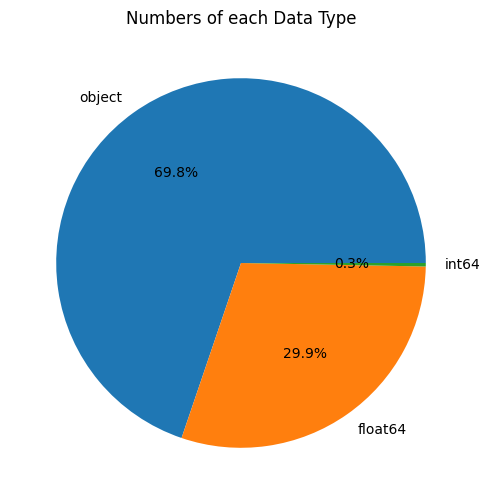

In [7]:
type_counts = df.dtypes.value_counts()

plt.figure(figsize=(7,6))
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%')
plt.title("Numbers of each Data Type")
plt.show()

In [8]:
#df = df.sample(n=100000, random_state=42)

In [9]:
df.shape


(491775, 331)

#***Ratio Missing***

---


##**calculating number of columns that have ratio missing values more than 0.5, and list these columns.**

In [10]:
missing_ratio = df.isna().mean()
high_missing = missing_ratio[missing_ratio > 0.5]
print('high missing',len(high_missing))
print(list(high_missing.index))

high missing 140
['colghous', 'ladult', 'bpmeds', 'asthnow', 'numphon2', 'pregnant', 'smokday2', 'stopsmk2', 'lastsmk2', 'avedrnk2', 'drnk3ge5', 'maxdrnks', 'exeroft2', 'exerhmm2', 'lmtjoin3', 'arthdis2', 'arthsocl', 'joinpain', 'flshtmy2', 'hivtstd3', 'whrtst10', 'pdiabtst', 'prediab1', 'diabage2', 'insulin', 'bldsugar', 'feetchk2', 'doctdiab', 'chkhemo3', 'feetchk', 'eyeexam', 'diabeye', 'diabedu', 'painact2', 'qlmentl2', 'qlstres2', 'qlhlth2', 'dlyother', 'lstcovrg', 'ssbsugar', 'ssbfrut2', 'wtchsalt', 'longwtch', 'dradvise', 'asthmage', 'asattack', 'aservist', 'asdrvist', 'asrchkup', 'asactlim', 'asymptom', 'asnoslep', 'asthmed3', 'asinhalr', 'harehab1', 'strehab1', 'cvdasprn', 'aspunsaf', 'rlivpain', 'rduchart', 'rducstrk', 'arttoday', 'arthwgt', 'arthexer', 'arthedu', 'imfvplac', 'hpvadvc2', 'hpvadsht', 'hadmam', 'howlong', 'profexam', 'lengexam', 'hadpap2', 'lastpap2', 'hadhyst2', 'bldstool', 'lstblds3', 'hadsigm3', 'hadsgco1', 'lastsig3', 'pcpsaad2', 'pcpsadi1', 'pcpsare1', 'ps

#***Handly drpped unrelated columns.***

---


##**Naming features that not related, and doesn't help in the data**

In [11]:
columns_to_drop = [
    'X_state','fmonth','idate','imonth','iday','iyear','Unnamed: 0',
    'dispcode','seqno','X_psu','ctelenum','pvtresd1','colghous','stateres','cellfon3',
    'ladult','numadult','nummen','numwomen',

    'ctelnum1','cellfon2','cadult','pvtresd2','cclghous','cstate','landline','pctcell',

    'mscode','X_ststr','X_strwt','X_rawrake','X_wt2rake',

    'X_cllcpwt','X_dualuse','X_dualcor','X_llcpwt2','X_llcpwt','medcost', 'delaymed',
    'dlyother','X_impeduc', 'X_impmrtl','X_imphome','numphon2','income2', 'educa',
    'numphon2', 'numhhol2', 'pcpsars1','smokday2','lstcovrg','carercvd',
    'asthmed3','lengexam','lastpap2','hlthpln1','persdoc2','veteran3',
    'employ1','cpdemo1','internet','renthom1','useequip','diffwalk','diffdres','diffalon','addepev2',
    'usenow3','exract21','seatbelt','tetanus','whrtst10','pdiabtst',
    'medicare','hlthcvrg','nocov121','medscost','medbills','dradvise',
    'asinhalr','harehab1','strehab1','aspunsaf','arthedu','imfvplac','hpvadvc2','hpvadsht','hadmam',
    'howlong','lstblds3','lastsig3','pcpsaad2','pcpsadi1','pcpsare1','psatime','pcpsade1','rrclass2','rrcognt2',
    'rratwrk2','rrhcare3','rrphysm2','rremtsm2','mistrhlp','scntmony','scntmeal','scntpaid','scntlpad',
    'scntvot1','rcsgendr','rcsrltn2','casthdx2','casthno2','qstver','qstlang',
    'flshtmy2','asymptom',
    'arttoday','misphlpf','X_imprace','X_chispnc','X_crace1','X_impcage','X_impcrac',
    'X_cholchk','X_prace1','X_mrace1','X_hispanc','X_race','X_raceg21','X_racegr3',
    'X_race_g1','X_chldcnt','X_educag','X_incomg','X_smoker3','X_misvegn','X_frtresp',
    'X_vegresp','X_frtlt1','X_veglt1','X_frt16','X_veg23','X_fruitex','X_rfseat3',
    'X_rfseat2','X_lmtscl1','X_lmtwrk1','X_lmtact1','X_parec1','X_hcvu651','lastsmk2','X_vegetex',
    'X_age65yr','X_ageg5yr','X_age_g','X_misfrtn','X_pa150r2','X_pa300r2','X_pa30021','X_pastae1','exract11',
    'children','X_bmi5','pa1vigm_','pavig11_','frutda1_']

#***Drop these columns.***

---



In [12]:
df_clean = df.drop(columns=columns_to_drop)

print('Number of columns after dropping process:',len(df_clean.columns))
df_clean.head()

Number of columns after dropping process: 166


,genhlth,physhlth,menthlth,poorhlth,checkup1,sleptim1,bphigh4,bpmeds,bloodcho,cholchk,...,pamin21_,pa1min_,pavig21_,X_pacat1,X_paindx1,X_pastrng,X_flshot6,X_pneumo2,X_aidtst3,X_age80
0,Fair,30.0,29.0,30.0,Within past year,NaN,Yes,Yes,Yes,Within past year,...,NaN,NaN,NaN,Inactive,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,NaN,NaN,No,60.0
1,Good,0.0,0.0,NaN,Within past year,6.0,No,NaN,Yes,Within past year,...,10.0,110.0,0.0,Insufficiently active,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,NaN,NaN,Yes,50.0
2,Good,3.0,2.0,0.0,Within past year,9.0,No,NaN,Yes,5 or more years ago,...,NaN,NaN,NaN,Inactive,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,NaN,NaN,Yes,55.0
3,Very good,2.0,0.0,0.0,Within past 2 years,8.0,No,NaN,Yes,Within past year,...,0.0,35.0,0.0,Insufficiently active,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,NaN,NaN,No,64.0
4,Good,10.0,2.0,0.0,5 or more years ago,6.0,Yes,No,Yes,Within past 2 years,...,NaN,NaN,NaN,Inactive,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,No,No,No,66.0


#***converting numerical values that written in object forms***
***like: "90"***

---

## **The result show how the Weight2, diabage2 converted to'***float64***' data type.**

why now? to be included in the numerical columns preprocessing

In [13]:
mixed_numeric_cols = ['weight2', 'diabage2']

for col in mixed_numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

 #resulst
df_clean['weight2'].head(2)

,weight2
0,250.0
1,127.0


#***Correlation Coefficient***

---


##**using correlation to find the columns that similar to each other.**



#**Goal: Remove columns that have same ideas.**

In [14]:
df_num = df_clean.select_dtypes(include=['int64', 'float64'])
print("Numerical columns number:", df_num.shape[1])
corr_matrix = df_num.corr()

high_corr = set()
for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > 0.9:
            colname = corr_matrix.columns[i]
            high_corr.add(colname)

print('High correlation',high_corr)
print("Length of high cottrlation:", len(high_corr))

df_reduced = df_clean.drop(columns=high_corr, errors='ignore')
print( df_reduced.shape)


Numerical columns number: 77
High correlation {'asrchkup', 'X_drnkmo4', 'fc60_', 'scntlwk1', 'padur2_', 'pamin11_', 'X_age80', 'pamin21_', 'padur1_', 'pcdmdecn'}
Length of high cottrlation: 10
(491775, 156)


#***Removing duplicating rows***

---



In [15]:
df_clean.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
491770,False
491771,False
491772,False
491773,False


#***Dropping Null Values.***

---


##**Droping null values **consider the worst** because every row contain NAN, that mean we will remove whole data.**


##***solution: fill Null values***



In [16]:
df_reduced_test_dropna=df_reduced.dropna()
df_reduced_test_dropna.shape

(0, 156)

#***Fill Missing Values.***

---


##**we will use median with numerical data to reduce effecting with outliers**
**(working with object separatly working with integer)**


In [17]:
numeric = df_reduced.select_dtypes(include=['int64','float64'])
numeric = numeric.fillna(numeric.median())
df_reduced[numeric.columns] = numeric
df_reduced[numeric.columns]



,physhlth,menthlth,poorhlth,sleptim1,weight2,height3,cpdemo4,alcday5,avedrnk2,drnk3ge5,...,metvl21_,maxvo2_,pafreq1_,pafreq2_,X_minac11,X_minac21,strfreq_,pamiss1_,pa1min_,pavig21_
0,30.0,29.0,30.0,7.0,250.0,507.0,10.0,201.0,2.0,0.0,...,35.0,2580.0,3000.0,2000.0,140.0,30.0,0.0,0.0,240.0,0.0
1,0.0,0.0,0.0,6.0,127.0,510.0,70.0,0.0,2.0,0.0,...,33.0,2950.0,5000.0,1000.0,100.0,10.0,0.0,0.0,110.0,0.0
2,3.0,2.0,0.0,9.0,160.0,504.0,70.0,220.0,4.0,20.0,...,35.0,2765.0,3000.0,2000.0,140.0,30.0,0.0,0.0,240.0,0.0
3,2.0,0.0,0.0,8.0,128.0,504.0,75.0,208.0,2.0,0.0,...,0.0,2432.0,1167.0,2000.0,35.0,0.0,0.0,0.0,35.0,0.0
4,10.0,2.0,0.0,6.0,265.0,600.0,0.0,210.0,2.0,0.0,...,35.0,2370.0,3000.0,2000.0,140.0,30.0,0.0,0.0,240.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491770,14.0,15.0,0.0,6.0,138.0,500.0,30.0,0.0,2.0,0.0,...,35.0,2654.0,3000.0,2000.0,140.0,30.0,0.0,0.0,240.0,0.0
491771,0.0,0.0,0.0,7.0,182.0,503.0,30.0,0.0,2.0,0.0,...,35.0,2590.0,3000.0,2000.0,140.0,30.0,0.0,0.0,240.0,0.0
491772,15.0,20.0,0.0,7.0,157.0,505.0,30.0,0.0,2.0,0.0,...,0.0,3431.0,933.0,2000.0,56.0,0.0,0.0,0.0,56.0,0.0
491773,0.0,0.0,0.0,8.0,130.0,504.0,30.0,0.0,2.0,0.0,...,0.0,3690.0,4000.0,2000.0,240.0,0.0,0.0,0.0,240.0,0.0


#***finding best goal by using correlation***

---
##nested loop to try each columns being the target, and printing columns that have correlation more than 0.5


#***Filling object missing values by Mode() method***

---


##**the purpose of using for loop, in object values it may have multiple mode, so that would cause to fill just one columns.**

In [18]:
categ = df_reduced.select_dtypes(include='object').copy()

for col in categ.columns:
    m = categ[col].mode(dropna=True)
    if not m.empty:
        categ[col] = categ[col].fillna(m.iloc[0])

df_reduced[categ.columns] = categ

df_reduced

,genhlth,physhlth,menthlth,poorhlth,checkup1,sleptim1,bphigh4,bpmeds,bloodcho,cholchk,...,strfreq_,pamiss1_,pa1min_,pavig21_,X_pacat1,X_paindx1,X_pastrng,X_flshot6,X_pneumo2,X_aidtst3
0,Fair,30.0,29.0,30.0,Within past year,7.0,Yes,Yes,Yes,Within past year,...,0.0,0.0,240.0,0.0,Inactive,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,Yes,Yes,No
1,Good,0.0,0.0,0.0,Within past year,6.0,No,Yes,Yes,Within past year,...,0.0,0.0,110.0,0.0,Insufficiently active,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,Yes,Yes,Yes
2,Good,3.0,2.0,0.0,Within past year,9.0,No,Yes,Yes,5 or more years ago,...,0.0,0.0,240.0,0.0,Inactive,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,Yes,Yes,Yes
3,Very good,2.0,0.0,0.0,Within past 2 years,8.0,No,Yes,Yes,Within past year,...,0.0,0.0,35.0,0.0,Insufficiently active,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,Yes,Yes,No
4,Good,10.0,2.0,0.0,5 or more years ago,6.0,Yes,No,Yes,Within past 2 years,...,0.0,0.0,240.0,0.0,Inactive,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,No,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491770,Fair,14.0,15.0,0.0,Within past year,6.0,Yes,Yes,Yes,Within past year,...,0.0,0.0,240.0,0.0,Inactive,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,Yes,Yes,No
491771,Good,0.0,0.0,0.0,Within past year,7.0,No,Yes,Yes,Within past year,...,0.0,0.0,240.0,0.0,Inactive,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,Yes,Yes,No
491772,Fair,15.0,20.0,0.0,Within past year,7.0,No,Yes,Yes,Within past year,...,0.0,0.0,56.0,0.0,Insufficiently active,Did not meet aerobic recommendations,Did not meet muscle strengthening recommendations,Yes,Yes,Yes
491773,Very good,0.0,0.0,0.0,Within past year,8.0,No,Yes,No,Within past year,...,0.0,0.0,240.0,0.0,Active,Met aerobic recommendations,Did not meet muscle strengthening recommendations,Yes,Yes,Yes


#***Final Checking in Null values***

---


##**After filling whole missing values depend on type of data**
##**now checking:  "is there any Null values yet?!"**
# ***Absolutely No! 😎✌***


In [19]:
print(df_reduced.isna().sum())

genhlth      0
physhlth     0
menthlth     0
poorhlth     0
checkup1     0
            ..
X_paindx1    0
X_pastrng    0
X_flshot6    0
X_pneumo2    0
X_aidtst3    0
Length: 156, dtype: int64


#***Outliers Handling***

---



In [20]:
df_before = df_reduced.copy()

In [21]:
def replace_outliers_with_median(col):

    q1, q3 = np.percentile(col, [25, 75])
    iqr = q3 - q1
    lw = q1 - 1.5*iqr
    uw = q3 + 1.5*iqr
    median_val = col.median()
    col = np.where((col < lw) | (col > uw), median_val, col)
    return col

for col in numeric:
    df_reduced[col] = replace_outliers_with_median(df_reduced[col])

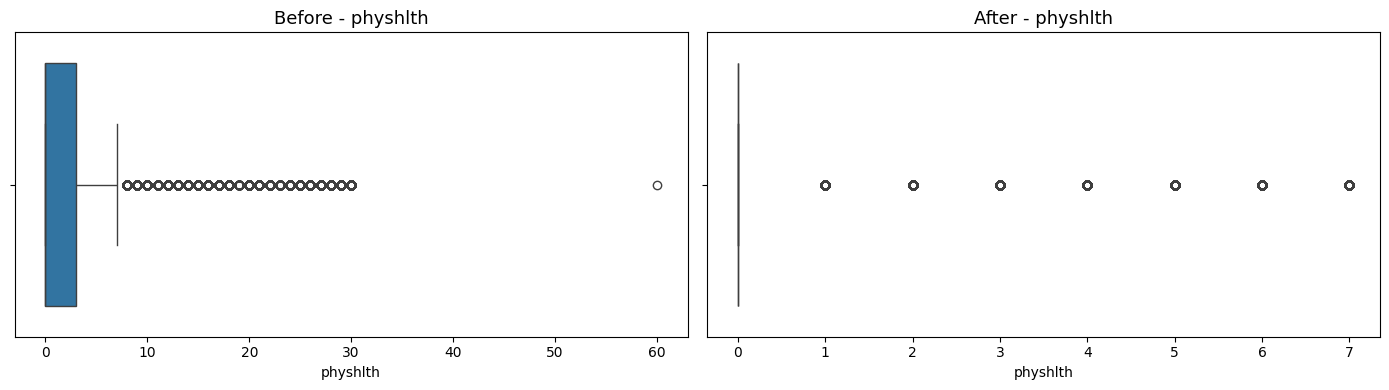

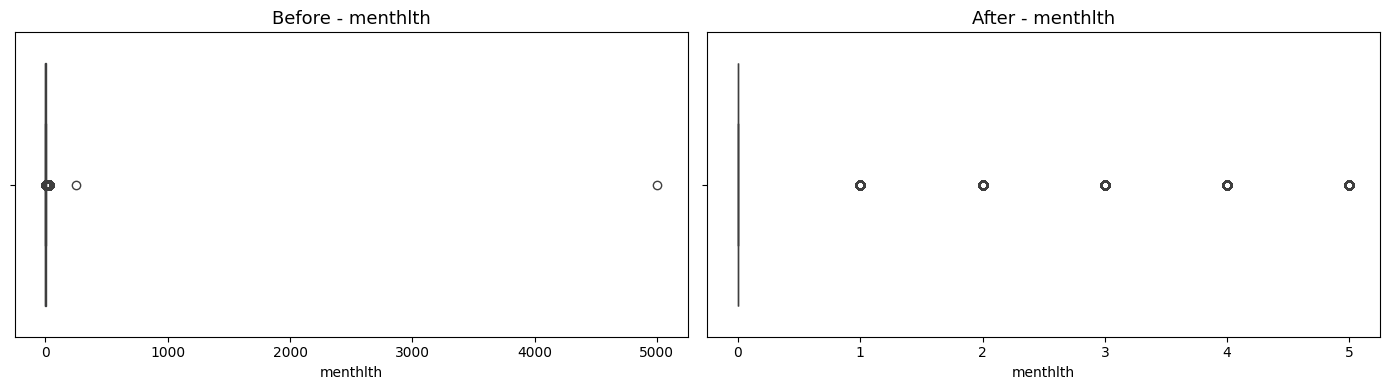

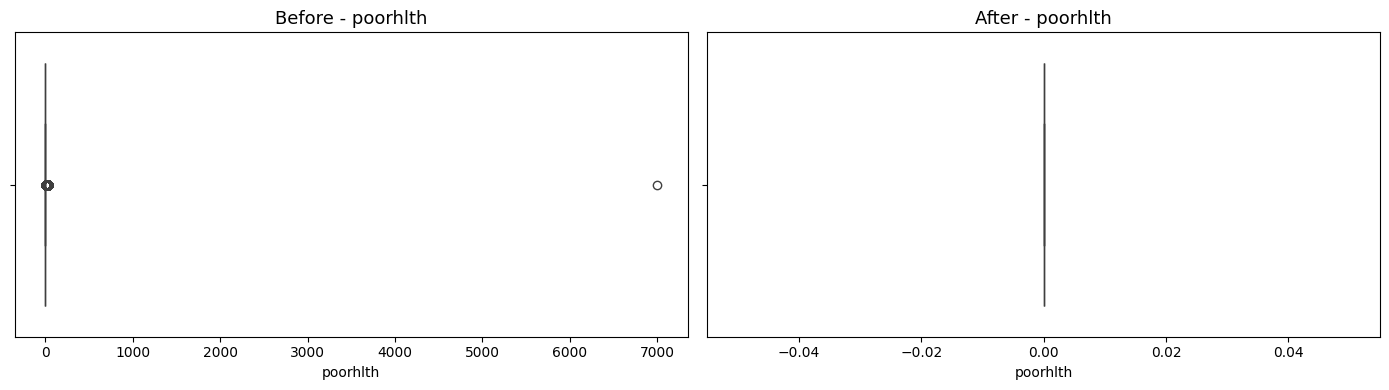

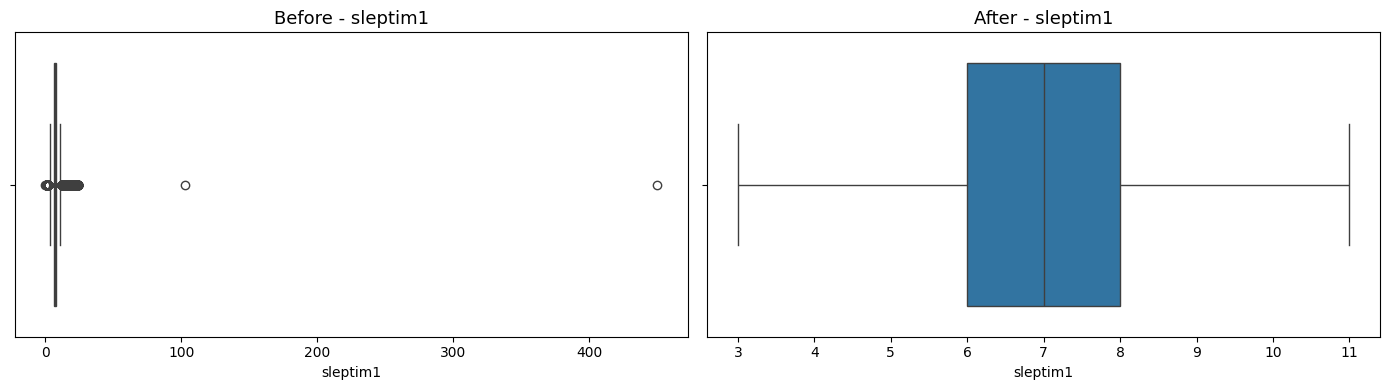

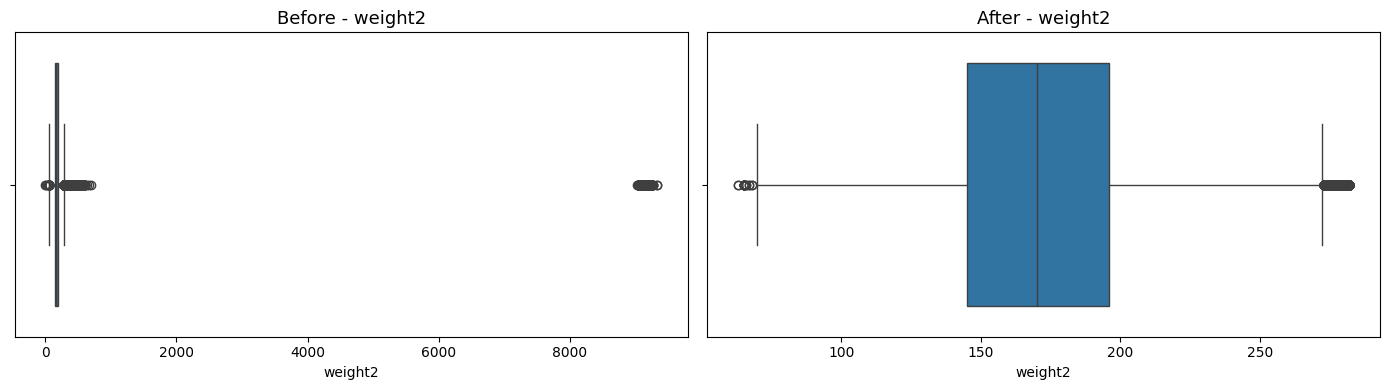

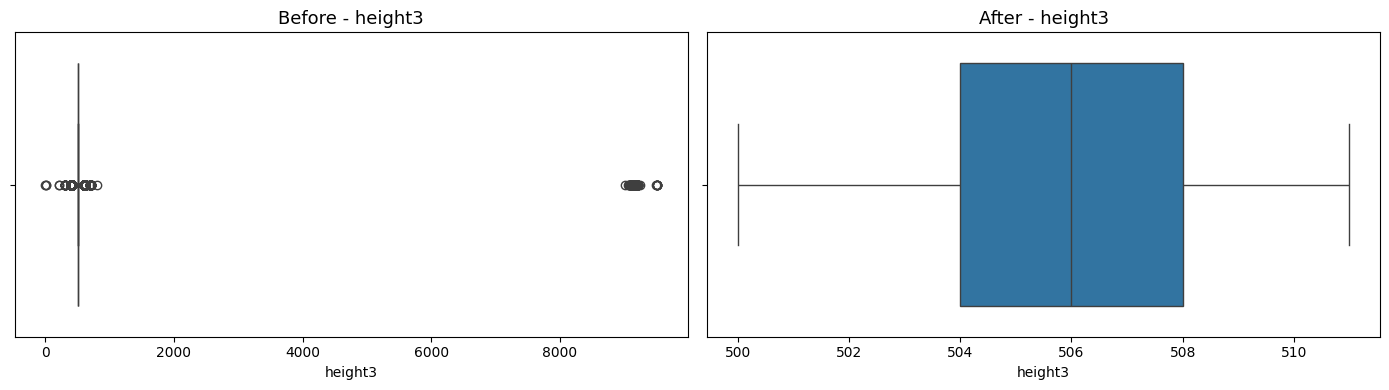

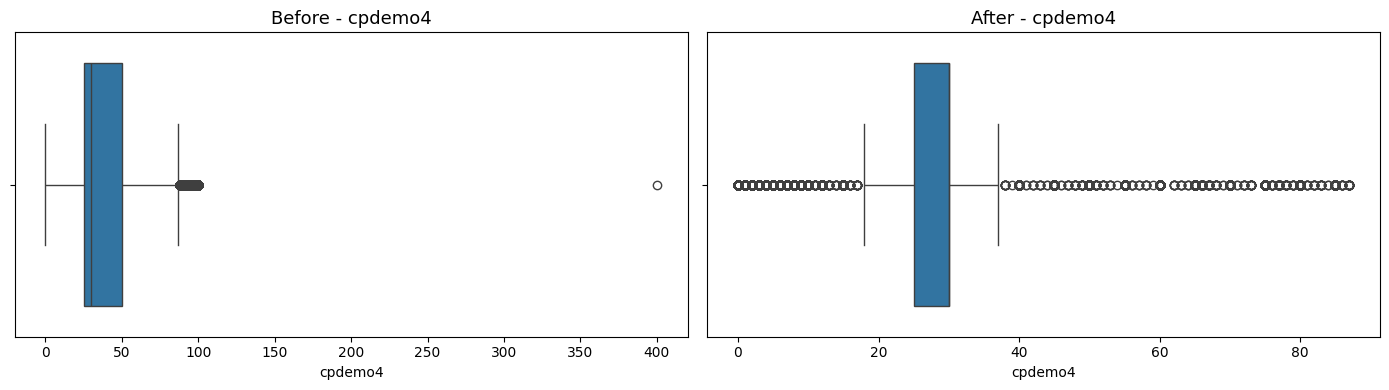

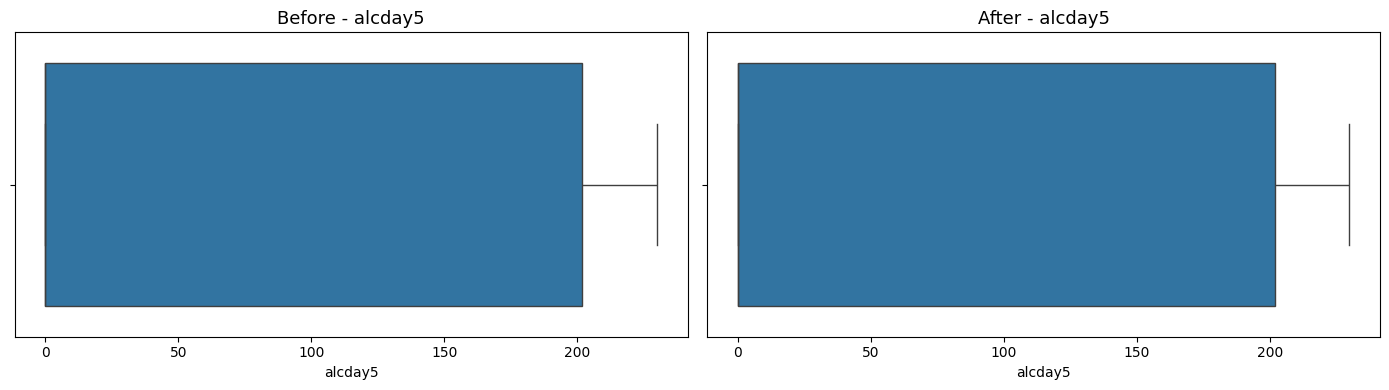

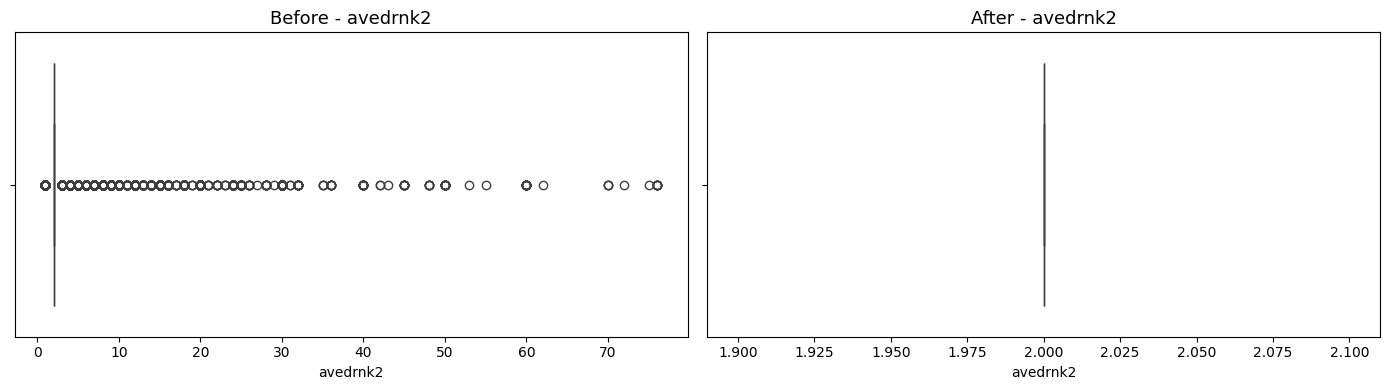

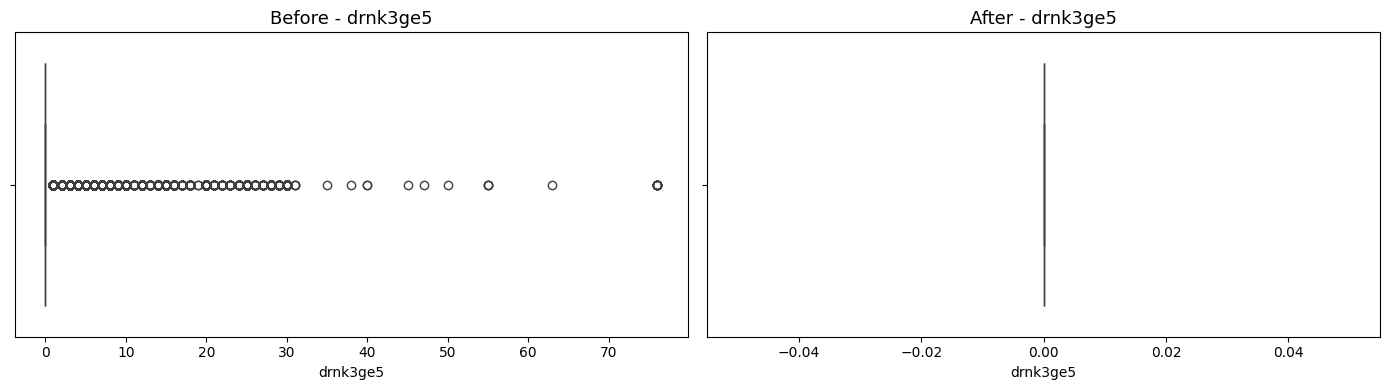

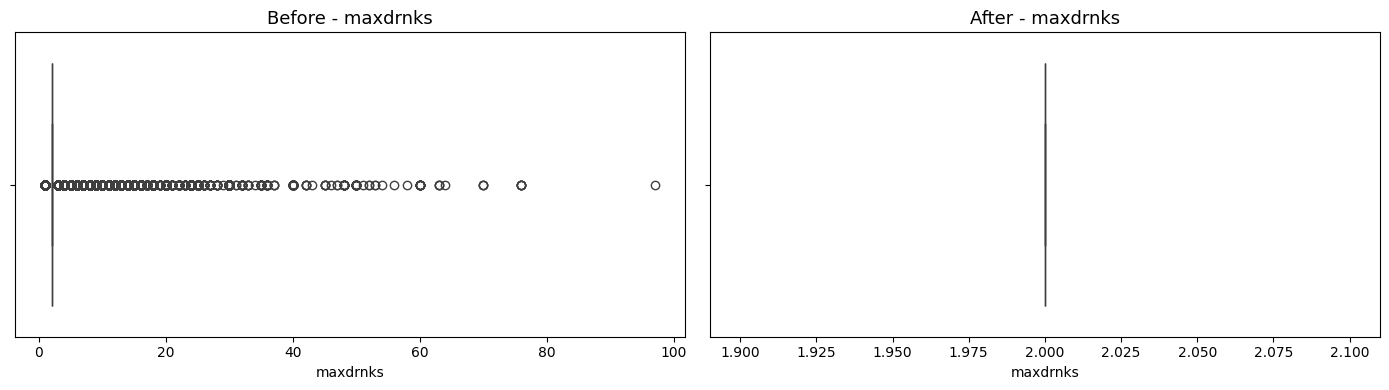

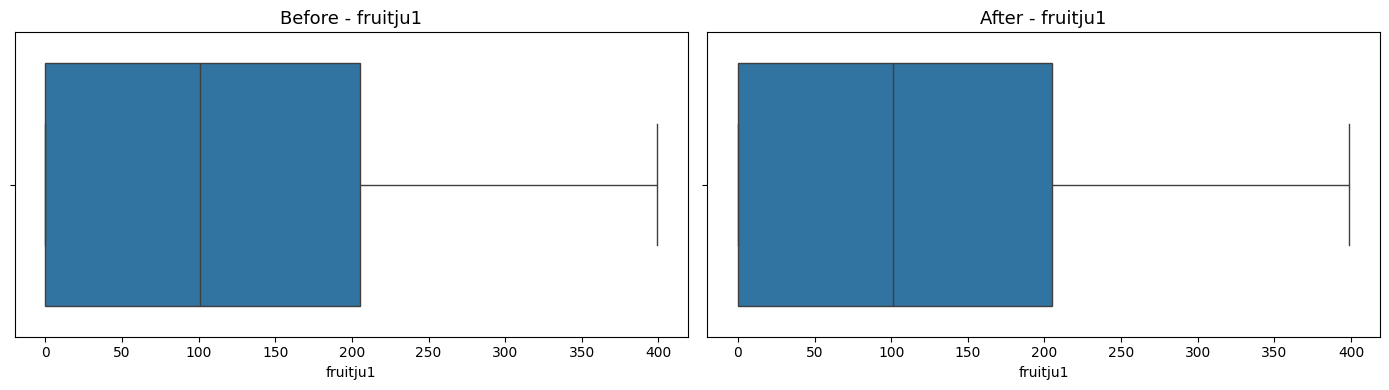

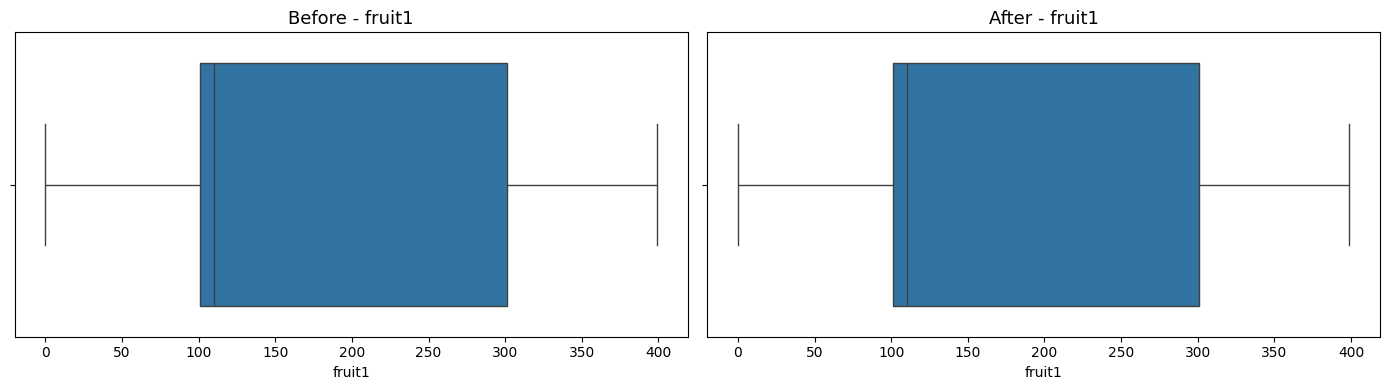

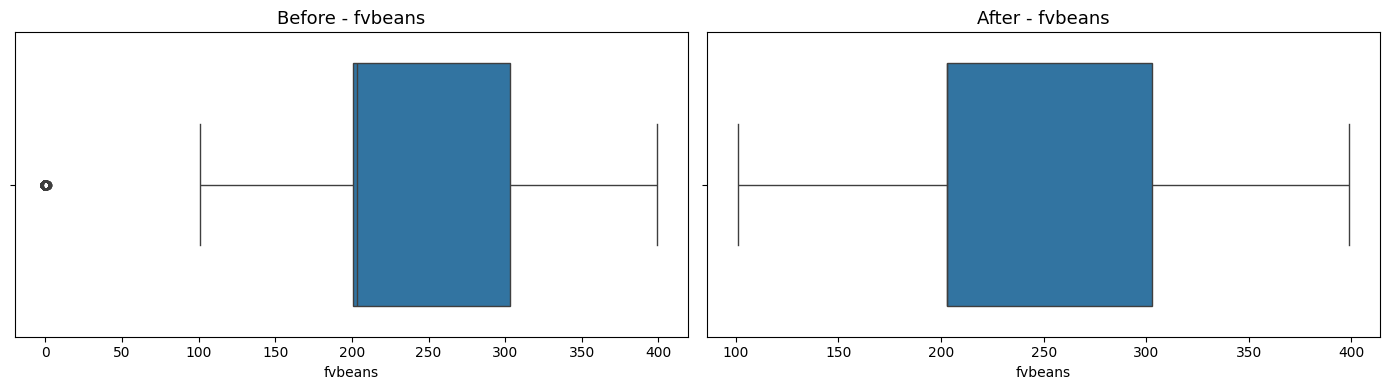

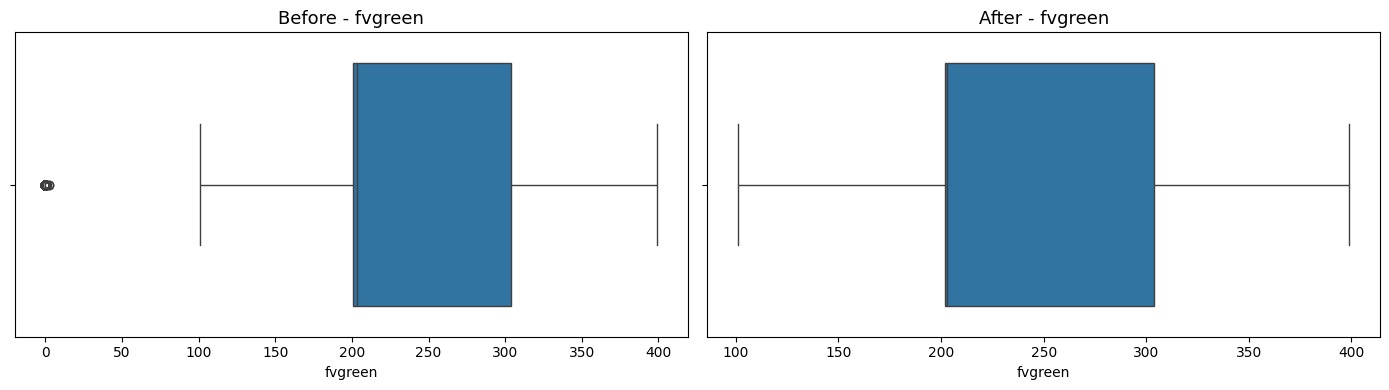

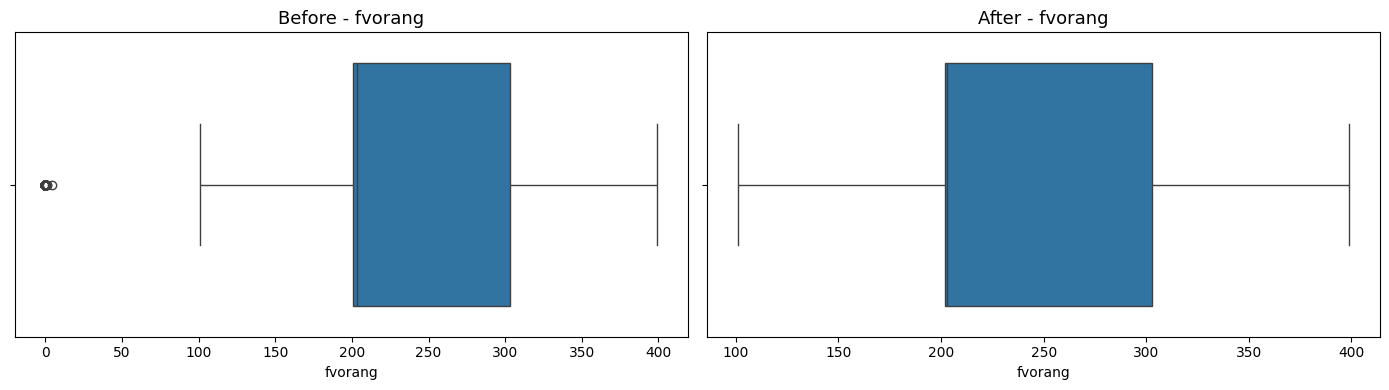

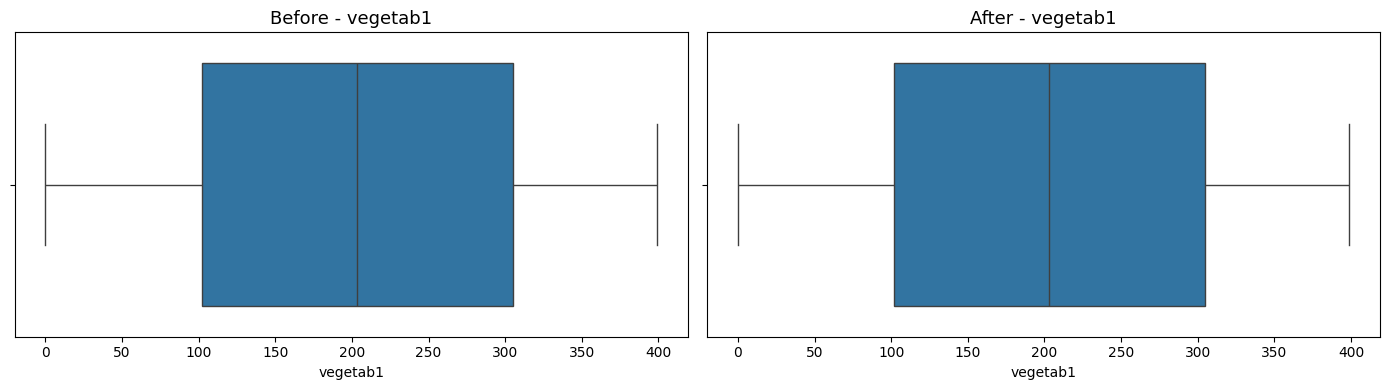

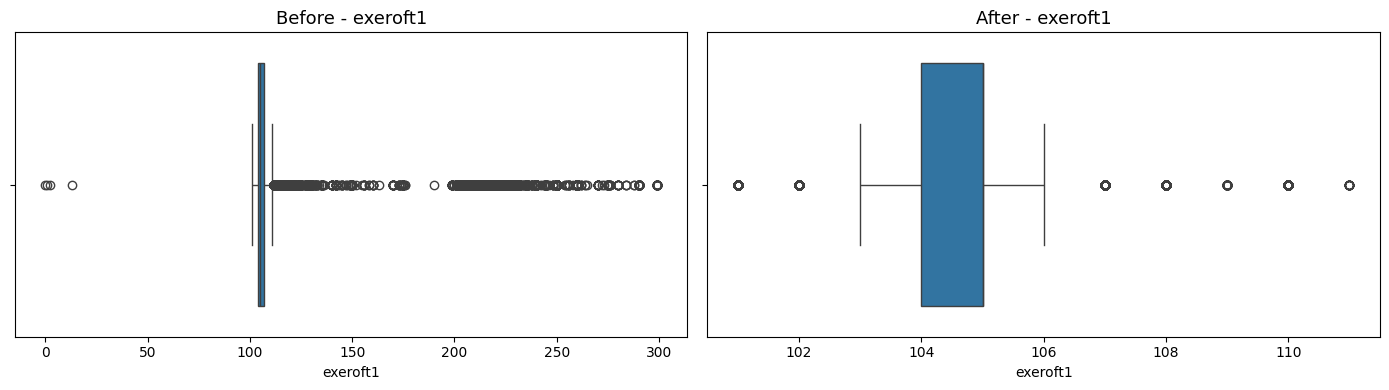

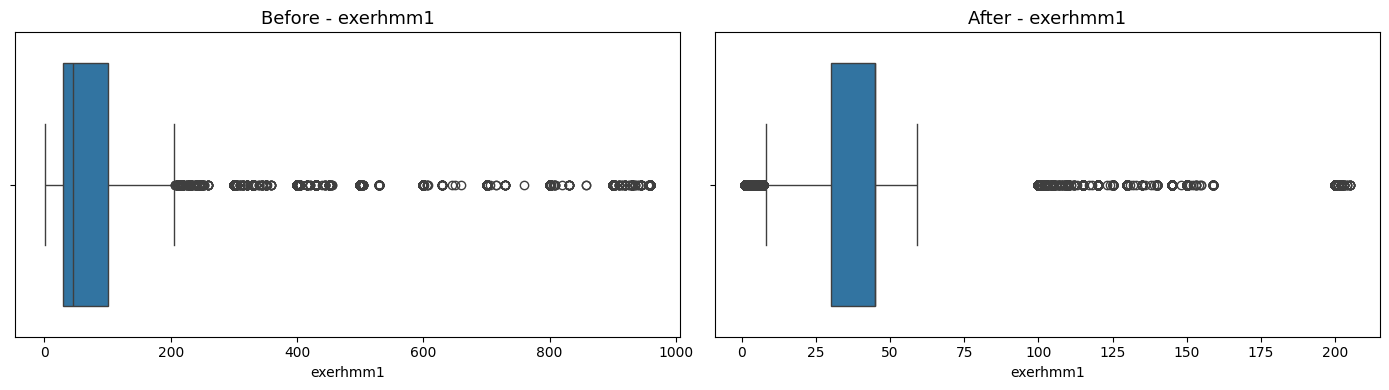

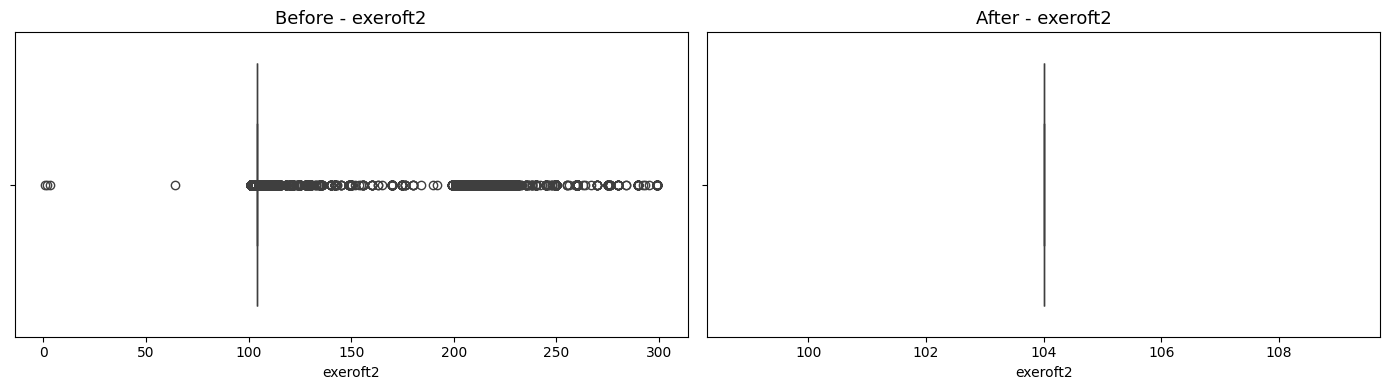

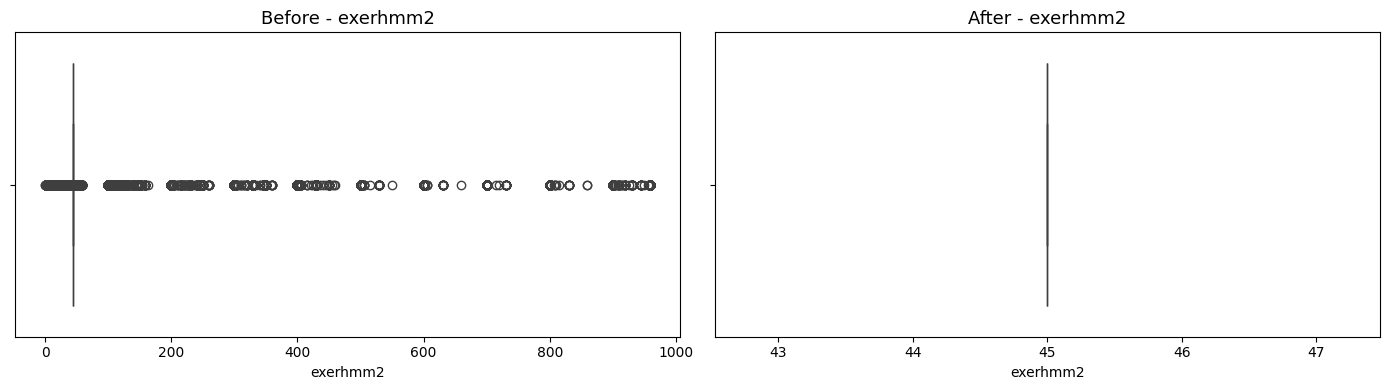

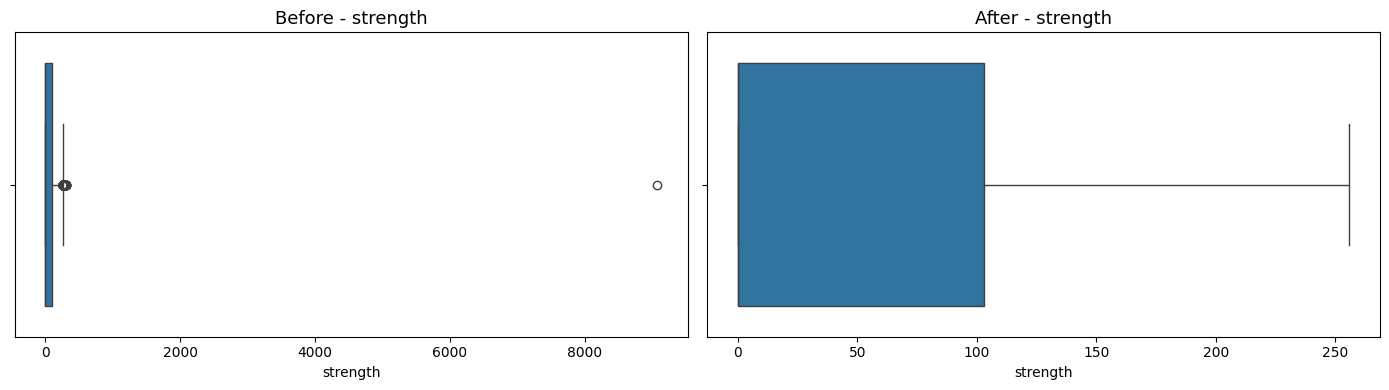

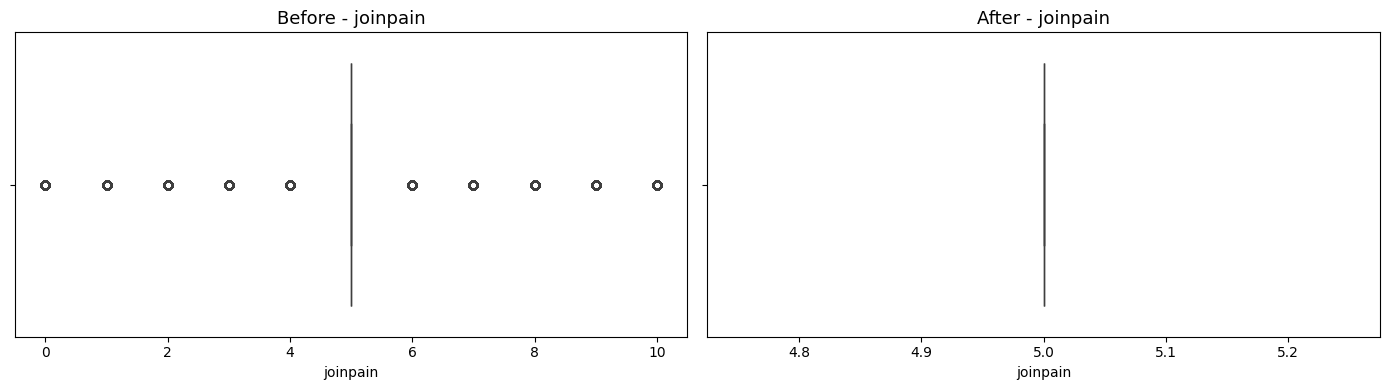

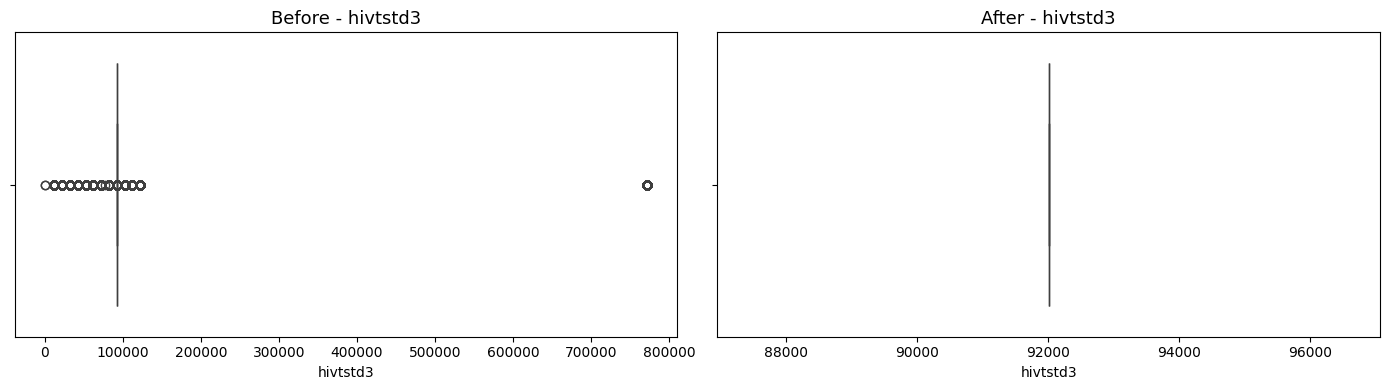

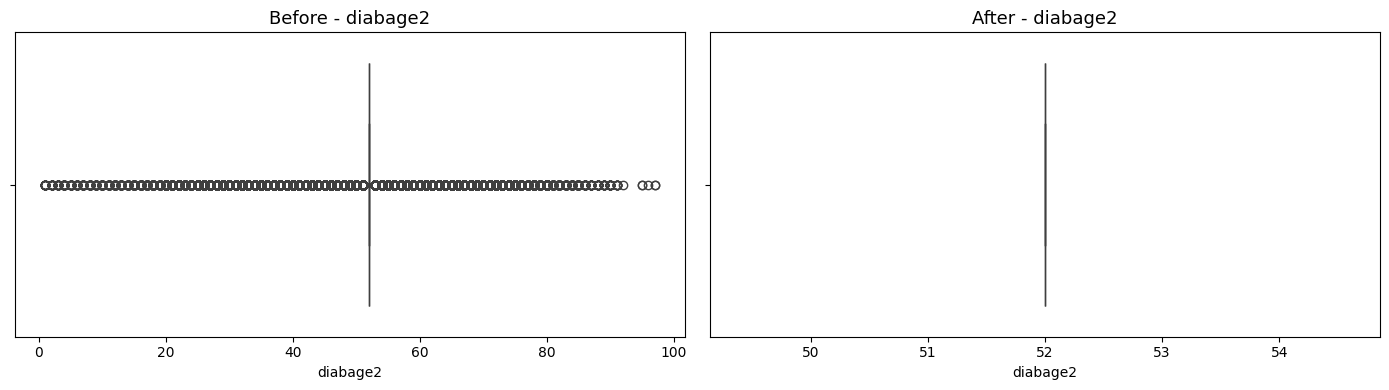

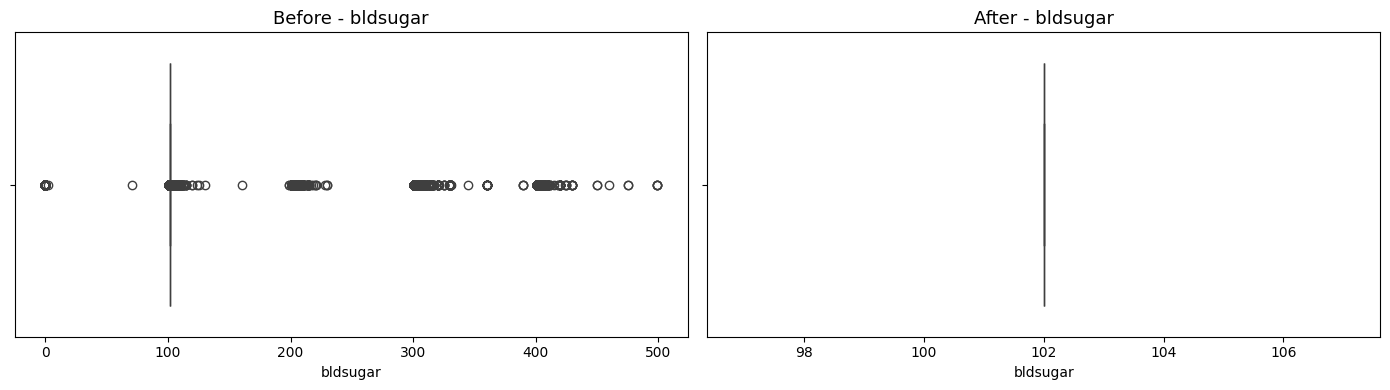

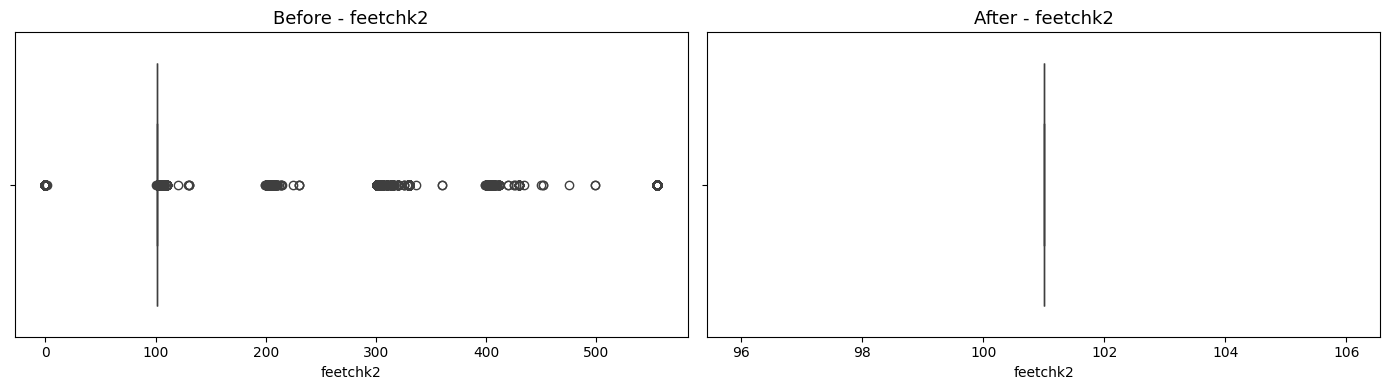

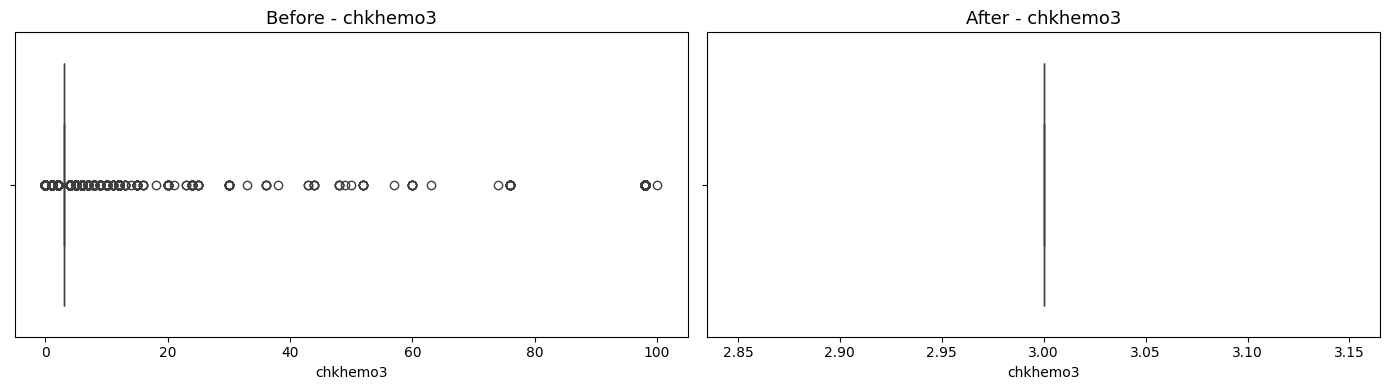

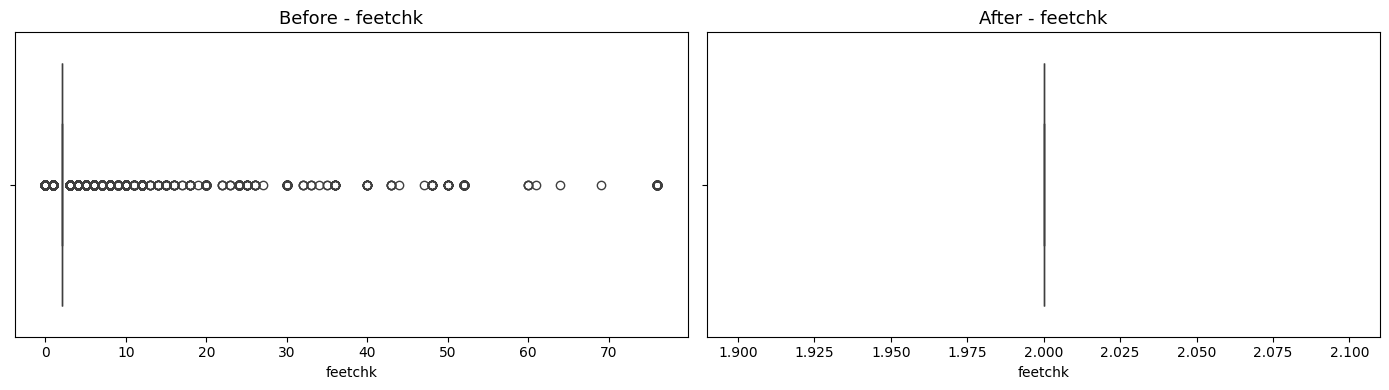

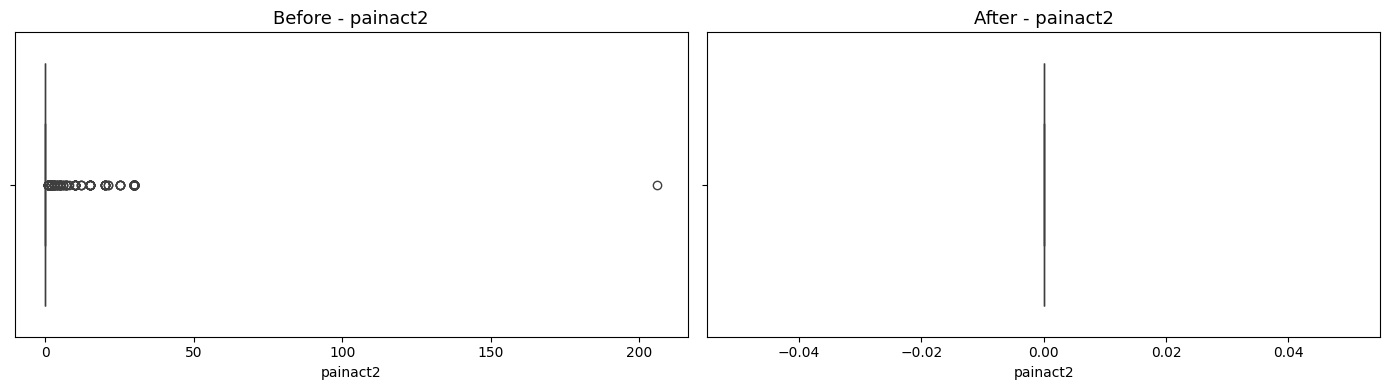

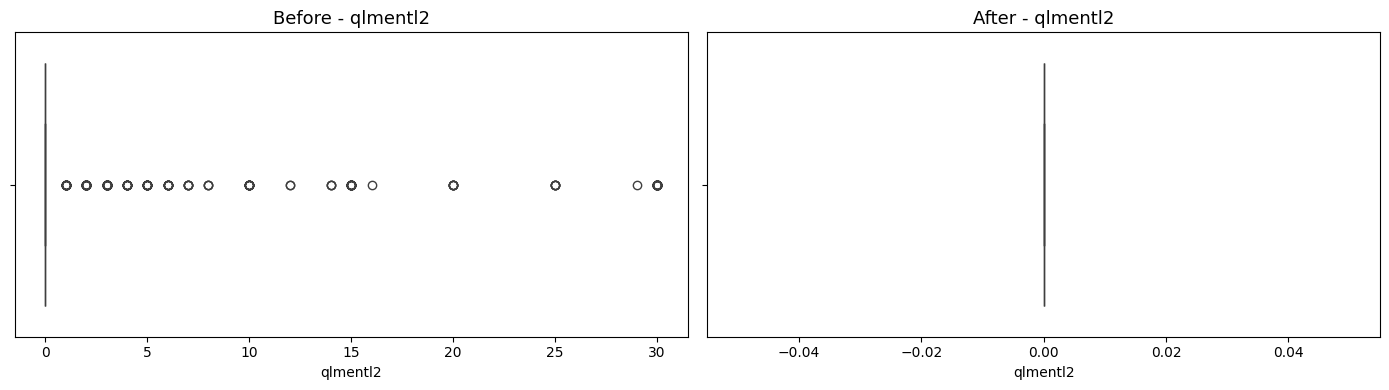

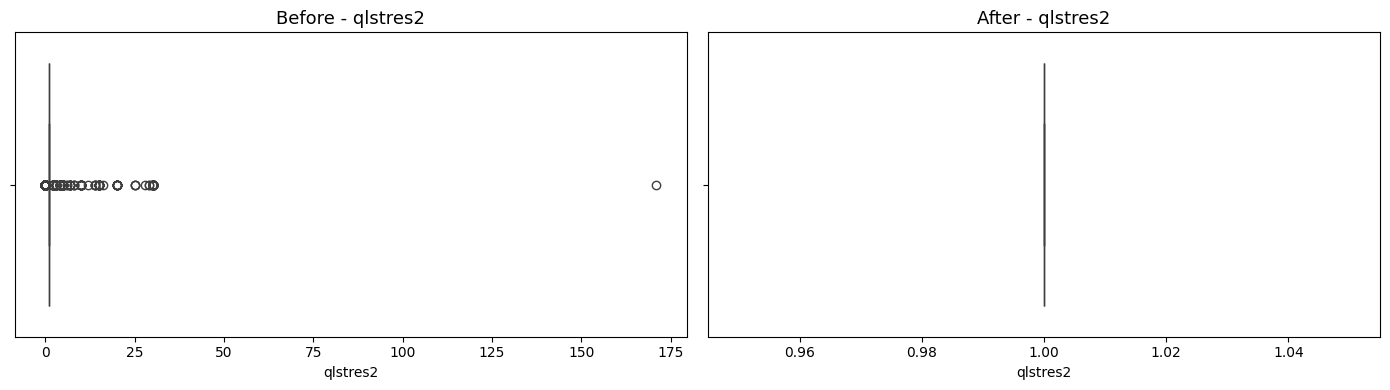

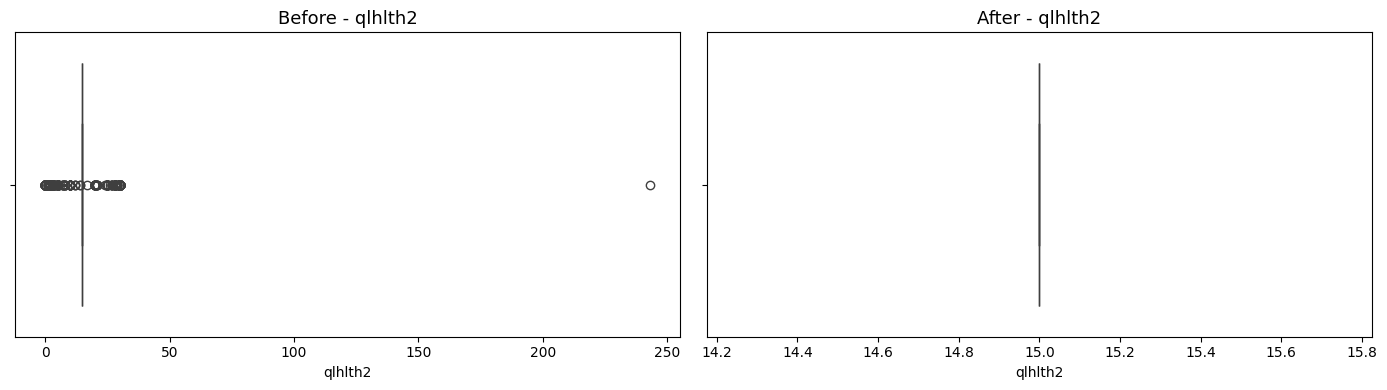

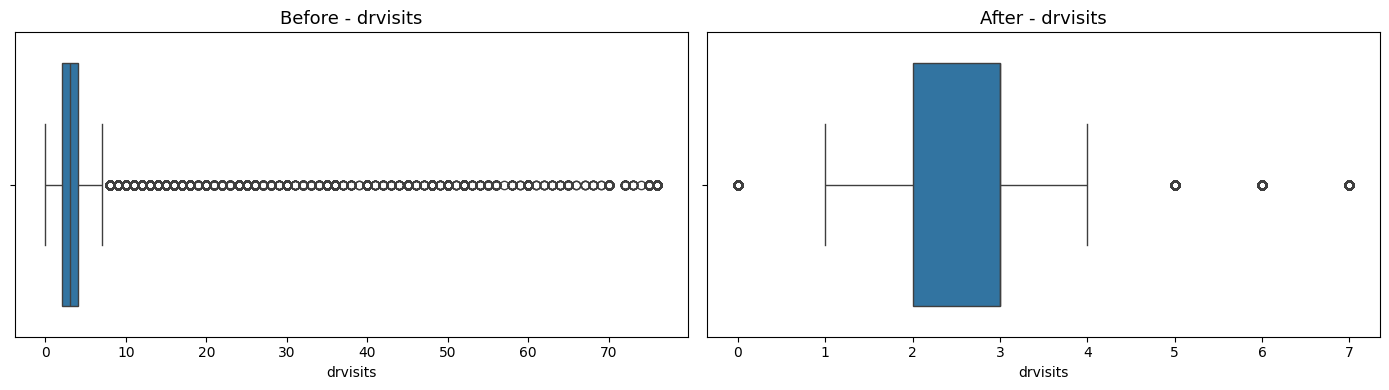

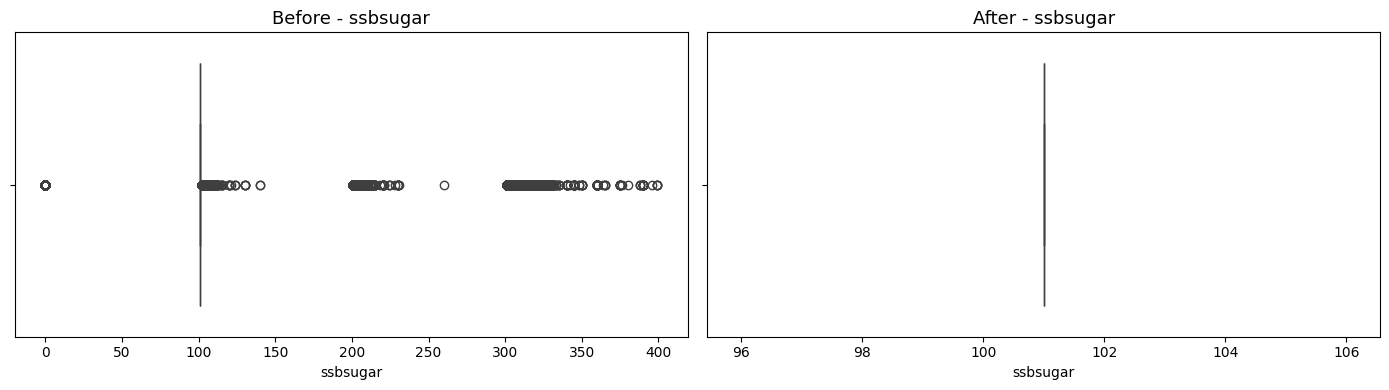

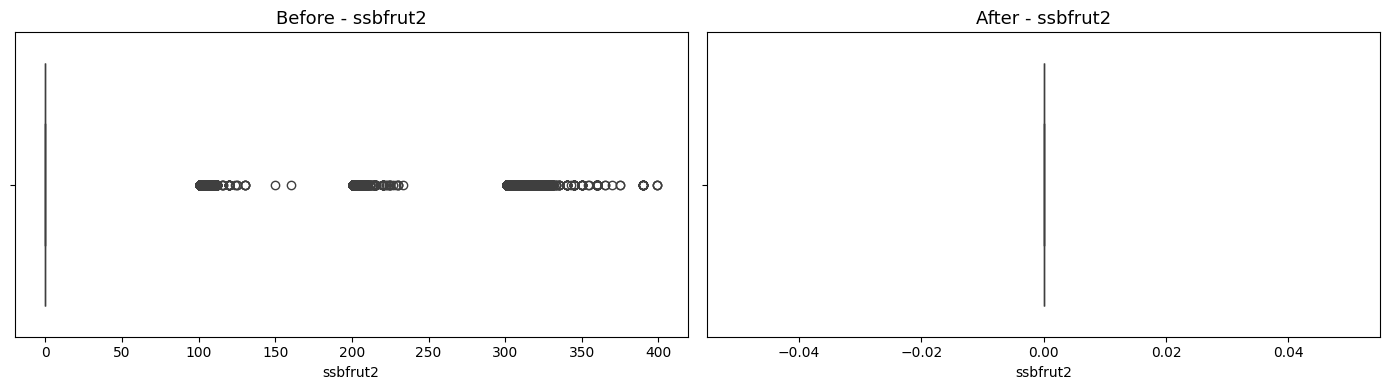

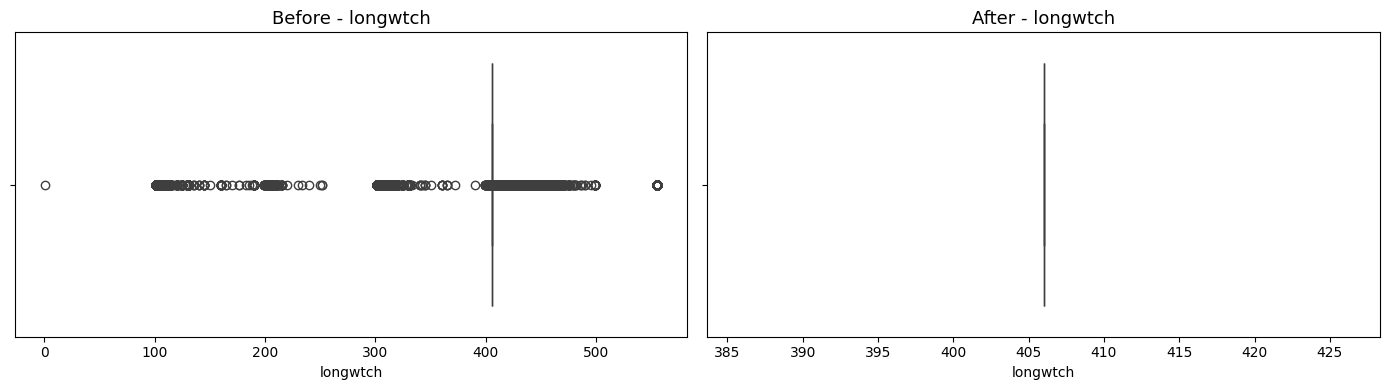

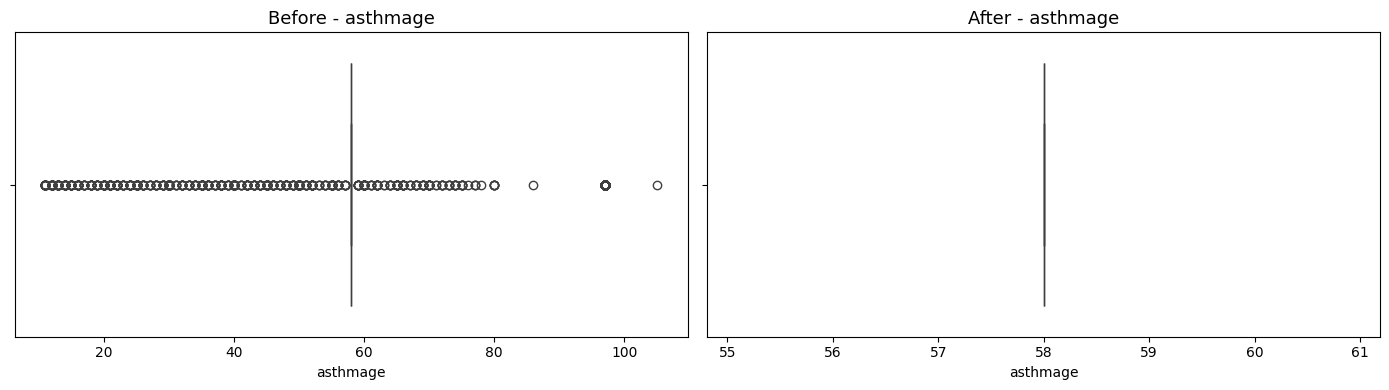

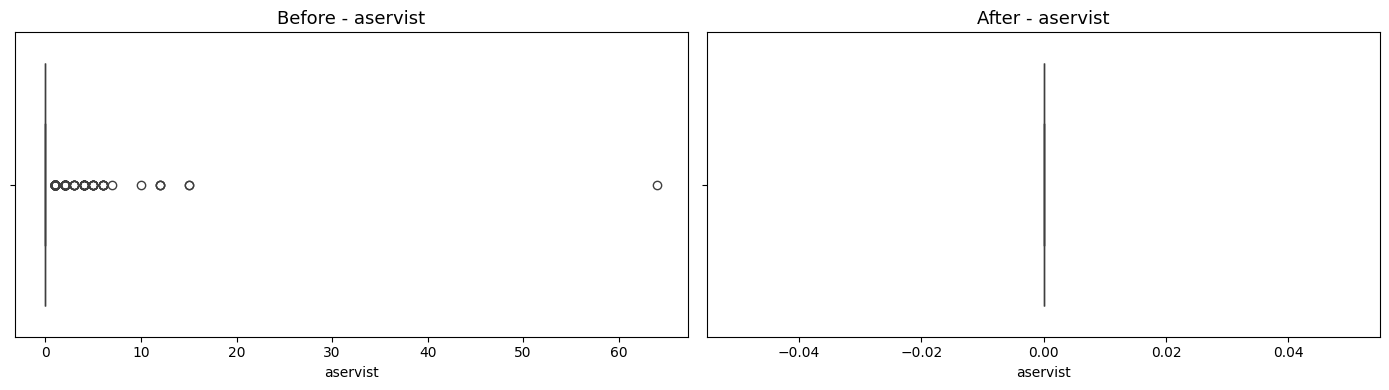

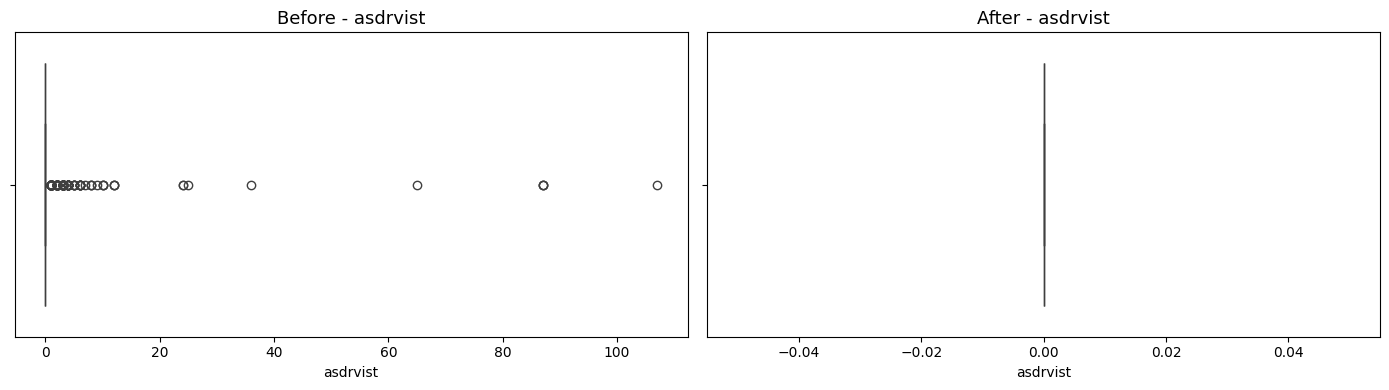

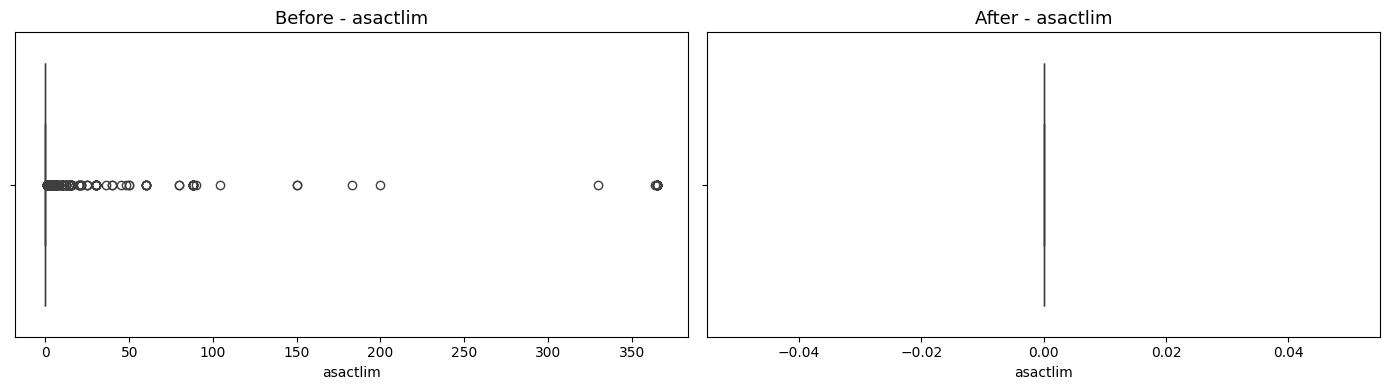

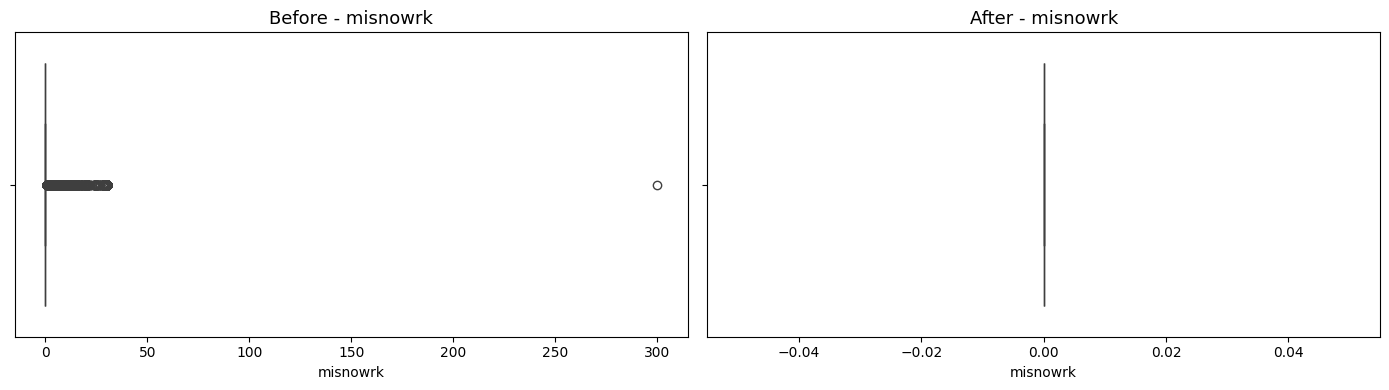

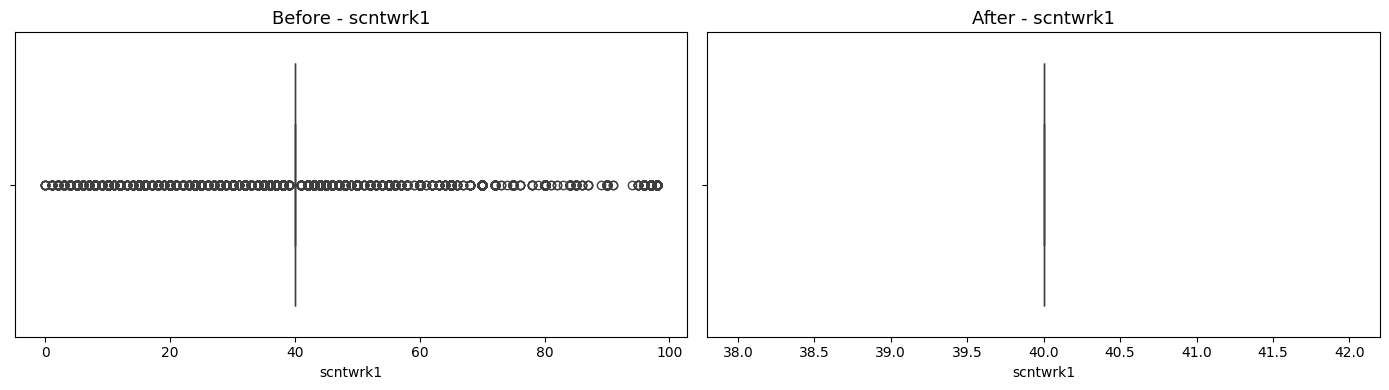

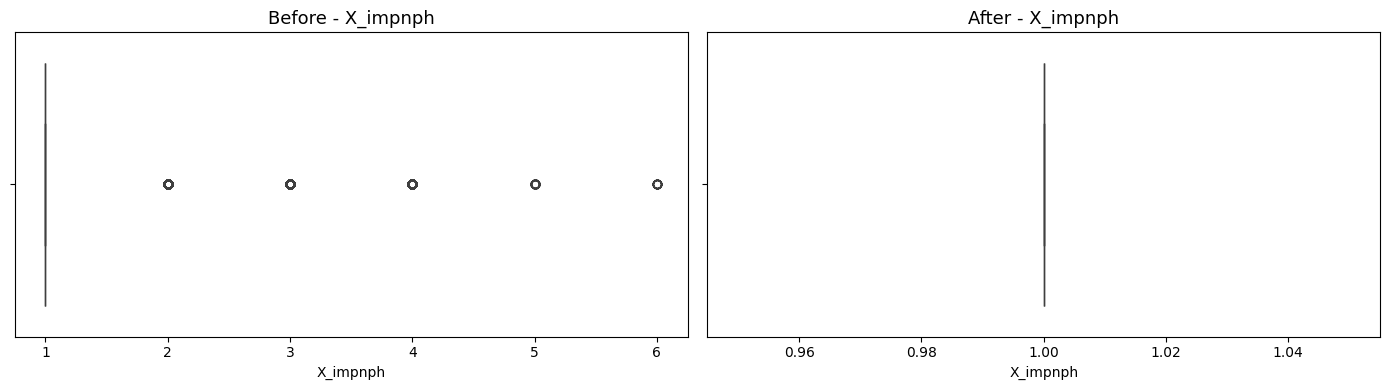

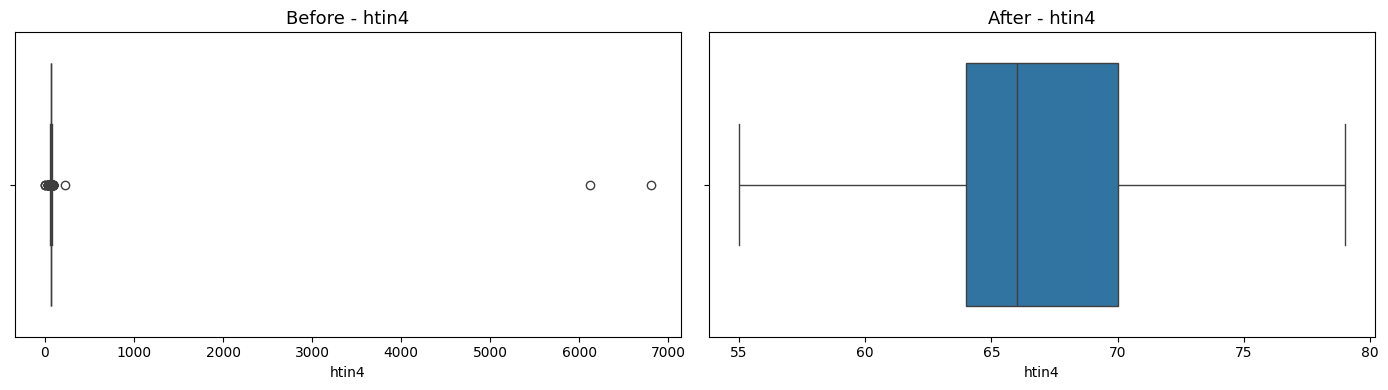

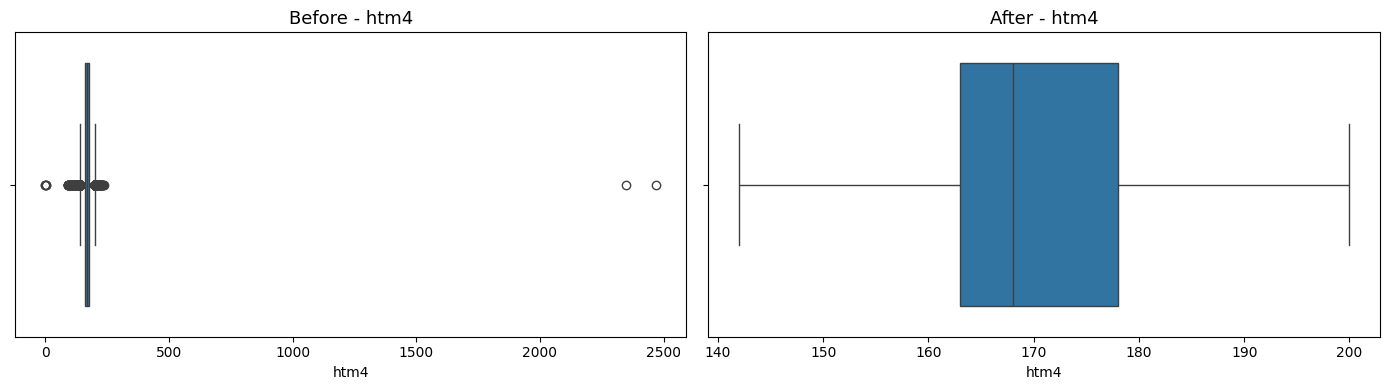

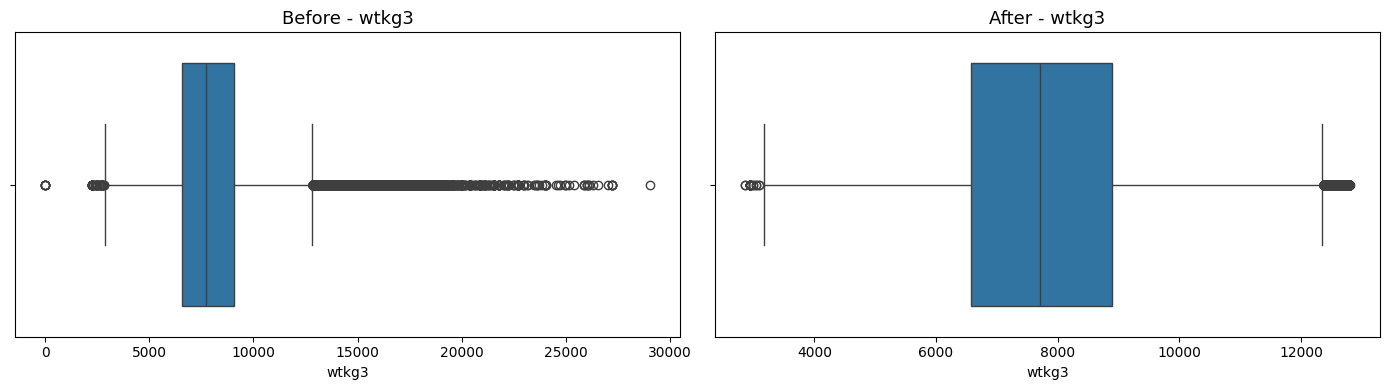

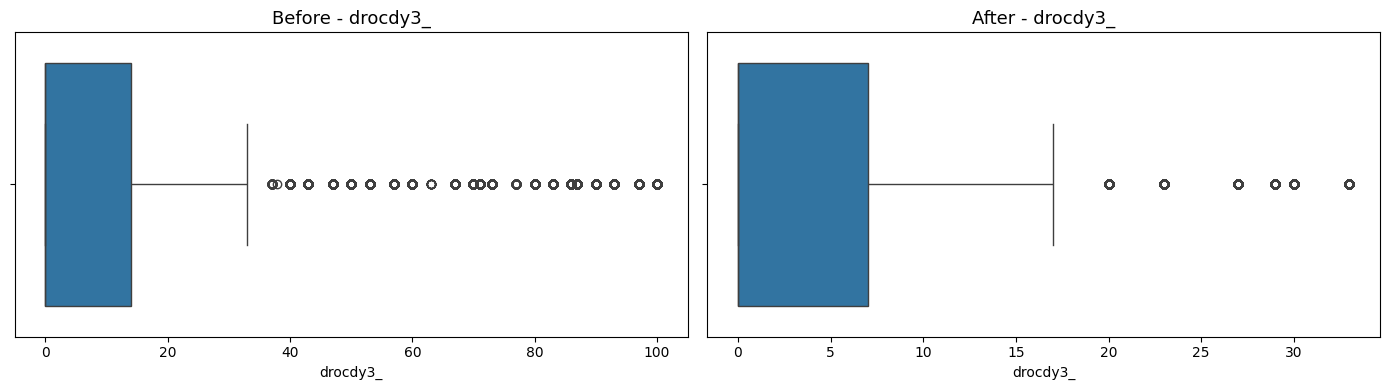

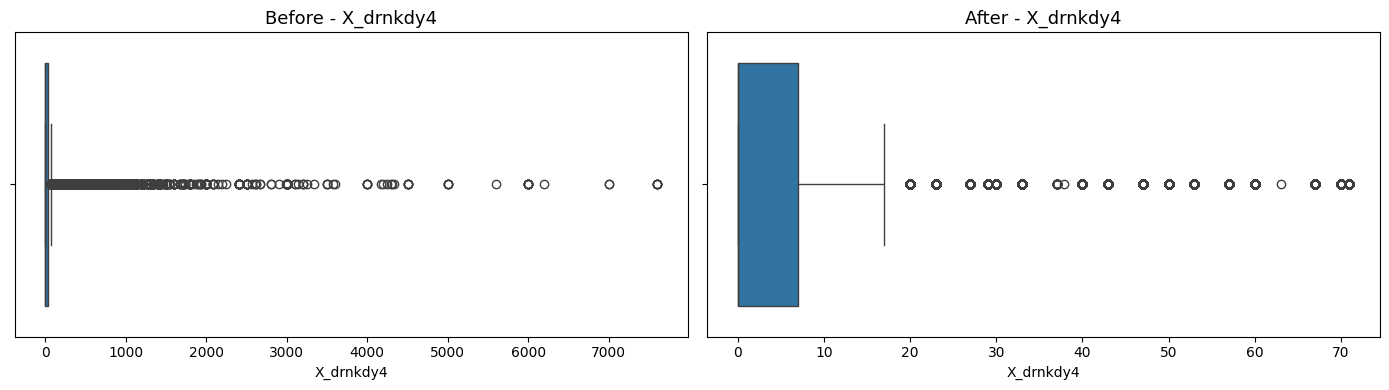

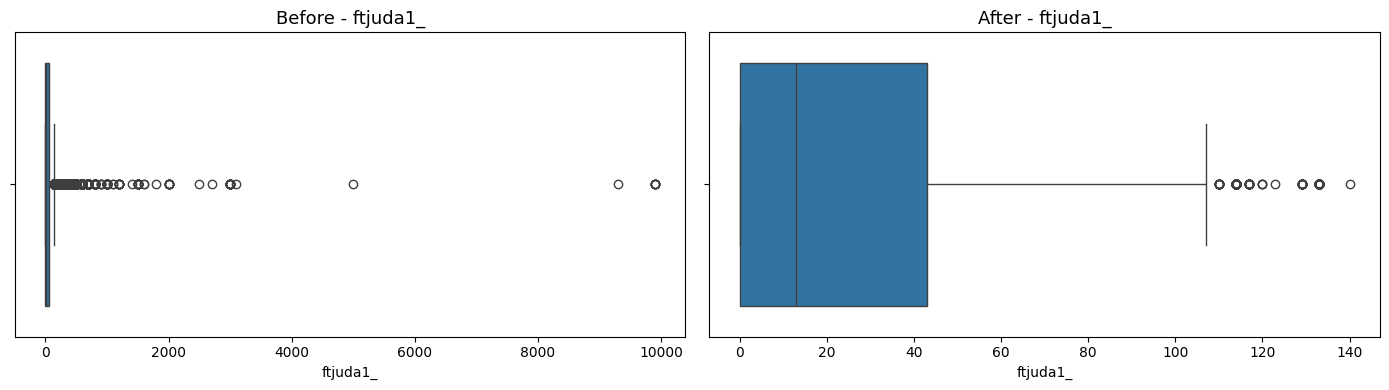

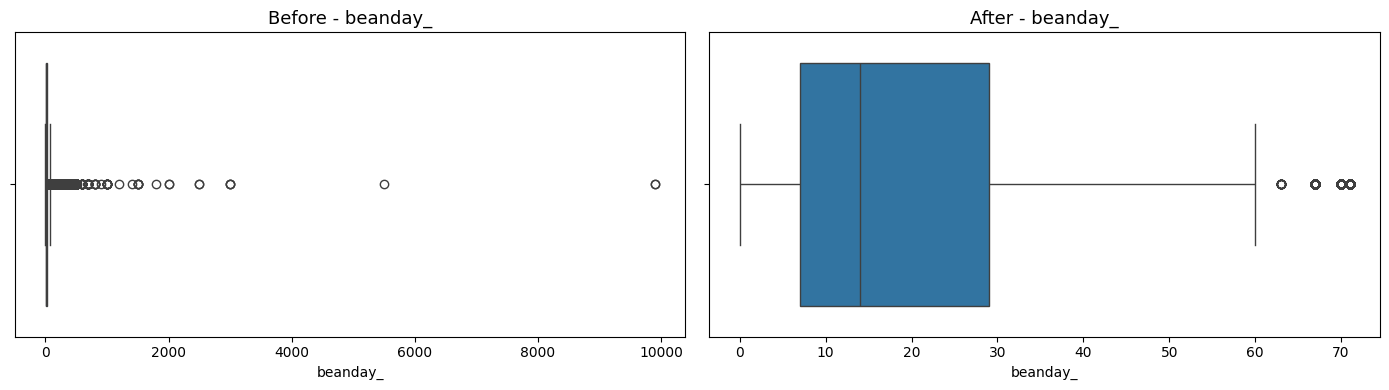

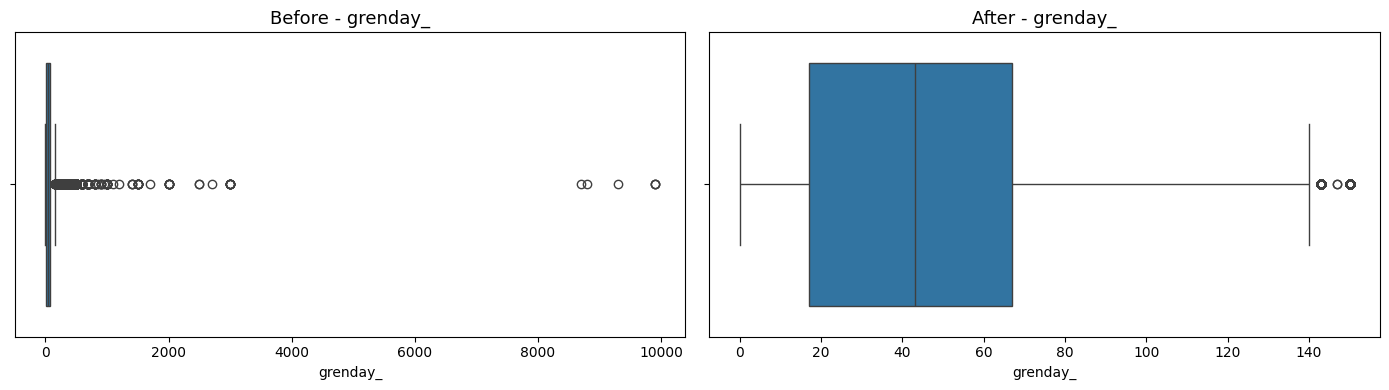

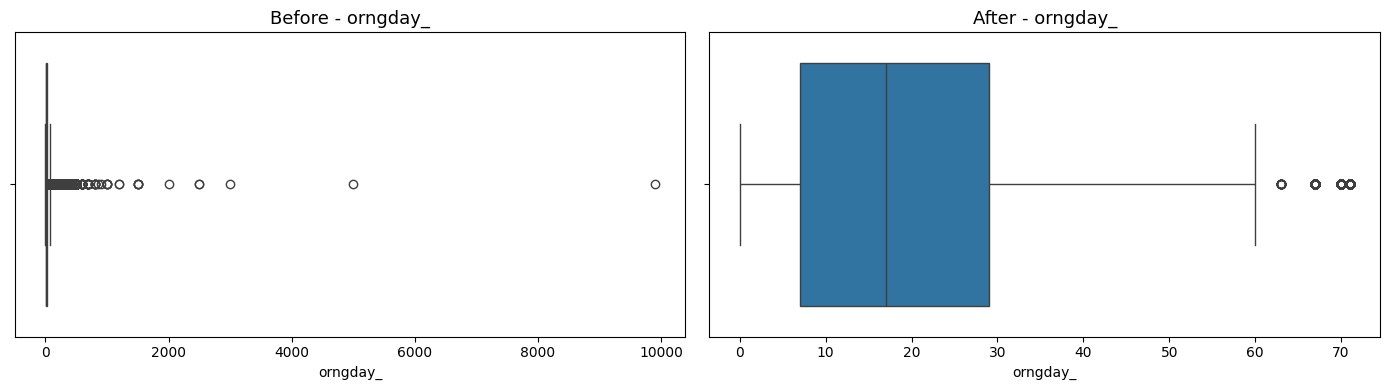

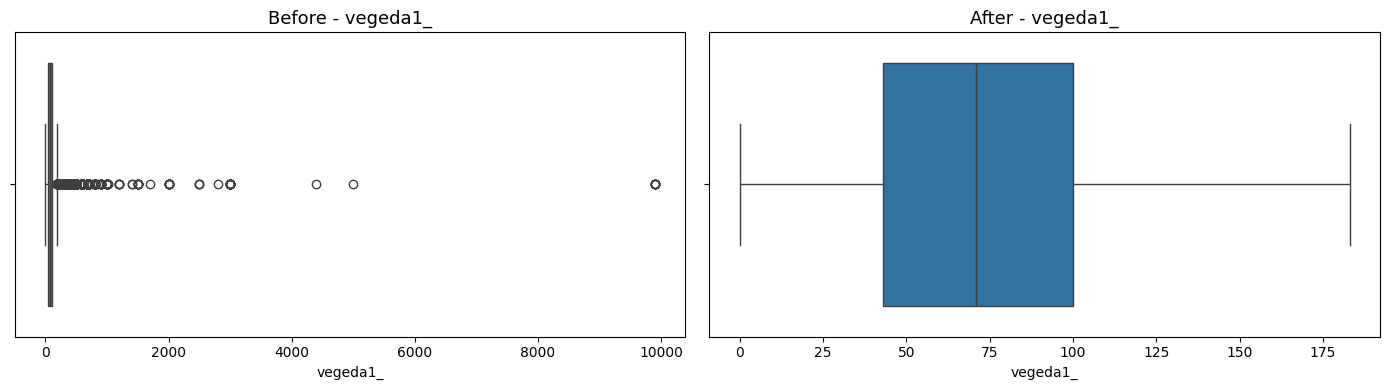

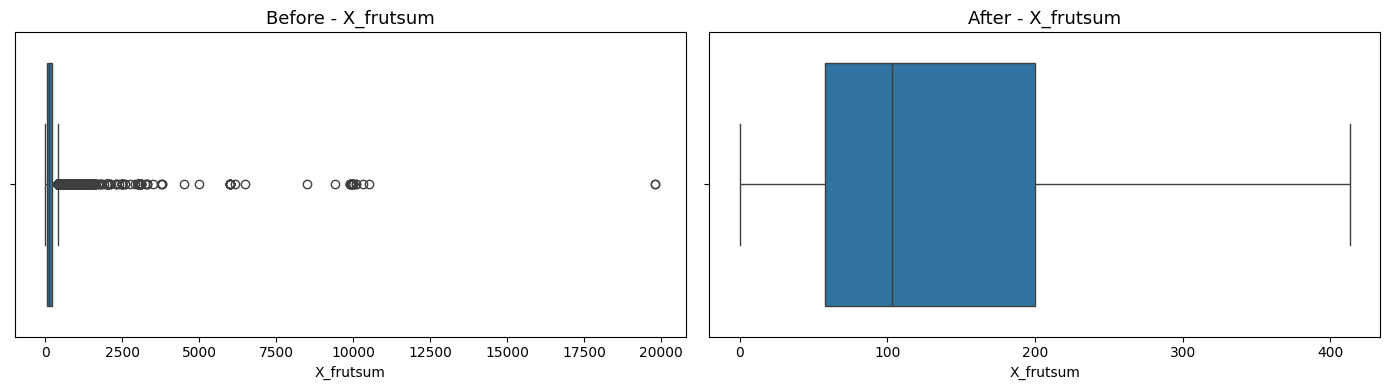

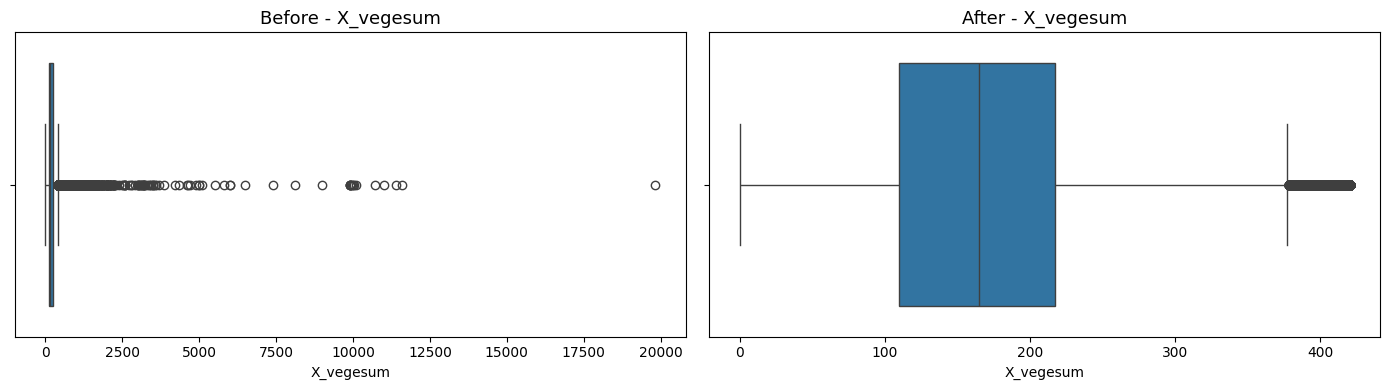

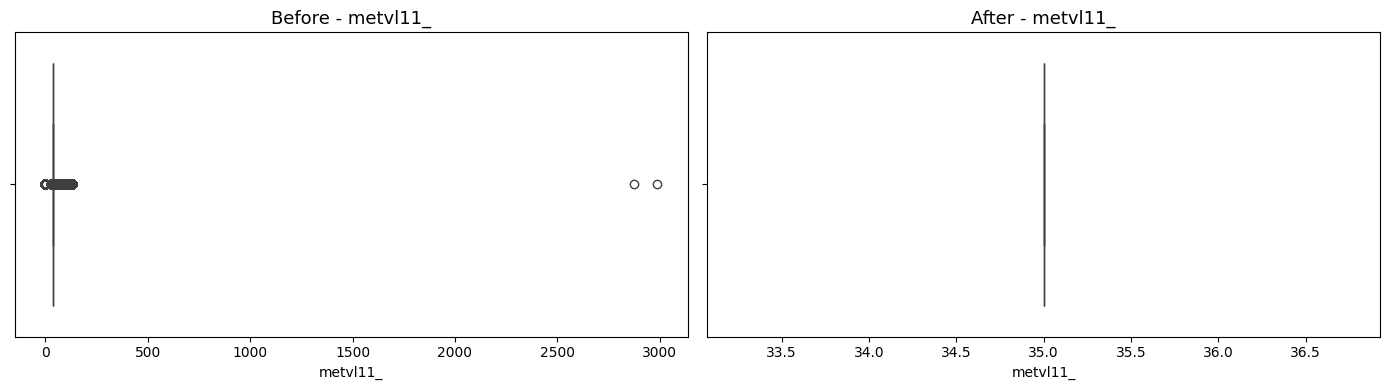

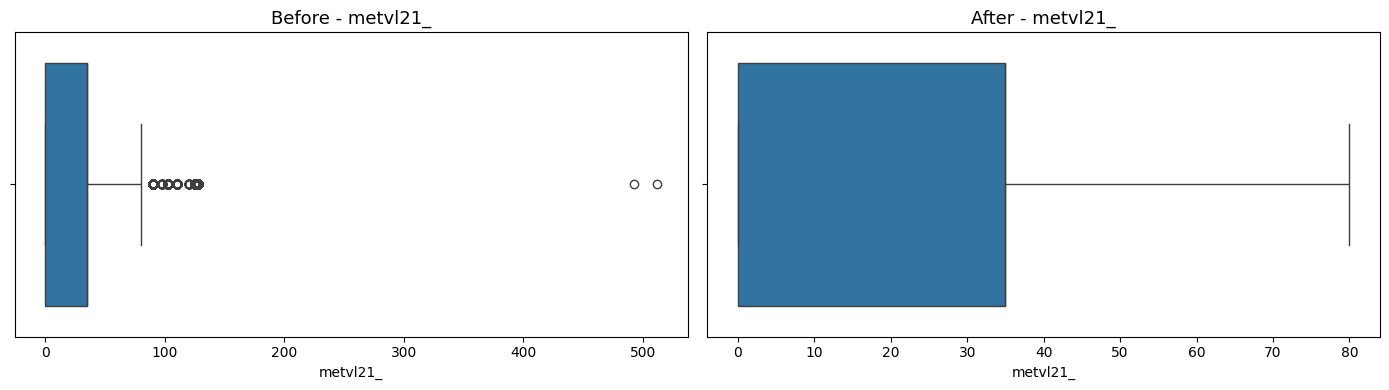

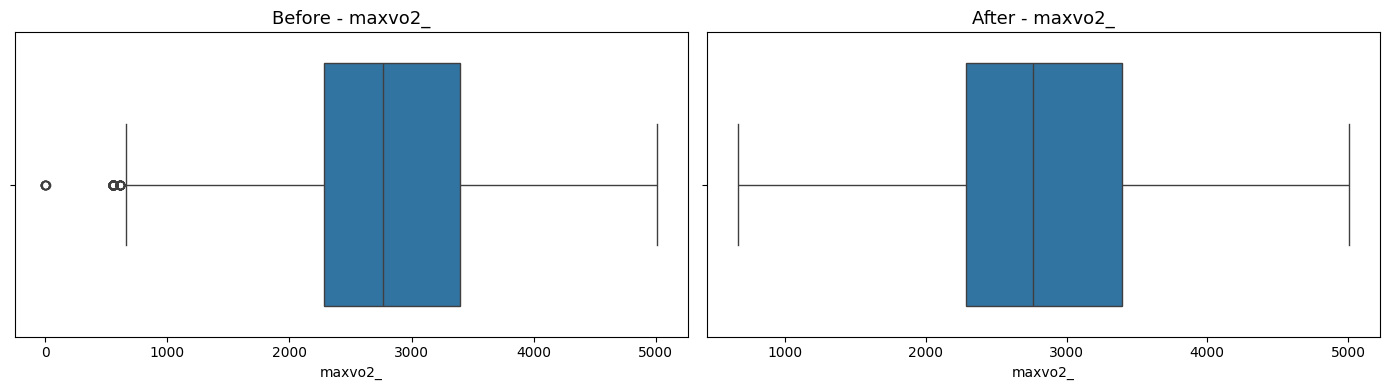

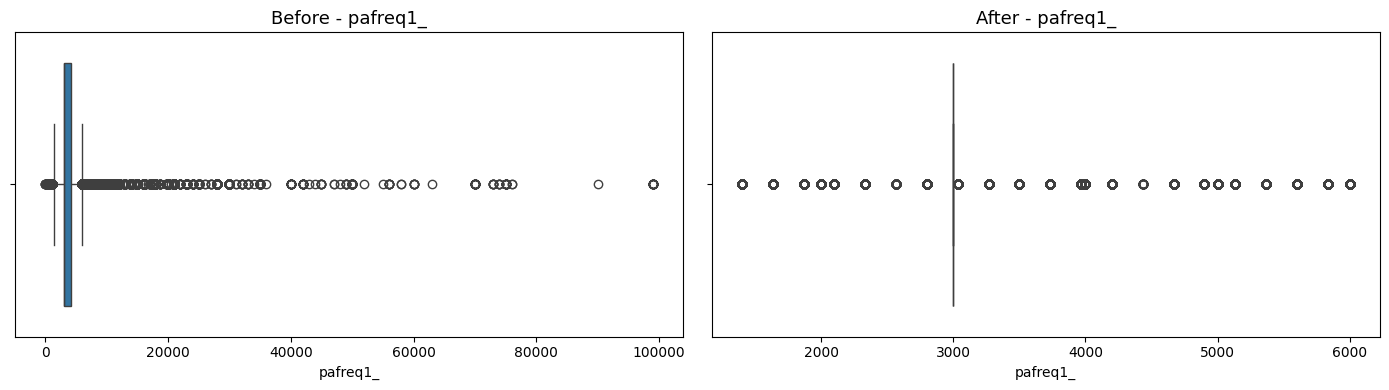

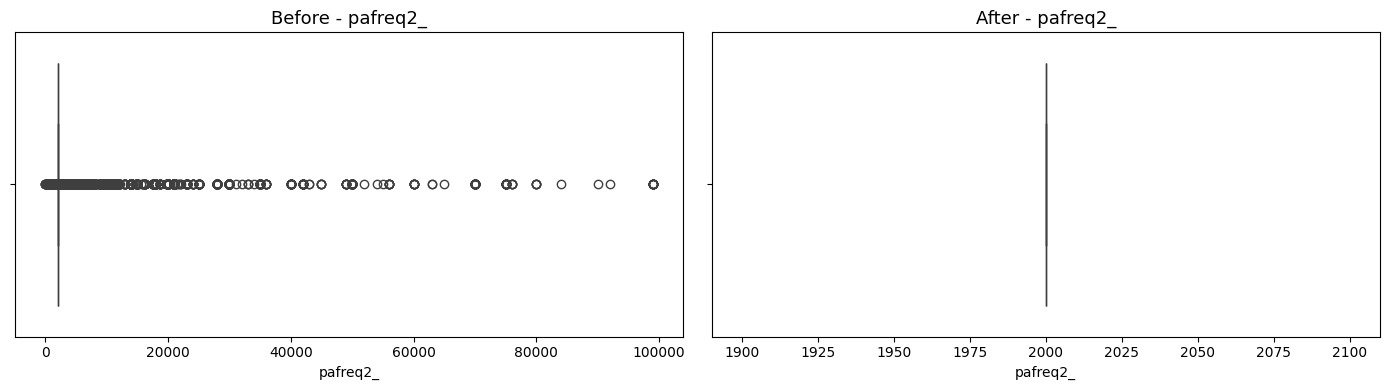

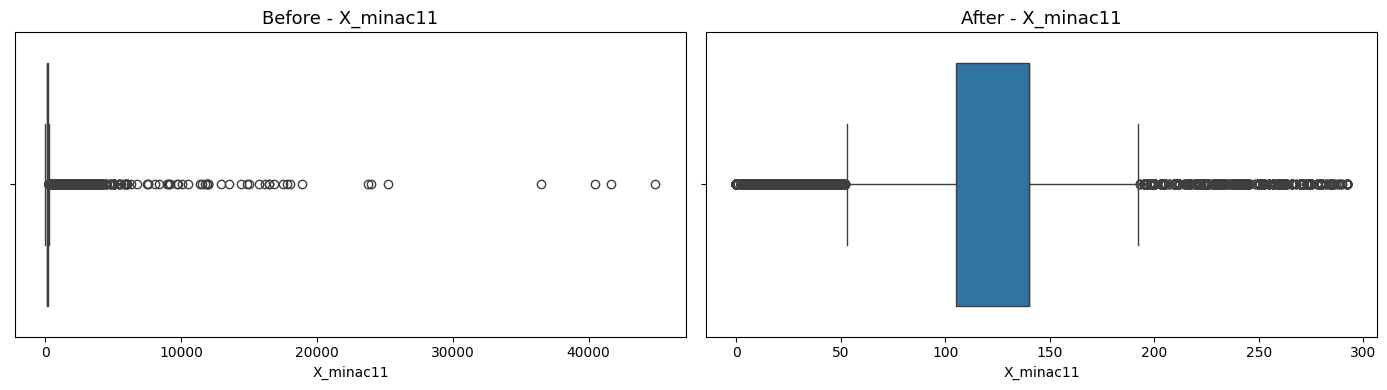

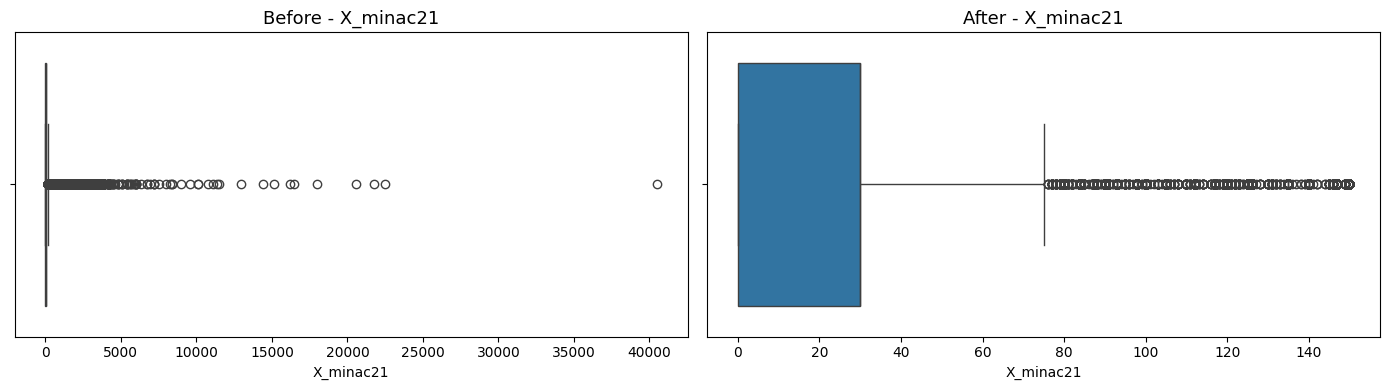

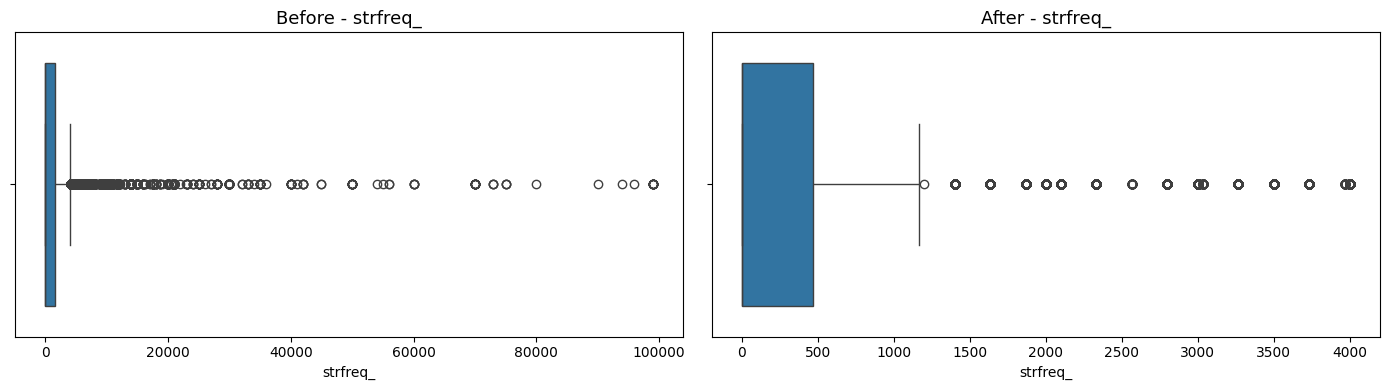

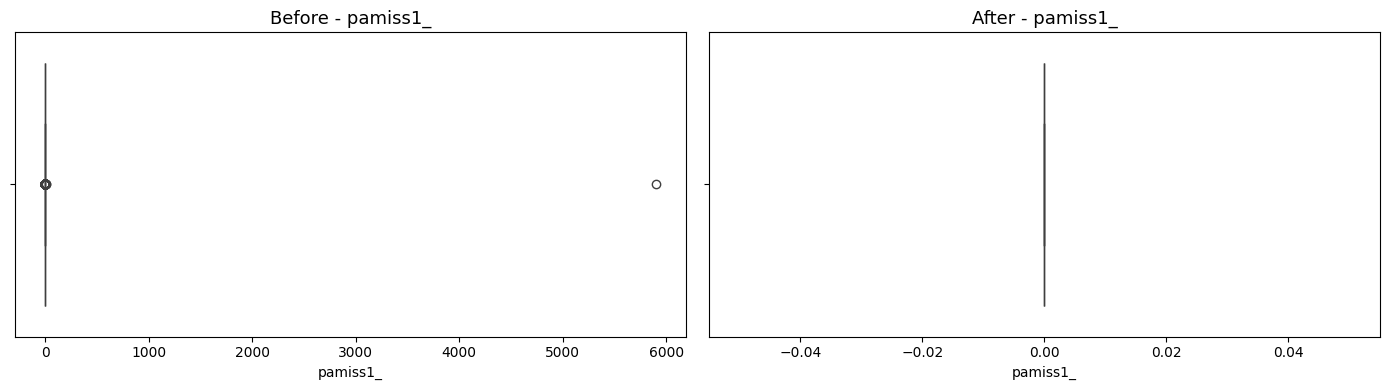

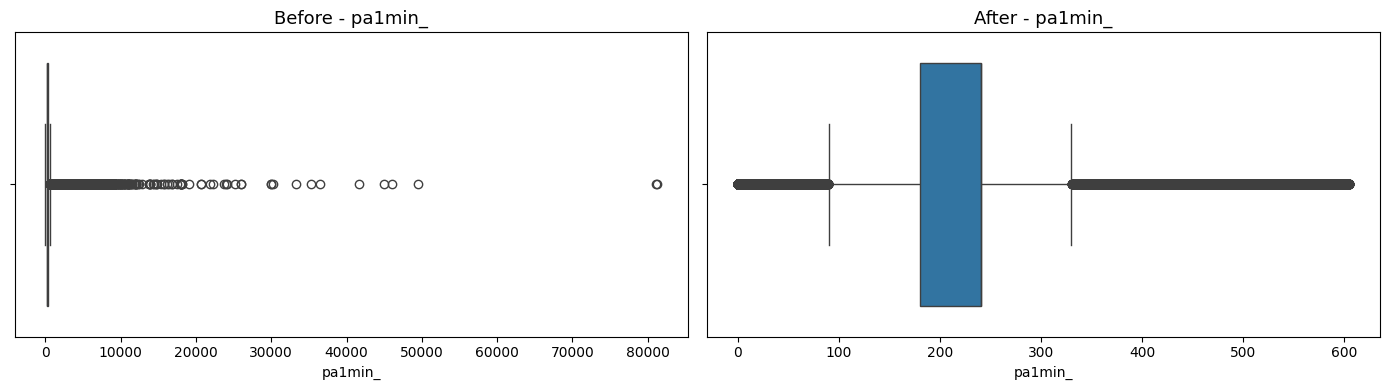

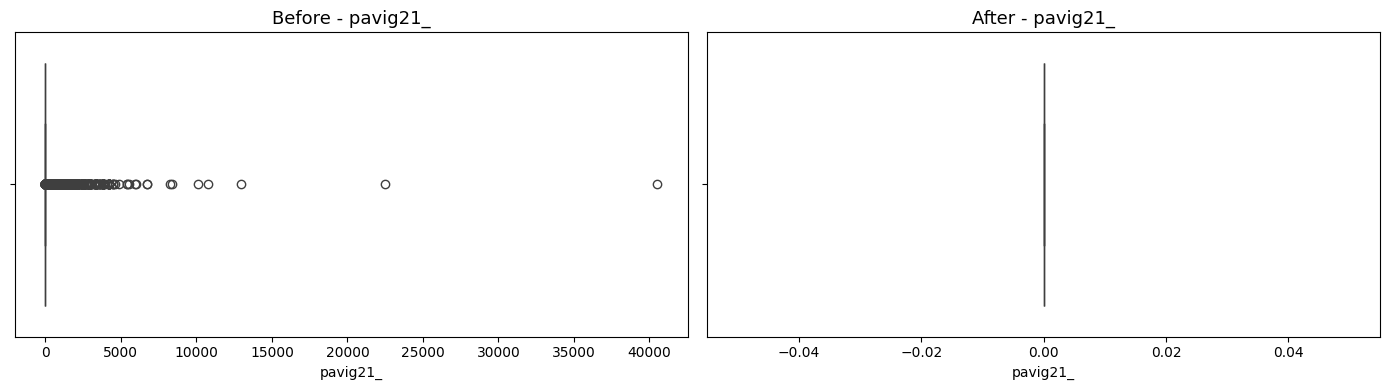

In [22]:
import warnings
warnings.filterwarnings('ignore')

common_cols = df_before.columns.intersection(df_reduced.columns)
numeric_cols = df_before[common_cols].select_dtypes(include='number').columns

for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.boxplot(x=df_before[col], ax=axes[0])
    axes[0].set_title(f"Before - {col}", fontsize=13)

    sns.boxplot(x=df_reduced[col], ax=axes[1])
    axes[1].set_title(f"After - {col}", fontsize=13)

    plt.tight_layout()
    plt.show()


# **Encoding session:**

---

Applying Encoding beginning after getting the data and what the values that represent, The code show's every object columns and the distenct values

In [23]:
for i in df_reduced.columns:
  print("column:",i,df_reduced[i].iloc[0],df_reduced[i].iloc[80],
        '\n',df_reduced[i].iloc[160],df_reduced[i].iloc[500])


column: genhlth Fair Good 
 Good Poor
column: physhlth 0.0 0.0 
 0.0 0.0
column: menthlth 0.0 0.0 
 0.0 0.0
column: poorhlth 0.0 0.0 
 0.0 0.0
column: checkup1 Within past year Within past 2 years 
 Within past year Within past year
column: sleptim1 7.0 7.0 
 7.0 7.0
column: bphigh4 Yes Yes 
 Yes Yes
column: bpmeds Yes Yes 
 Yes Yes
column: bloodcho Yes Yes 
 Yes Yes
column: cholchk Within past year Within past 2 years 
 Within past year Within past year
column: toldhi2 Yes Yes 
 Yes Yes
column: cvdinfr4 No Yes 
 No No
column: cvdcrhd4 No No 
 No No
column: cvdstrk3 No No 
 No No
column: asthma3 Yes No 
 No Yes
column: asthnow Yes Yes 
 Yes No
column: chcscncr No Yes 
 No No
column: chcocncr No No 
 No No
column: chccopd1 Yes No 
 Yes Yes
column: havarth3 Yes Yes 
 Yes Yes
column: chckidny Yes No 
 No No
column: diabete3 No No 
 No No
column: marital Divorced Married 
 Married Married
column: weight2 250.0 149.0 
 172.0 244.0
column: height3 507.0 507.0 
 504.0 506.0
column: cpdemo4 10

##***Gathering columns that need to be Encoded.***

---


##**some columns required type of Encoding different of other columns.**
##**so, best approach is to separate each kind of another, and make combination with similarity.**

In [24]:
lebel_columns=['genhlth','marital','emtsuprt','lsatisfy','X_asthms1','X_bmi5cat','actin21_','X_pacat1',
'misnervs','mishopls','misrstls','misdeprd','miseffrt','miswtles','sex','hadsgco1']


onehot_col=['marital']
ordered_col=['X_bmi5cat','genhlth','emtsuprt','lsatisfy','X_asthms1','actin21_','X_pacat1','misnervs','mishopls','misrstls','misdeprd','miseffrt','miswtles'] #13
not_ordered_col=['sex','hadsgco1']


df_lebel=df_reduced[lebel_columns]
df_lebel.head(9)


,genhlth,marital,emtsuprt,lsatisfy,X_asthms1,X_bmi5cat,actin21_,X_pacat1,misnervs,mishopls,misrstls,misdeprd,miseffrt,miswtles,sex,hadsgco1
0,Fair,Divorced,Always,Very satisfied,Current,Obese,Not Moderate or Vigorous or No Activity,Inactive,Some,Some,Some,A little,All,A little,Female,Colonoscopy
1,Good,Married,Sometimes,Satisfied,Never,Underweight,Moderate,Insufficiently active,A little,A little,A little,A little,A little,A little,Female,Colonoscopy
2,Good,Married,Usually,Very satisfied,Never,Overweight,Not Moderate or Vigorous or No Activity,Inactive,A little,A little,A little,A little,A little,A little,Female,Colonoscopy
3,Very good,Married,Usually,Very satisfied,Never,Normal weight,Not Moderate or Vigorous or No Activity,Insufficiently active,A little,A little,Some,A little,A little,A little,Female,Colonoscopy
4,Good,Married,Always,Satisfied,Former,Obese,Not Moderate or Vigorous or No Activity,Inactive,A little,A little,A little,A little,A little,A little,Male,Colonoscopy
5,Very good,Divorced,Always,Satisfied,Never,Obese,Moderate,Insufficiently active,A little,A little,A little,A little,A little,A little,Female,Colonoscopy
6,Fair,Married,Always,Satisfied,Never,Normal weight,Not Moderate or Vigorous or No Activity,Active,A little,A little,A little,A little,A little,A little,Female,Colonoscopy
7,Good,Widowed,Always,Satisfied,Never,Overweight,Not Moderate or Vigorous or No Activity,Insufficiently active,A little,A little,A little,A little,A little,A little,Female,Colonoscopy
8,Excellent,Married,Always,Satisfied,Never,Obese,Not Moderate or Vigorous or No Activity,Active,A little,A little,A little,A little,A little,A little,Male,Colonoscopy


In [25]:
#قابله للحذف \ بس لللعرض
uni=[]
for col in df_lebel.columns:
  xx=df_lebel[col].unique()
  uni.append([col,xx,])
uni


[['genhlth',
  array(['Fair', 'Good', 'Very good', 'Excellent', 'Poor'], dtype=object)],
 ['marital',
  array(['Divorced', 'Married', 'Widowed', 'Never married', 'Separated',
         'A member of an unmarried couple'], dtype=object)],
 ['emtsuprt',
  array(['Always', 'Sometimes', 'Usually', 'Rarely', 'Never'], dtype=object)],
 ['lsatisfy',
  array(['Very satisfied', 'Satisfied', 'Dissatisfied', 'Very dissatisfied'],
        dtype=object)],
 ['X_asthms1', array(['Current', 'Never', 'Former'], dtype=object)],
 ['X_bmi5cat',
  array(['Obese', 'Underweight', 'Overweight', 'Normal weight'],
        dtype=object)],
 ['actin21_',
  array(['Not Moderate or Vigorous or No Activity', 'Moderate', 'Vigorous'],
        dtype=object)],
 ['X_pacat1',
  array(['Inactive', 'Insufficiently active', 'Active', 'Highly active'],
        dtype=object)],
 ['misnervs', array(['Some', 'A little', 'All', 'Most'], dtype=object)],
 ['mishopls', array(['Some', 'A little', 'All', 'Most'], dtype=object)],
 ['misrst

#***Lebel Encoding***

---


**method use to encode data that doesn't have an ordered, just categorical , like: male/Female ,sick/not sick.**

**so here we will use this function for (Sex) and -> ("hadsgco1")**

**HAD S G C O = Had Sigmoidoscopy or Colonoscopy**

In [26]:

labelE=LabelEncoder()
for col in not_ordered_col:
  encoded_label=labelE.fit_transform(df_reduced[col])
  df_reduced[col]=encoded_label
df_reduced[not_ordered_col]

,sex,hadsgco1
0,0,0
1,0,0
2,0,0
3,0,0
4,1,0
...,...,...
491770,0,0
491771,1,0
491772,0,0
491773,0,0


# ***Ordinal Encoding***

---


**Categorical Data that have order.**

**here we have 6 columns with same categorical, that make encode them together right choice👍🏻**


In [27]:
col_mis=['misnervs','mishopls','misrstls','misdeprd','miseffrt','miswtles'] #6
data_ord1=df_reduced[col_mis]

ordinalE=OrdinalEncoder(categories=[['A little', 'Some','Most', 'All']]* len(col_mis))
Encoded_Ord=ordinalE.fit_transform(data_ord1)

df_reduced[col_mis]=Encoded_Ord
df_reduced[col_mis]

,misnervs,mishopls,misrstls,misdeprd,miseffrt,miswtles
0,1.0,1.0,1.0,0.0,3.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...
491770,0.0,0.0,0.0,0.0,0.0,0.0
491771,0.0,0.0,0.0,0.0,0.0,0.0
491772,0.0,0.0,0.0,0.0,0.0,0.0
491773,0.0,0.0,0.0,0.0,0.0,0.0


**same function, but with different categories**

***what we did here is:***

**take unique values from each columns and put in individual list, and then simply use the fumction.**

##**Note: Each category list must be aligned with the exact positions of the real data values.**

##**⚠ Warn :Any mismatch in ordering leads to incorrect encoding.**

In [28]:
bmi_categ=['Obese', 'Underweight', 'Overweight', 'Normal weight'] #7
hlth_categ=['Poor','Fair', 'Good', 'Very good', 'Excellent']
emtsuprt_categ=[ 'Never', 'Rarely', 'Sometimes', 'Usually','Always']
lsatisfy_categ=['Very dissatisfied','Dissatisfied', 'Satisfied', 'Very satisfied']
asthms_categ=['Current' , 'Former','Never']
actin_categ=['Not Moderate or Vigorous or No Activity', 'Moderate', 'Vigorous']
pacat_categ=['Inactive', 'Insufficiently active', 'Active', 'Highly active']
arthsocl_enc=["Not at all","A little","A lot"]




categ=[ bmi_categ, hlth_categ, emtsuprt_categ,
       lsatisfy_categ, asthms_categ, actin_categ, pacat_categ,arthsocl_enc]


data=['X_bmi5cat','genhlth','emtsuprt','lsatisfy','X_asthms1','actin21_','X_pacat1','arthsocl']


ordinalE=OrdinalEncoder(categories=categ )
Encoded_Ord=ordinalE.fit_transform(df_reduced[data])

df_reduced[data]=Encoded_Ord
df_reduced[data]

,X_bmi5cat,genhlth,emtsuprt,lsatisfy,X_asthms1,actin21_,X_pacat1,arthsocl
0,0.0,1.0,4.0,3.0,0.0,0.0,0.0,2.0
1,1.0,2.0,2.0,2.0,2.0,1.0,1.0,0.0
2,2.0,2.0,3.0,3.0,2.0,0.0,0.0,1.0
3,3.0,3.0,3.0,3.0,2.0,0.0,1.0,0.0
4,0.0,2.0,4.0,2.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
491770,2.0,1.0,4.0,2.0,2.0,0.0,0.0,2.0
491771,0.0,2.0,4.0,2.0,2.0,0.0,0.0,0.0
491772,2.0,1.0,4.0,2.0,0.0,0.0,1.0,0.0
491773,3.0,3.0,4.0,2.0,2.0,0.0,2.0,0.0


#***OneHotEncoding***

---


**Last and not Least for categorical that the order doesn't mean any thing.**
**This function will increase more columns, and we most drop old version of column name from DataFrame.**

In [29]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)
one_hot_encoded = encoder.fit_transform(df_reduced[onehot_col])

new_cols = encoder.get_feature_names_out(onehot_col)
one_hot_df=pd.DataFrame(one_hot_encoded,columns=new_cols,index=df_reduced.index)

df_reduced=df_reduced.drop(columns=onehot_col)
df_reduced=pd.concat([df_reduced,one_hot_df],axis=1)
df_reduced

,genhlth,physhlth,menthlth,poorhlth,checkup1,sleptim1,bphigh4,bpmeds,bloodcho,cholchk,...,X_pastrng,X_flshot6,X_pneumo2,X_aidtst3,marital_A member of an unmarried couple,marital_Divorced,marital_Married,marital_Never married,marital_Separated,marital_Widowed
0,1.0,0.0,0.0,0.0,Within past year,7.0,Yes,Yes,Yes,Within past year,...,Did not meet muscle strengthening recommendations,Yes,Yes,No,0.0,1.0,0.0,0.0,0.0,0.0
1,2.0,0.0,0.0,0.0,Within past year,6.0,No,Yes,Yes,Within past year,...,Did not meet muscle strengthening recommendations,Yes,Yes,Yes,0.0,0.0,1.0,0.0,0.0,0.0
2,2.0,3.0,2.0,0.0,Within past year,9.0,No,Yes,Yes,5 or more years ago,...,Did not meet muscle strengthening recommendations,Yes,Yes,Yes,0.0,0.0,1.0,0.0,0.0,0.0
3,3.0,2.0,0.0,0.0,Within past 2 years,8.0,No,Yes,Yes,Within past year,...,Did not meet muscle strengthening recommendations,Yes,Yes,No,0.0,0.0,1.0,0.0,0.0,0.0
4,2.0,0.0,2.0,0.0,5 or more years ago,6.0,Yes,No,Yes,Within past 2 years,...,Did not meet muscle strengthening recommendations,No,No,No,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491770,1.0,0.0,0.0,0.0,Within past year,6.0,Yes,Yes,Yes,Within past year,...,Did not meet muscle strengthening recommendations,Yes,Yes,No,0.0,1.0,0.0,0.0,0.0,0.0
491771,2.0,0.0,0.0,0.0,Within past year,7.0,No,Yes,Yes,Within past year,...,Did not meet muscle strengthening recommendations,Yes,Yes,No,0.0,0.0,0.0,1.0,0.0,0.0
491772,1.0,0.0,0.0,0.0,Within past year,7.0,No,Yes,Yes,Within past year,...,Did not meet muscle strengthening recommendations,Yes,Yes,Yes,1.0,0.0,0.0,0.0,0.0,0.0
491773,3.0,0.0,0.0,0.0,Within past year,8.0,No,Yes,No,Within past year,...,Did not meet muscle strengthening recommendations,Yes,Yes,Yes,0.0,0.0,0.0,0.0,1.0,0.0


#***Special Encoding "handly":***

---

##**Some columns need to encode it by scrach**

In [30]:
binary_mapping = {
    'Good or Better Health': 1,
    'Fair or Poor Health': 0,
    'Diagnosed with arthritis': 1,
    'Not diagnosed with arthritis': 0,
    'Had physical activity or exercise': 1,
    'No physical activity or exercise in last 30 days': 0,
    'Met aerobic recommendations': 1,
    'Did not meet aerobic recommendations': 0,
    'Met muscle strengthening recommendations': 1,
    'Did not meet muscle strengthening recommendations': 0
}

df_reduced['X_rfhlth_encoded'] = df_reduced['X_rfhlth'].map(binary_mapping)
df_reduced['X_drdxar1_encoded'] = df_reduced['X_drdxar1'].map(binary_mapping)
df_reduced['X_totinda_encoded'] = df_reduced['X_totinda'].map(binary_mapping)
df_reduced['X_paindx1_encoded'] = df_reduced['X_paindx1'].map(binary_mapping)
df_reduced['X_pastrng_encoded'] = df_reduced['X_pastrng'].map(binary_mapping)

df_reduced.drop(columns=['X_rfhlth','X_drdxar1','X_totinda','X_paindx1','X_pastrng'], inplace=True)
speci_col=['X_rfhlth_encoded','X_drdxar1_encoded','X_totinda_encoded','X_paindx1_encoded','X_pastrng_encoded']

df_spec=df_reduced[speci_col]
df_spec.head(40000)

,X_rfhlth_encoded,X_drdxar1_encoded,X_totinda_encoded,X_paindx1_encoded,X_pastrng_encoded
0,0,1,0,0,0
1,1,0,1,0,0
2,1,1,0,0,0
3,1,0,1,0,0
4,1,0,0,0,0
...,...,...,...,...,...
39995,1,0,1,1,1
39996,1,0,0,0,0
39997,1,1,1,0,0
39998,1,1,1,0,0


In [31]:

checkup_map = {
    'Never': 0,
    '5 or more years ago': 0,
    'Within past 5 years': 1,
    'Within past 2 years': 1,
    'Within past year': 2
}

cholchk_map = {
    '5 or more years ago': 0,
    'Within past 5 years': 0,
    'Within past 2 years': 1,
    'Within past year': 2
}

eyeexam_map = {
    'Never': 0,
    '2 or more years ago': 0,
    'Within the past 2 years': 1,
    'Within the past year': 2,
    'Within the past month': 2
}


asnoslep_map = {
    'One or two': 0,
    'Three to four': 1,
    'Five': 1,
    'Six to ten': 2,
    'More than ten': 2
}

df_reduced['checkup1_enc'] = df_reduced['checkup1'].map(checkup_map)
df_reduced['cholchk_enc'] = df_reduced['cholchk'].map(cholchk_map)
df_reduced['eyeexam_enc'] = df_reduced['eyeexam'].map(eyeexam_map)
df_reduced['asnoslep_enc'] = df_reduced['asnoslep'].map(asnoslep_map)


df_reduced = df_reduced.drop(columns=['checkup1', 'cholchk', 'eyeexam', 'asnoslep'])


encoded_cols = ['checkup1_enc', 'cholchk_enc', 'eyeexam_enc', 'asnoslep_enc']


print(df_reduced[encoded_cols].head())


nan_check = df_reduced[encoded_cols].isna().sum()
print("null")
print(nan_check)



   checkup1_enc  cholchk_enc  eyeexam_enc  asnoslep_enc
0             2            2            2             0
1             2            2            2             0
2             2            0            2             0
3             1            2            2             0
4             0            1            2             0
null
checkup1_enc    0
cholchk_enc     0
eyeexam_enc     0
asnoslep_enc    0
dtype: int64


In [32]:
diabetes_mapping = {
    'No': 0,
    'Yes': 2,
    'No, pre-diabetes or borderline diabetes': 1,
    'Yes, but female told only during pregnancy': 1
}

df_reduced['diabete3_encoded'] = df_reduced['diabete3'].map(diabetes_mapping)

df_reduced = df_reduced.drop(columns=['diabete3'])

print(df_reduced['diabete3_encoded'].isna().sum())


0


In [33]:
print(df_reduced['diabete3_encoded'].unique())

[0 2 1]


In [34]:

df_reduced.isna().sum()


,0
genhlth,0
physhlth,0
menthlth,0
poorhlth,0
sleptim1,0
...,...
checkup1_enc,0
cholchk_enc,0
eyeexam_enc,0
asnoslep_enc,0


# **Re-encoding ['diabete3'] column, The target of classification model**

#***Label Encoding for Yes/No:***

---
##**Last things is to convert binary categories (yea/ no) to numerical**


In [35]:
label = LabelEncoder()

for col in df_reduced.columns:
    if df_reduced[col].dtype == 'object':
        df_reduced[col] = label.fit_transform(df_reduced[col].astype(str))

df_reduced.select_dtypes(include='object').sum()

,0


##***last checking of the data before start the ware***

---



In [36]:
for col, num_missing in df_reduced.isna().sum().items():
    if num_missing > 0:
        print(col, num_missing)



#***Ploting of each numerical data with the goal individual***

---



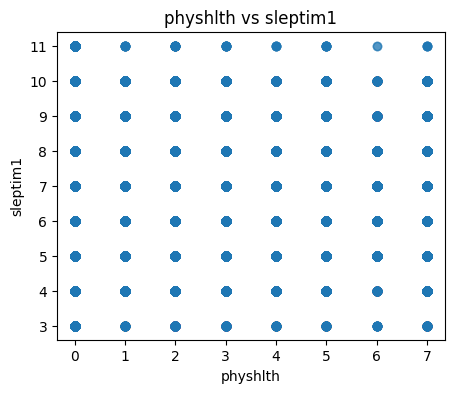

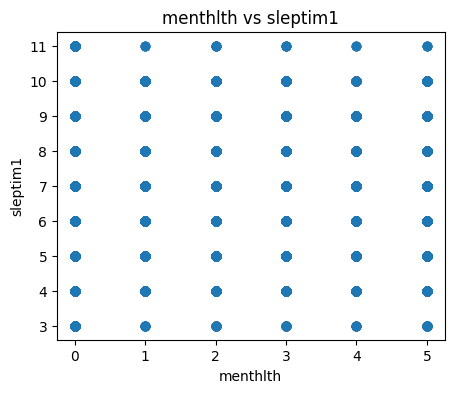

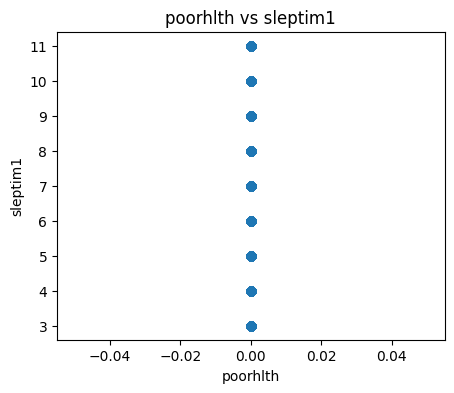

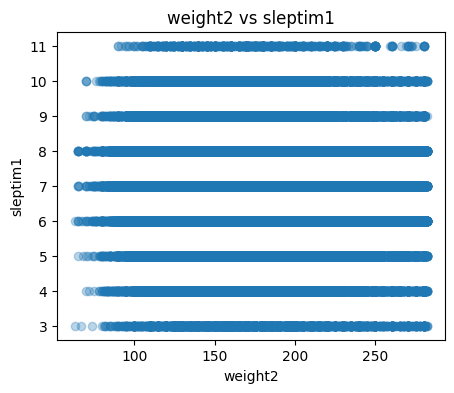

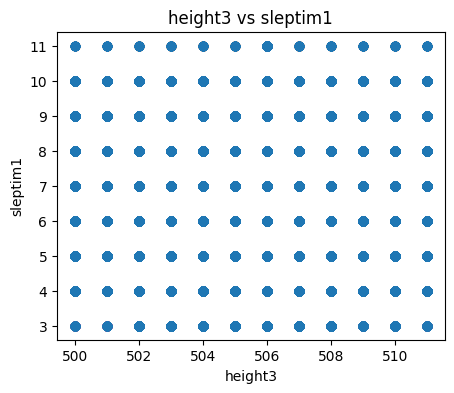

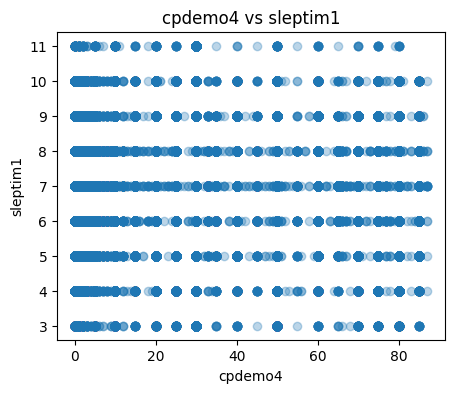

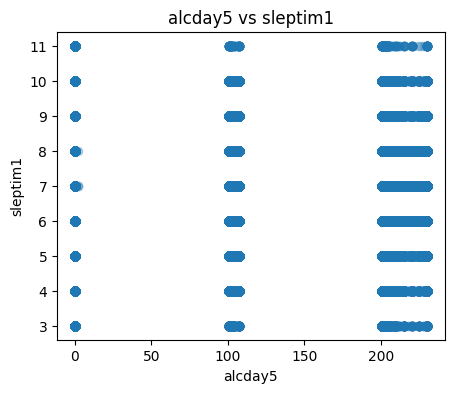

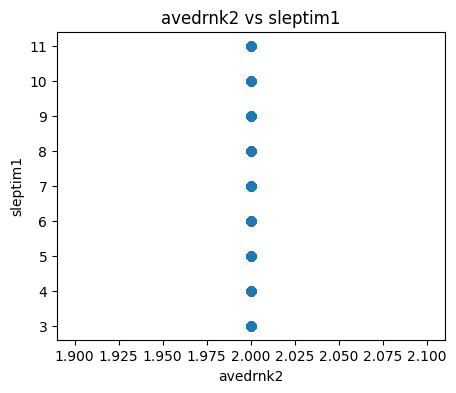

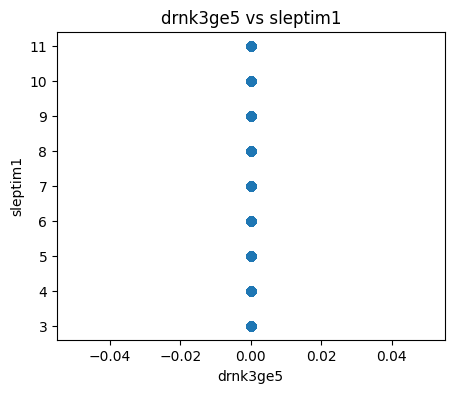

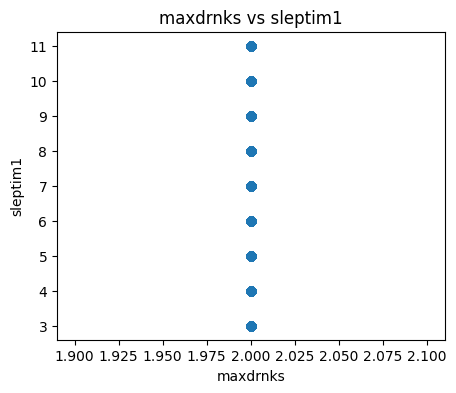

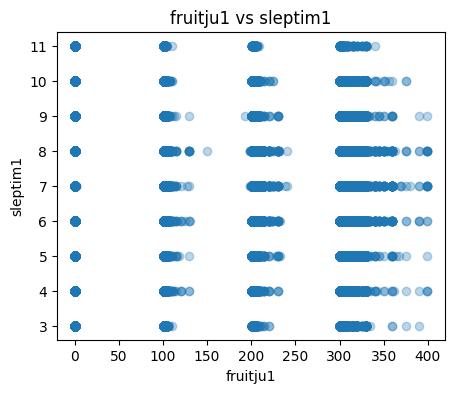

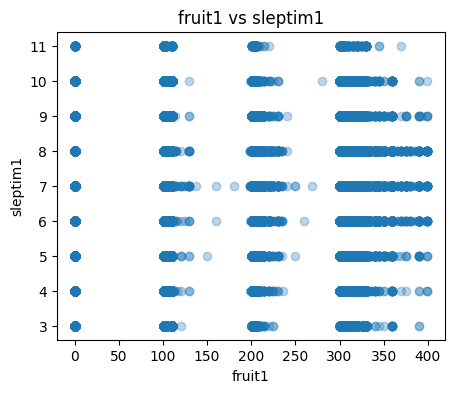

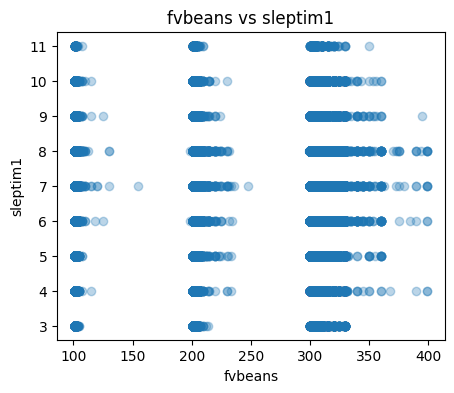

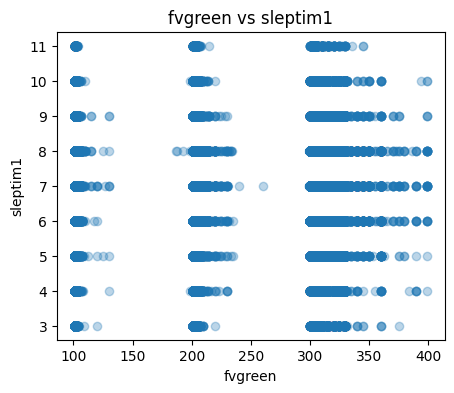

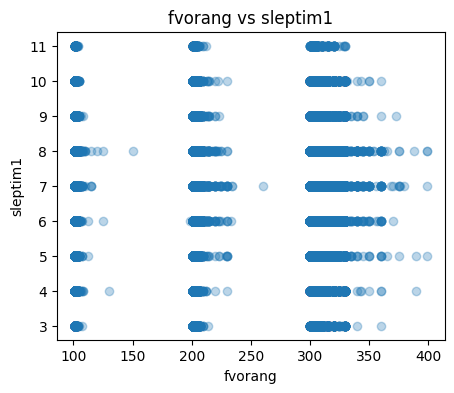

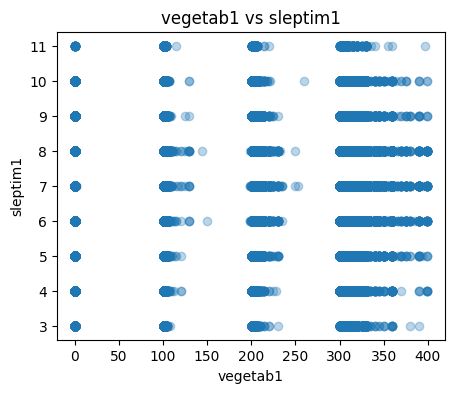

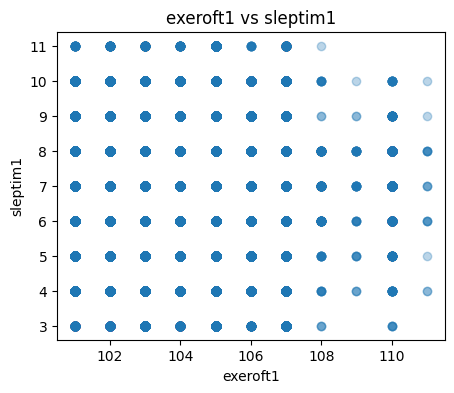

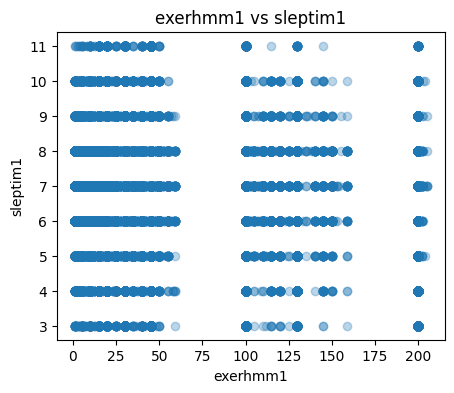

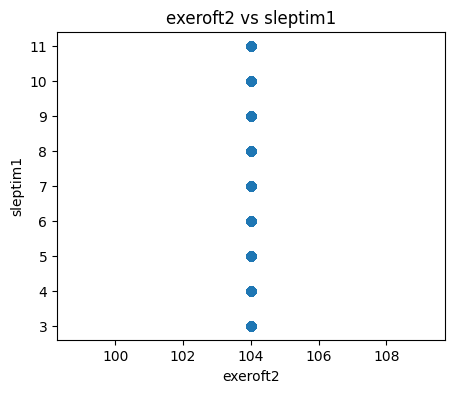

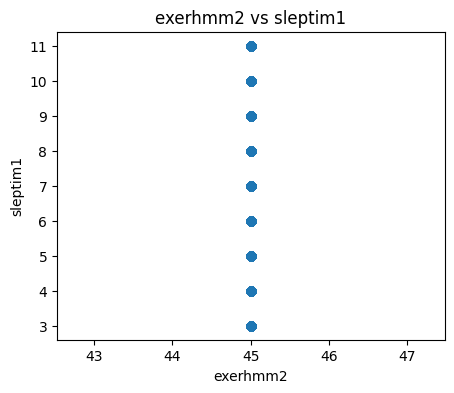

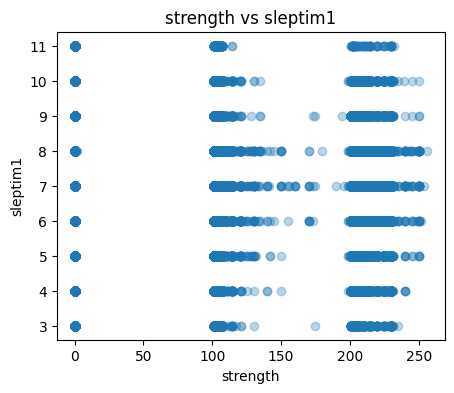

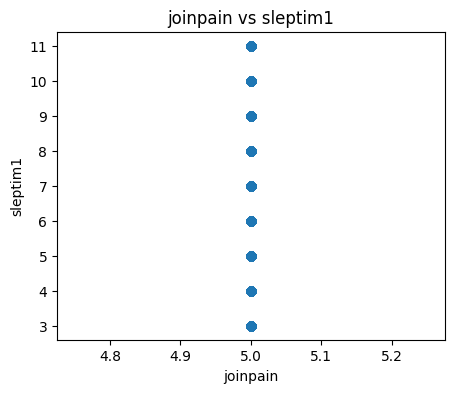

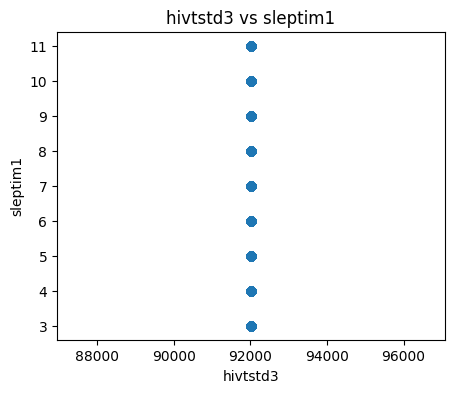

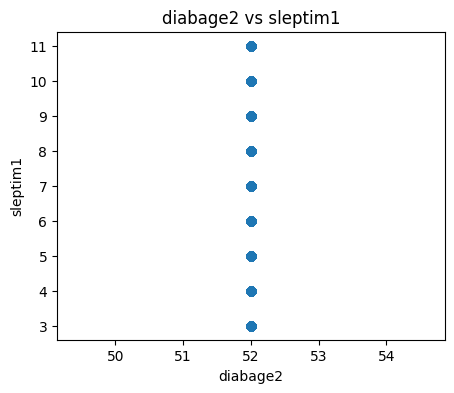

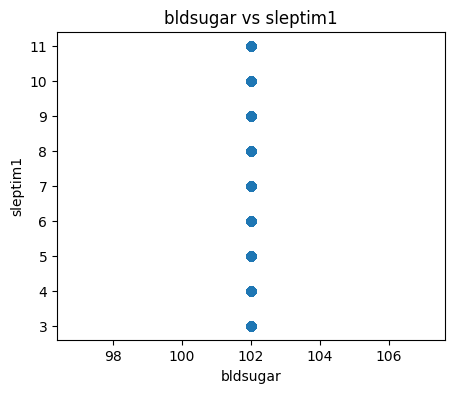

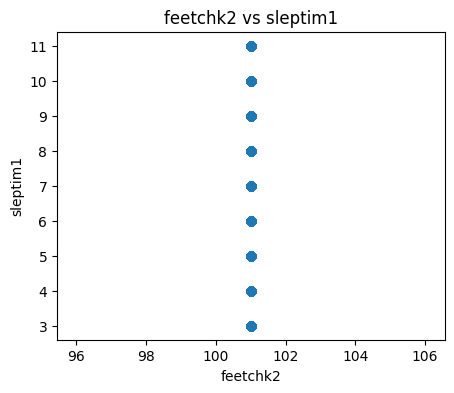

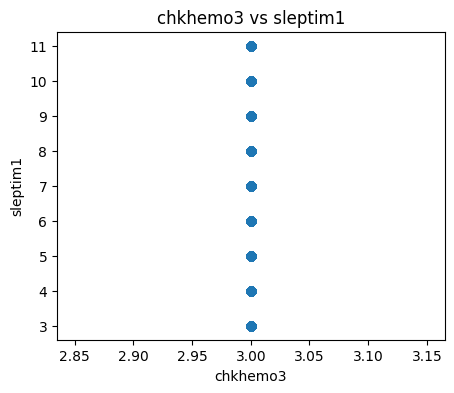

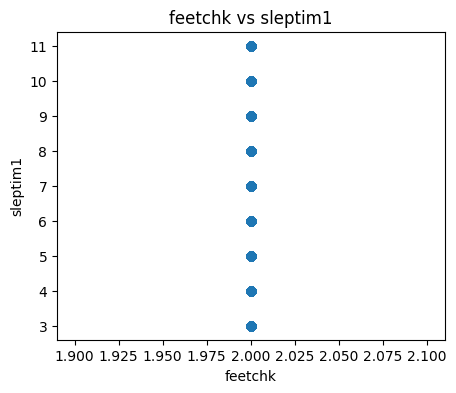

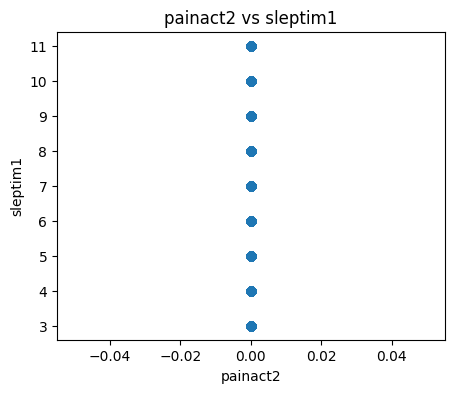

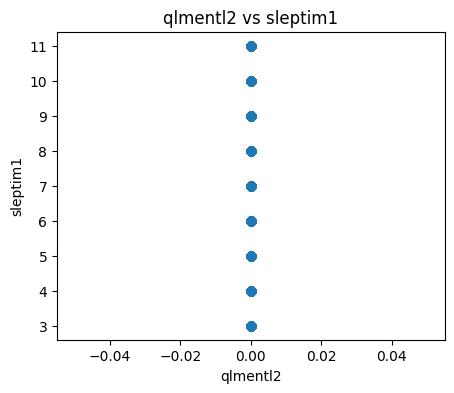

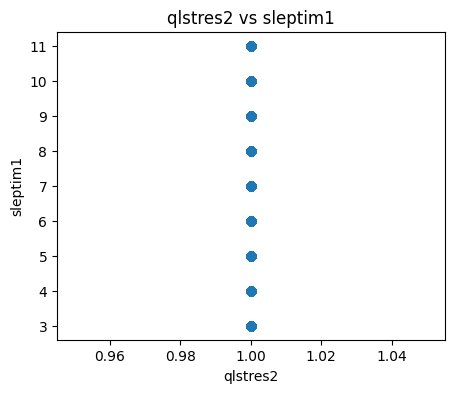

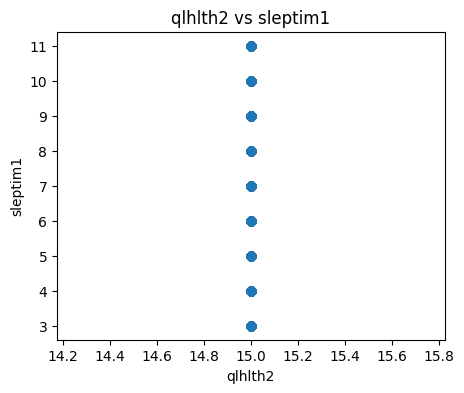

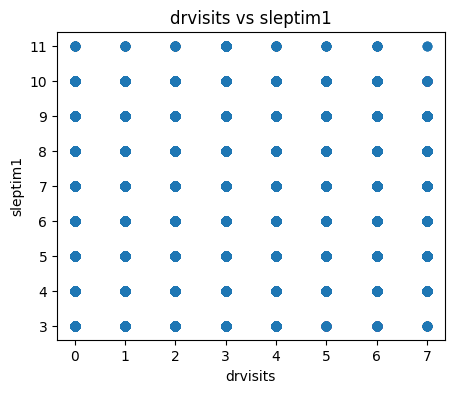

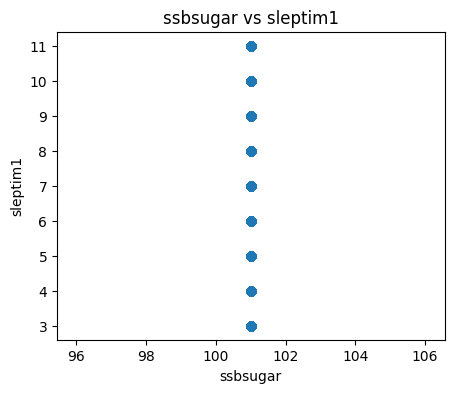

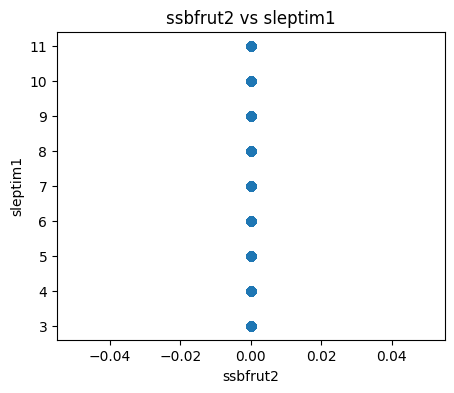

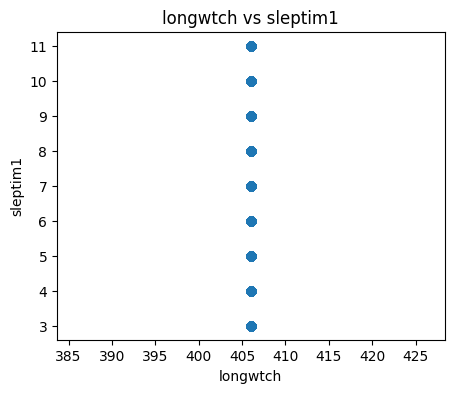

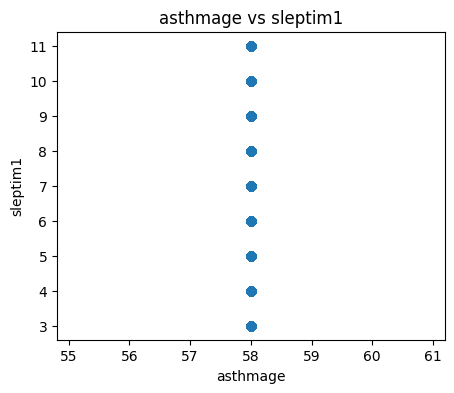

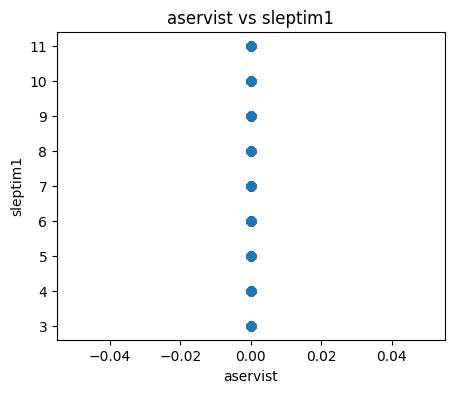

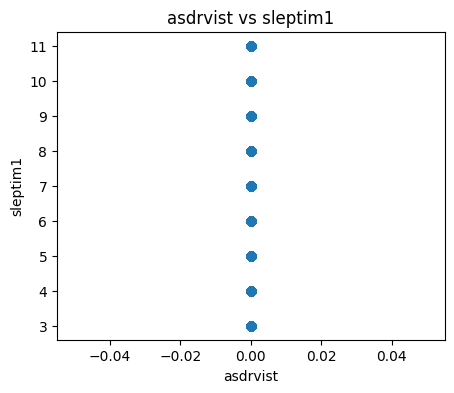

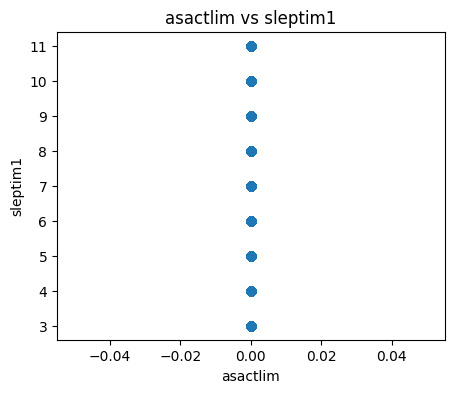

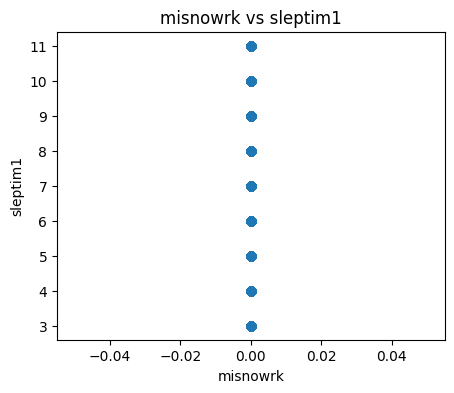

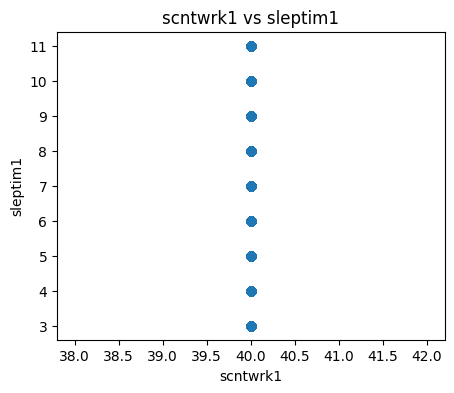

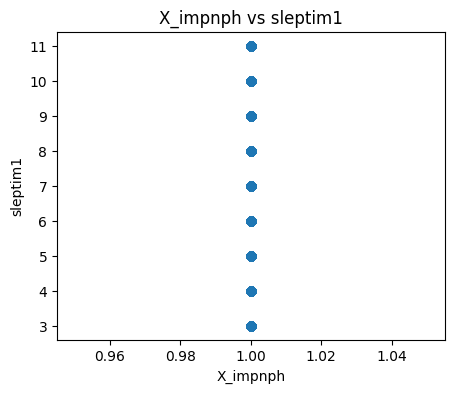

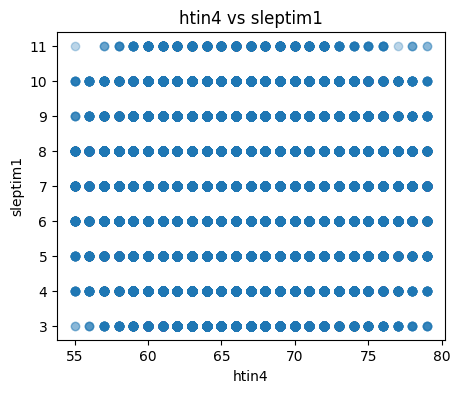

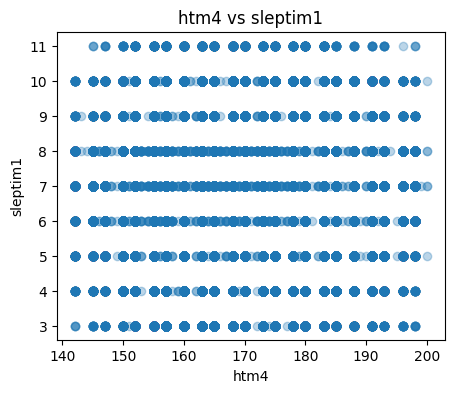

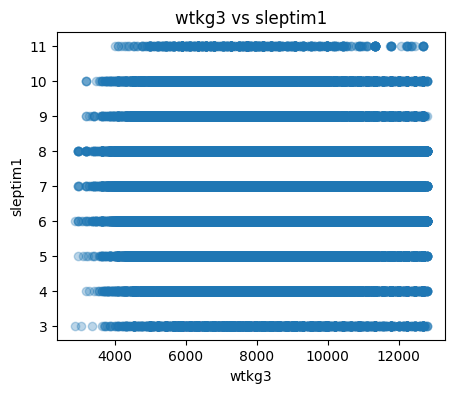

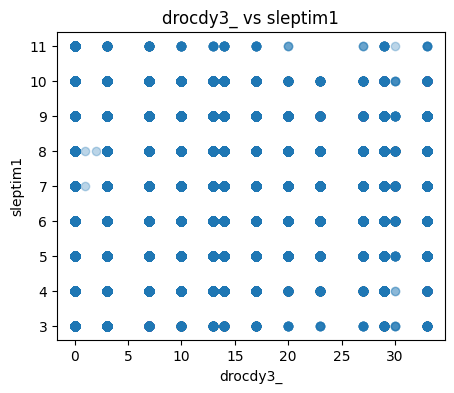

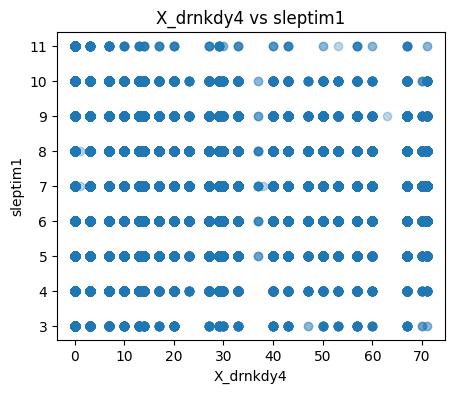

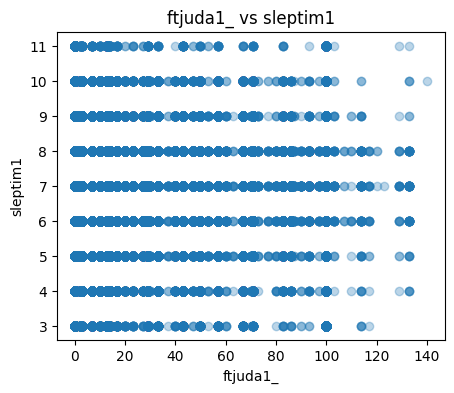

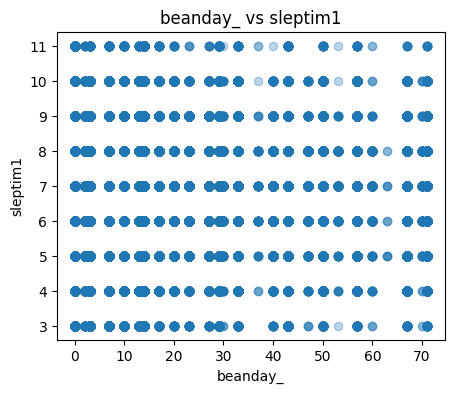

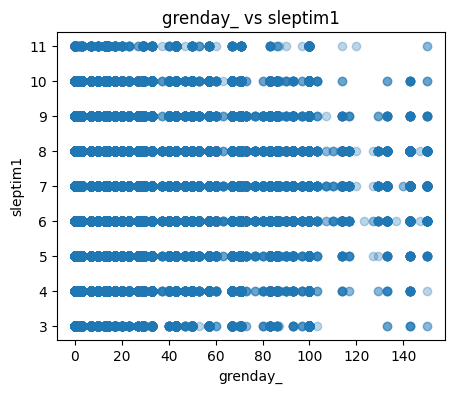

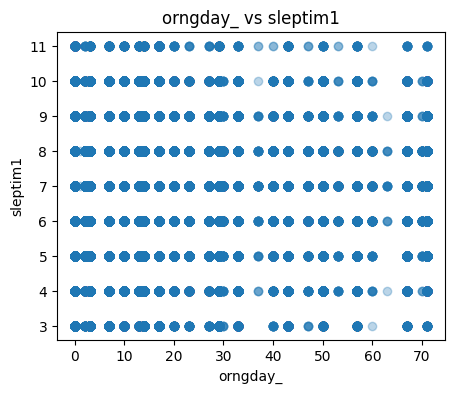

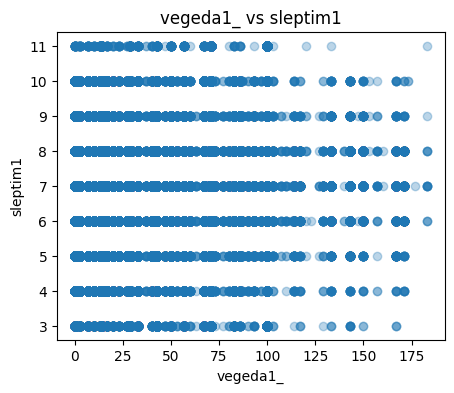

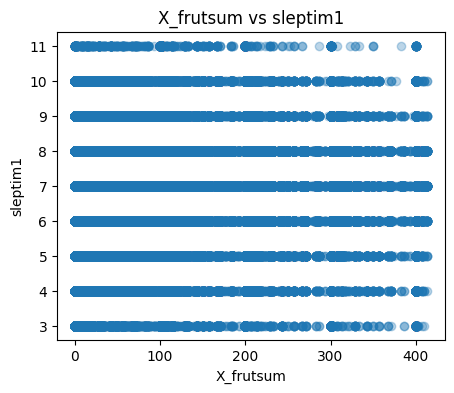

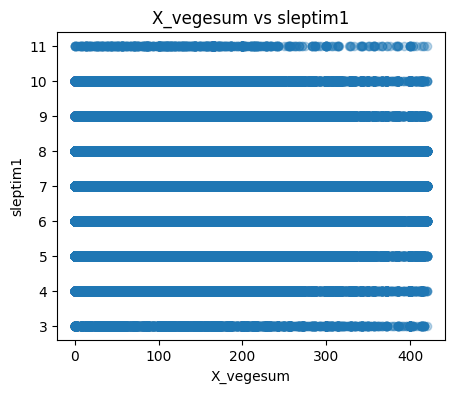

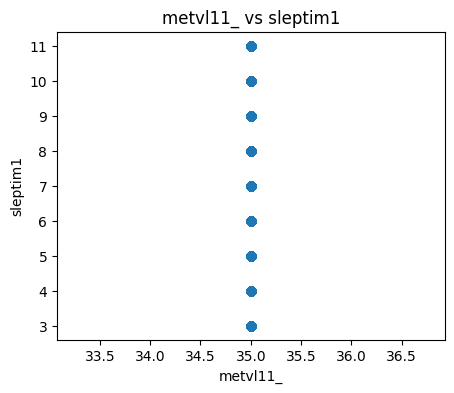

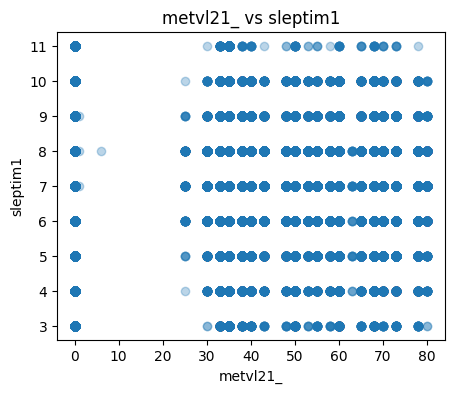

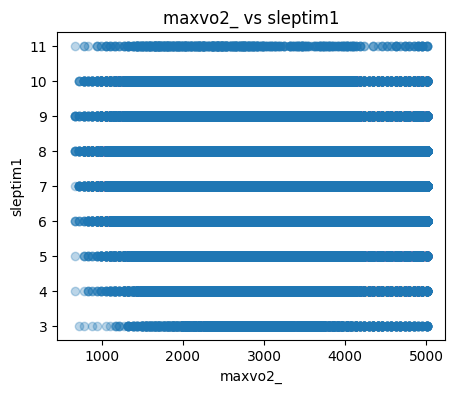

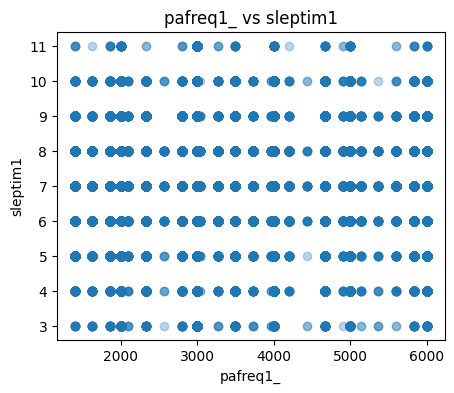

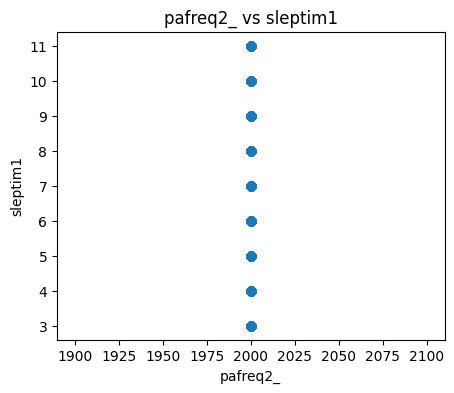

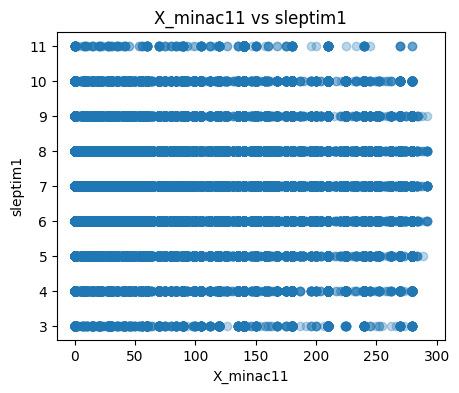

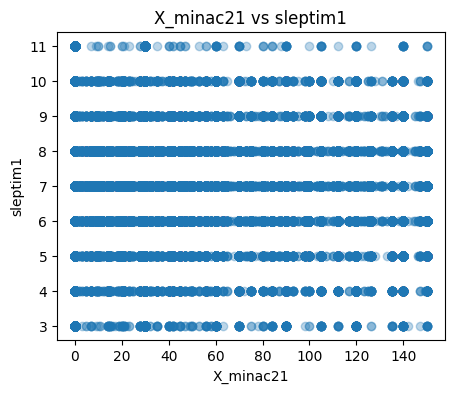

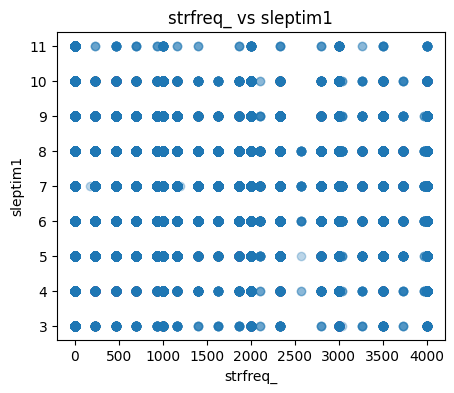

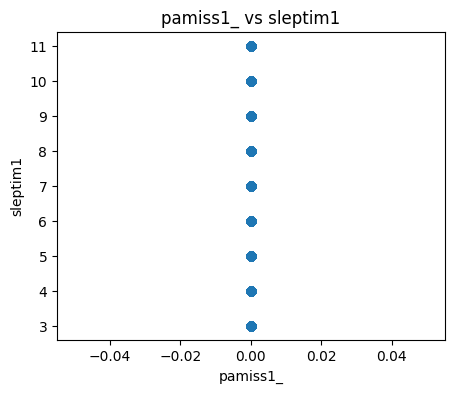

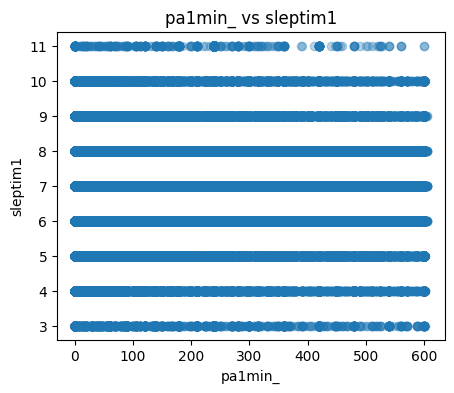

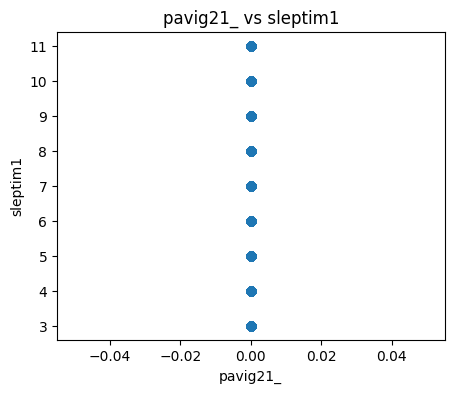

In [37]:
target = 'sleptim1'

for col in numeric.columns:
    if col != target:
        plt.figure(figsize=(5,4))
        plt.scatter(df_reduced[col], df_reduced[target], alpha=0.3)
        plt.xlabel(col)
        plt.ylabel(target)
        plt.title(f'{col} vs {target}')
        plt.show()

In [38]:
for cols_tar in numeric.columns:
   for col in numeric.columns:
     if cols_tar!=col :
        corr = df_reduced[col].corr(df_reduced[cols_tar])
        if corr >=0.5:
          print (cols_tar,'+',col,'=', f"{corr:.4f}")

weight2 + wtkg3 = 0.9993
height3 + htin4 = 0.7098
height3 + htm4 = 0.7125
strength + strfreq_ = 0.5716
htin4 + height3 = 0.7098
htin4 + htm4 = 0.9926
htm4 + height3 = 0.7125
htm4 + htin4 = 0.9926
wtkg3 + weight2 = 0.9993
drocdy3_ + X_drnkdy4 = 0.5716
X_drnkdy4 + drocdy3_ = 0.5716
grenday_ + X_vegesum = 0.6112
vegeda1_ + X_vegesum = 0.5679
X_vegesum + grenday_ = 0.6112
X_vegesum + vegeda1_ = 0.5679
metvl21_ + X_minac21 = 0.6148
X_minac11 + pa1min_ = 0.5328
X_minac21 + metvl21_ = 0.6148
strfreq_ + strength = 0.5716
pa1min_ + X_minac11 = 0.5328


# ***Features Selection : 'SelectKBest'***

---

**selecting most 20 columns useful the the model**


---


#***for model (Regresstion)***
**the way that the model will select the 20 columns that related and meaningful to the goal by counting F-score , p-values.**
#***The output will be the most 20 columns helpful to the target.***

In [39]:
X = df_reduced.drop('sleptim1', axis=1)
y_regression = df_reduced['sleptim1']

selector = SelectKBest(score_func=f_regression, k=20)
selector.fit(X, y_regression)

selected_features_reg = X.columns[selector.get_support()]
df_reduced

,genhlth,physhlth,menthlth,poorhlth,sleptim1,bphigh4,bpmeds,bloodcho,toldhi2,cvdinfr4,...,X_rfhlth_encoded,X_drdxar1_encoded,X_totinda_encoded,X_paindx1_encoded,X_pastrng_encoded,checkup1_enc,cholchk_enc,eyeexam_enc,asnoslep_enc,diabete3_encoded
0,1.0,0.0,0.0,0.0,7.0,2,1,1,1,0,...,0,1,0,0,0,2,2,2,0,0
1,2.0,0.0,0.0,0.0,6.0,0,1,1,0,0,...,1,0,1,0,0,2,2,2,0,0
2,2.0,3.0,2.0,0.0,9.0,0,1,1,0,0,...,1,1,0,0,0,2,0,2,0,0
3,3.0,2.0,0.0,0.0,8.0,0,1,1,1,0,...,1,0,1,0,0,1,2,2,0,0
4,2.0,0.0,2.0,0.0,6.0,2,0,1,0,0,...,1,0,0,0,0,0,1,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491770,1.0,0.0,0.0,0.0,6.0,2,1,1,1,1,...,0,1,0,0,0,2,2,2,0,2
491771,2.0,0.0,0.0,0.0,7.0,0,1,1,1,0,...,1,1,0,0,0,2,2,2,0,2
491772,1.0,0.0,0.0,0.0,7.0,0,1,1,0,0,...,0,0,1,0,0,2,2,2,0,0
491773,3.0,0.0,0.0,0.0,8.0,0,1,0,0,0,...,1,0,1,1,0,2,2,2,0,0


#***Linear Regreesion model***

---
###meauring the accuracy after using Features Selection models


In [40]:

X = df_reduced[selected_features_reg]
y = y_regression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

print("R2:", r2)

R2: 0.04892081106966939


##***PCA "sleptim1"***

---
###**Poor Accuracy of linear regression when Features selection used, in this point changing the Dimension reduction to ***PCA*** best solution.**
 for Linear Regression Extract "sleptim1" Goal to avoid memorize the point


In [41]:
#PCA for Regression
X = df_reduced.copy()
targets = ['sleptim1']
X = df_reduced.drop(columns=targets, errors='ignore')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


pca = PCA(n_components=0.90)
X_pca = pca.fit_transform(X_scaled)

joblib.dump(pca, "pca.pkl")
joblib.dump(scaler, "scaler.pkl")



['scaler.pkl']

##***Using PCA for Linear Regression***

---

### Accuracy to Measuring performance.

In [42]:
  #linear
ysl = df_reduced['sleptim1']

X_trainsl, X_testsl, y_trainsl, y_testsl = train_test_split(
    X_pca, ysl, test_size=0.2,random_state=42)

reg_modelsl = LinearRegression()
reg_modelsl.fit(X_train, y_train)
y_predsl = reg_modelsl.predict(X_test)

print("R2 score for Generalizing :", r2_score(y_testsl,y_predsl))
print('\nMean Squared Error of linear regreesion model(sleep time):',mean_squared_error(y_testsl, y_predsl) )
print('Mean Absolute Error of linear regreesion model(sleep time):',mean_absolute_error(y_testsl, y_predsl))

R2 score for Generalizing : -0.046540624878472325

Mean Squared Error of linear regreesion model(sleep time): 1.6527877538178557
Mean Absolute Error of linear regreesion model(sleep time): 0.9967521054421049


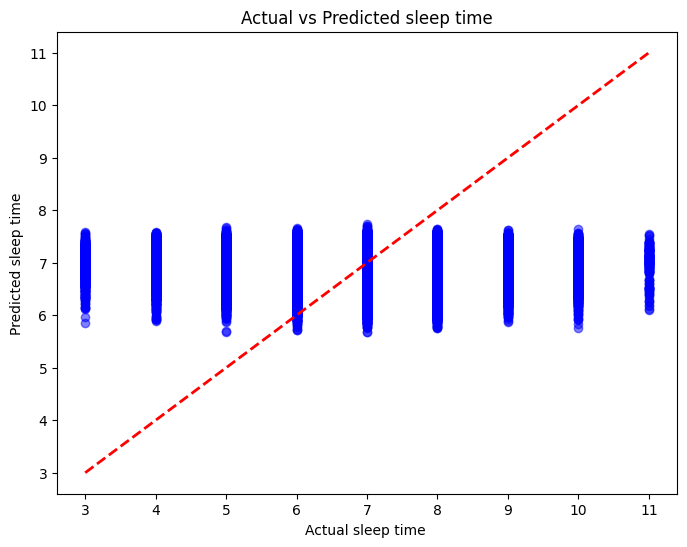

In [43]:
plt.figure(figsize=(8,6))
plt.scatter(y_testsl, y_predsl, alpha=0.5, color='blue')
plt.plot([y_testsl.min(), y_testsl.max()], [y_testsl.min(), y_testsl.max()], 'r--', linewidth=2)
plt.xlabel("Actual sleep time ")
plt.ylabel("Predicted sleep time")
plt.title("Actual vs Predicted sleep time")
plt.show()

##***K-Fold Cross-Validation***

---

###Instead of training the model once and testing it on a single test split, the data is divided into K equal parts (folds). The model is trained K times, and each time a different fold is used as the test set while the remaining folds are used for training.

### using k-Fold would help to improve the performance

In [44]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)


scores = cross_val_score(reg_modelsl,X_pca, ysl, cv=kf, scoring='r2')

print(f"R2 for each fold: {scores}")

average_accuracy = np.mean(scores)
print(f"Average R2: {average_accuracy:.2f}")

R2 for each fold: [0.05002412 0.05384926 0.05629008 0.05380857 0.05601248 0.05247532
 0.0520132  0.04940045 0.04943925 0.05429469]
Average R2: 0.05


##***New PCA with another Goal Weight2***

---



In [45]:

columnsdel = ['weight2', 'wtkg3']

X3= df_reduced.drop(columns=columnsdel, errors='ignore')

scaler3 = StandardScaler()
X_scaled3 = scaler3.fit_transform(X3)

pca3 = PCA(n_components=0.95)
X_pca3 = pca3.fit_transform(X_scaled3)

joblib.dump(scaler3, 'scaler3.pkl')
joblib.dump(pca3, "pca.pkl")


['pca.pkl']

##***Measuring accuray with "Weight" Goal***

---

###**It's give a great accuracy compare with sleptim1**

In [46]:
yw= df_reduced['weight2']

Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_pca3, yw, test_size=0.2, random_state=42
)

modelw = LinearRegression()
modelw.fit(Xw_train, yw_train)

y_predw = modelw.predict(Xw_test)

#counting score of training phase
y_pred_trwe=modelw.predict(Xw_train)
r2_train_we = r2_score(yw_train, y_pred_trwe)


print("R2 score for training :", r2_train_we)
print("R2 score for Generalizing:", r2_score(yw_test, y_predw))
print('Mean Squared Error of linear regreesion model(sleep):',mean_squared_error(yw_test, y_predw) )
print('Mean Absolute Error of linear regreesion model(sleep):',mean_absolute_error(yw_test, y_predw))


R2 score for training : 0.7123581242957988
R2 score for Generalizing: 0.7135526245766295
Mean Squared Error of linear regreesion model(sleep): 404.29289889339725
Mean Absolute Error of linear regreesion model(sleep): 14.489876225896198


##***K-Fold***

---

### with new goal "weight", implement cross validation to improve performance

In [47]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)

scores = cross_val_score(modelw,X_pca3, yw, cv=kf, scoring='r2')

print(f"R2 for each fold: {scores}")

average_accuracy = np.mean(scores)
print(f"Average R2: {average_accuracy:.2f}")

R2 for each fold: [0.71455996 0.71251549 0.71495898 0.7124615  0.7105867  0.7105749
 0.71007944 0.71327778 0.71087832 0.71469717]
Average R2: 0.71


##***ploting values of predicted and actual values***

---



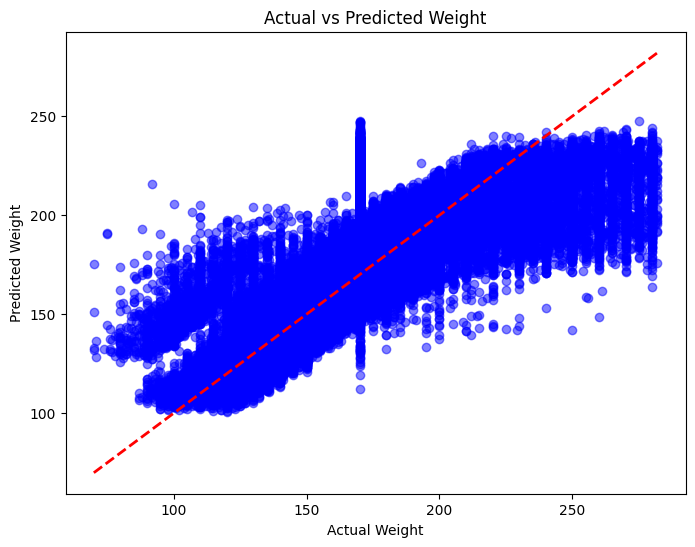

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(yw_test, y_predw, alpha=0.5, color='blue')
plt.plot([yw_test.min(), yw_test.max()], [yw_test.min(), yw_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Weight")
plt.ylabel("Predicted Weight")
plt.title("Actual vs Predicted Weight")
plt.show()


##***New PCA with another Goal 'X_vegesum'***

---



In [49]:
columnsde2 = ['X_vegesum']

X4= df_reduced.drop(columns=columnsde2, errors='ignore')

scaler4 = StandardScaler()
X_scaled4 = scaler4.fit_transform(X4)

pca4 = PCA(n_components=0.95)
X_pca4 = pca4.fit_transform(X_scaled4)

joblib.dump(scaler4, 'scaler3.pkl')
joblib.dump(pca4, "pca.pkl")


['pca.pkl']

##***Measuring accuray with "X_vegesum" Goal***

---

###**It's give a good accuracy compare with sleptim1**

In [50]:
yv = df_reduced['X_vegesum']

Xv_train, Xv_test, yv_train, yv_test = train_test_split(
    X_pca4, yv, test_size=0.2, random_state=42
)

modelv = LinearRegression()
modelv.fit(Xv_train, yv_train)

y_predv = modelv.predict(Xv_test)

#counting score of training phase
y_pred_trv=modelv.predict(Xv_train)
r2_train_veg = r2_score(yv_train, y_pred_trv)


print("R2 score for training :", r2_train_veg)
print("R2 score for Generlizing:", r2_score(yv_test, y_predv))
print('Mean Squared Error of linear regreesion model(X_vegesum):',mean_squared_error(yv_test, y_predv) )
print('Mean Absolute Error of linear regreesion model(X_vegesum):',mean_absolute_error(yv_test, y_predv))

R2 score for training : 0.6346771227179058
R2 score for Generlizing: 0.6345338893025715
Mean Squared Error of linear regreesion model(X_vegesum): 2779.729935042097
Mean Absolute Error of linear regreesion model(X_vegesum): 34.02322999402281


##***K-Fold***

---

### with new goal "X_vegesum", implement cross validation to improve performance

In [51]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)

scores = cross_val_score(modelv,X_pca4, yv, cv=kf, scoring='r2')

print(f"R2 for each fold: {scores}")

average_accuracy = np.mean(scores)
print(f"Average R2: {average_accuracy:.2f}")

R2 for each fold: [0.63453638 0.63452592 0.63428462 0.63672977 0.63501232 0.63195689
 0.63412292 0.63431731 0.63607487 0.63349163]
Average R2: 0.63


##***ploting values of predicted and actual values***

---


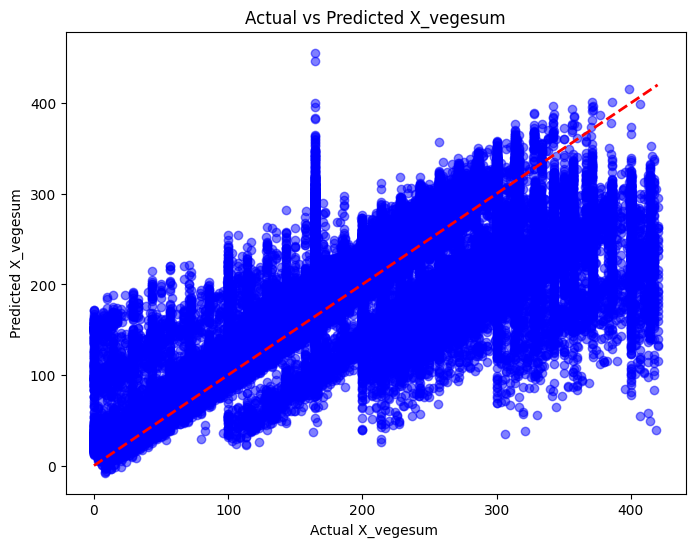

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(yv_test, y_predv, alpha=0.5, color='blue')
plt.plot([yv_test.min(), yv_test.max()], [yv_test.min(), yv_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual X_vegesum ")
plt.ylabel("Predicted X_vegesum")
plt.title("Actual vs Predicted X_vegesum")
plt.show()


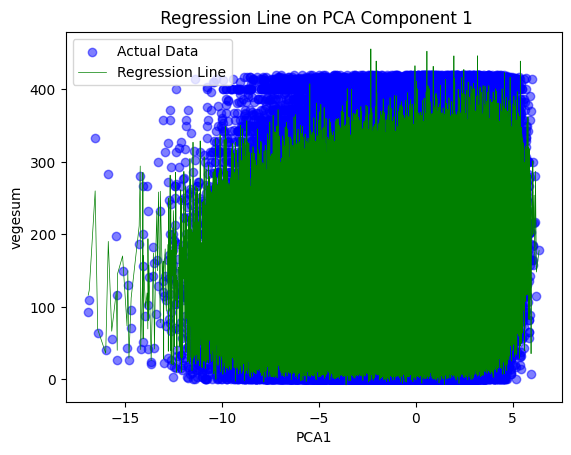

In [53]:
Xv = X_pca4[:, 0]
y_pred_fullv= modelv.predict(X_pca4)
sorted_idxv = np.argsort(Xv)
plt.scatter(Xv, yv, color='blue', alpha=0.5, label='Actual Data')
plt.plot(Xv[sorted_idxv], y_pred_fullv[sorted_idxv], color='green', linewidth=0.5, label='Regression Line')
plt.xlabel("PCA1")
plt.ylabel("vegesum")
plt.title(" Regression Line on PCA Component 1")
plt.legend()
plt.show()

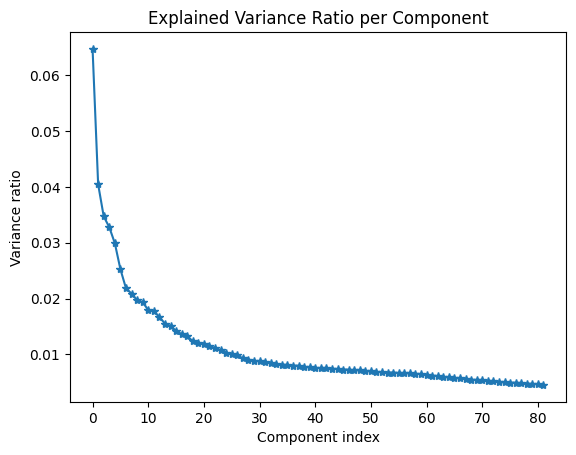

In [54]:
plt.plot(pca.explained_variance_ratio_, marker = '*')
plt.xlabel("Component index")
plt.ylabel("Variance ratio")
plt.title("Explained Variance Ratio per Component")
plt.show()

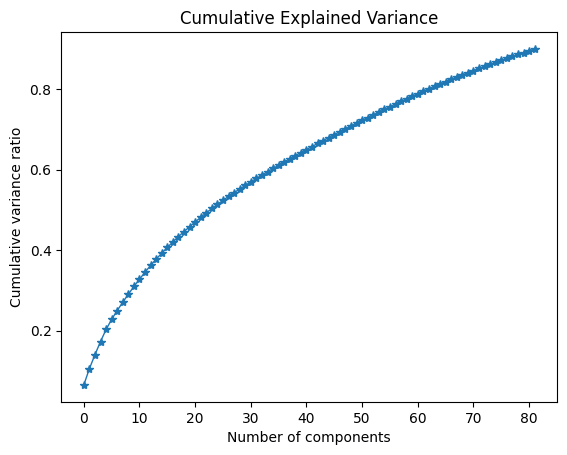

In [55]:
plt.plot(pca.explained_variance_ratio_.cumsum(), marker="*", linewidth=1)
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance ratio")
plt.title("Cumulative Explained Variance")
plt.show()

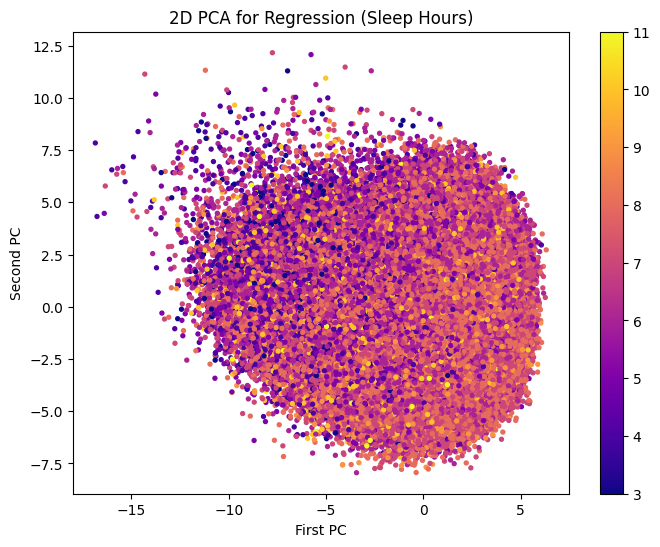

In [56]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0],  #First PC
            X_pca[:,1],   #Second PC
            c = df_reduced['sleptim1'],
            cmap='plasma',
            alpha = 1,
            s = 8
            )

plt.xlabel("First PC")
plt.ylabel("Second PC")
plt.title("2D PCA for Regression (Sleep Hours)")
plt.colorbar()

In [57]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_scaled)


PCA()

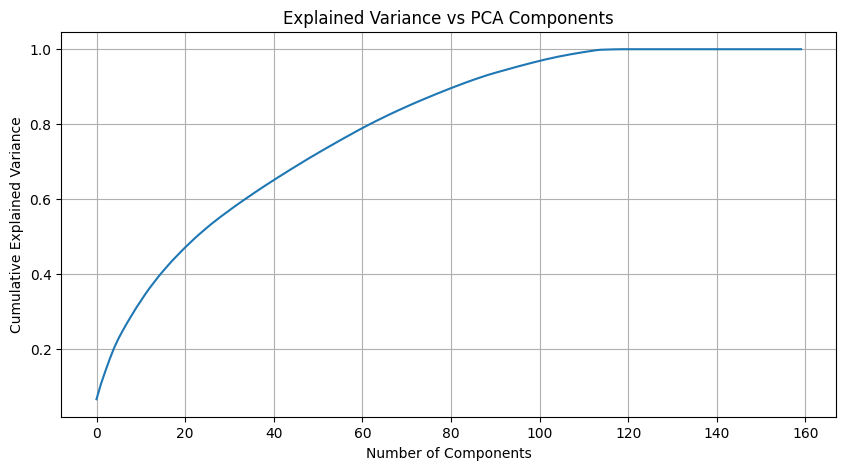

In [58]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs PCA Components')
plt.grid()
plt.show()


##***PCA for Classification.***

---



In [59]:
#PCA for Classification
X_1= df_reduced.copy()
targets1 = ['diabete3_encoded']
X_1 = df_reduced.drop(columns=targets, errors='ignore')

scaler1 = StandardScaler()
X1_scaled = scaler.fit_transform(X_1)


pca1 = PCA(n_components=0.95)
X_pca1 = pca1.fit_transform(X1_scaled)

joblib.dump(pca1, "pca.pkl")
joblib.dump(scaler1, "scaler.pkl")

['scaler.pkl']

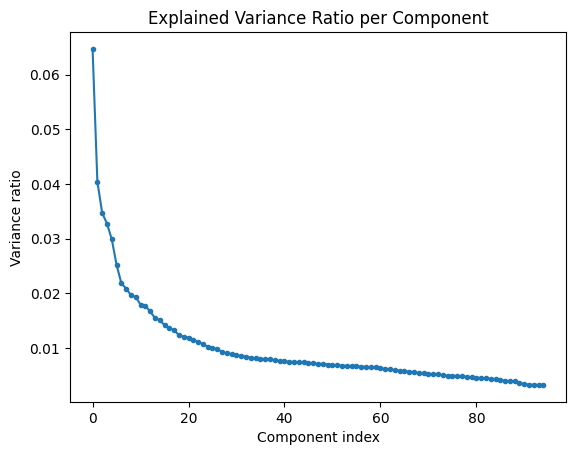

In [60]:
plt.plot(pca1.explained_variance_ratio_, marker = '.')
plt.xlabel("Component index")
plt.ylabel("Variance ratio")
plt.title("Explained Variance Ratio per Component")
plt.show()

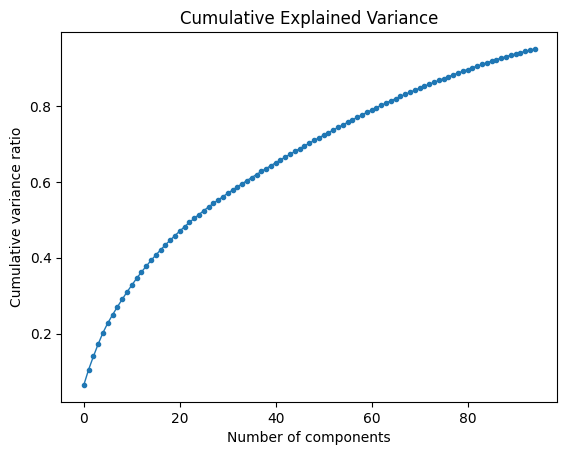

In [61]:
plt.plot(pca1.explained_variance_ratio_.cumsum(), marker=".", linewidth=1)
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance ratio")
plt.title("Cumulative Explained Variance")
plt.show()

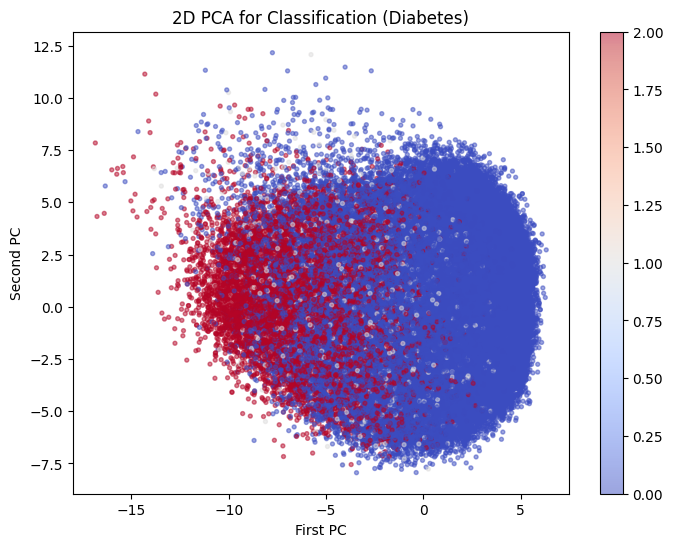

In [62]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca1[:,0],  #First PC
            X_pca1[:,1],   #Second PC
            c = df_reduced['diabete3_encoded'],
            cmap='coolwarm',
            alpha = 0.5,
            s = 8
            )

plt.xlabel("First PC")
plt.ylabel("Second PC")
plt.title("2D PCA for Classification (Diabetes)")
plt.colorbar()

In [63]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# **Classification Model (Decision Tree)**

In [64]:
#Decision Tree
y_classi = df_reduced['diabete3_encoded']
xtr, xte, ytr, yte = train_test_split(X_pca1, y_classi, random_state = 42, stratify = y_classi)

dt = DecisionTreeClassifier(max_depth=7, random_state = 42)

import time

start_time_dt = time.time()
dt.fit(xtr, ytr)
end_time_dt = time.time()
dt_train_time = end_time_dt - start_time_dt
print('training time:',dt_train_time)

y_pred_dt = dt.predict(xte)

training time: 64.77836203575134


Decision Tree Accuracy: 0.9813817673086934

Classification Report:
               precision    recall  f1-score   support

Non-Diabetic       0.99      0.99      0.99    104052
     At-Risk       0.68      0.78      0.72      3301
    Diabetic       0.99      0.94      0.96     15591

    accuracy                           0.98    122944
   macro avg       0.88      0.90      0.89    122944
weighted avg       0.98      0.98      0.98    122944



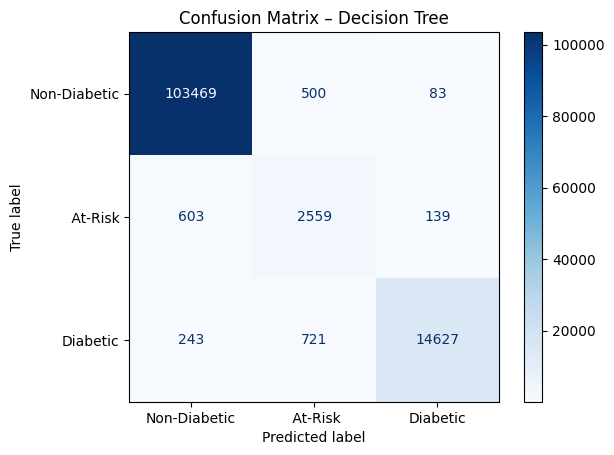

In [65]:
#  Accuracy & report
from sklearn.metrics import  classification_report
print("Decision Tree Accuracy:", accuracy_score(yte, y_pred_dt))
print("\nClassification Report:\n", classification_report(yte, y_pred_dt, target_names=['Non-Diabetic', ' At-Risk' ,'Diabetic']))

#Confusion Matrix
cm = confusion_matrix(yte, y_pred_dt)
dis = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels= ['Non-Diabetic', ' At-Risk' ,'Diabetic'])
dis.plot(values_format='d', cmap='Blues')
plt.title("Confusion Matrix – Decision Tree")
plt.show()

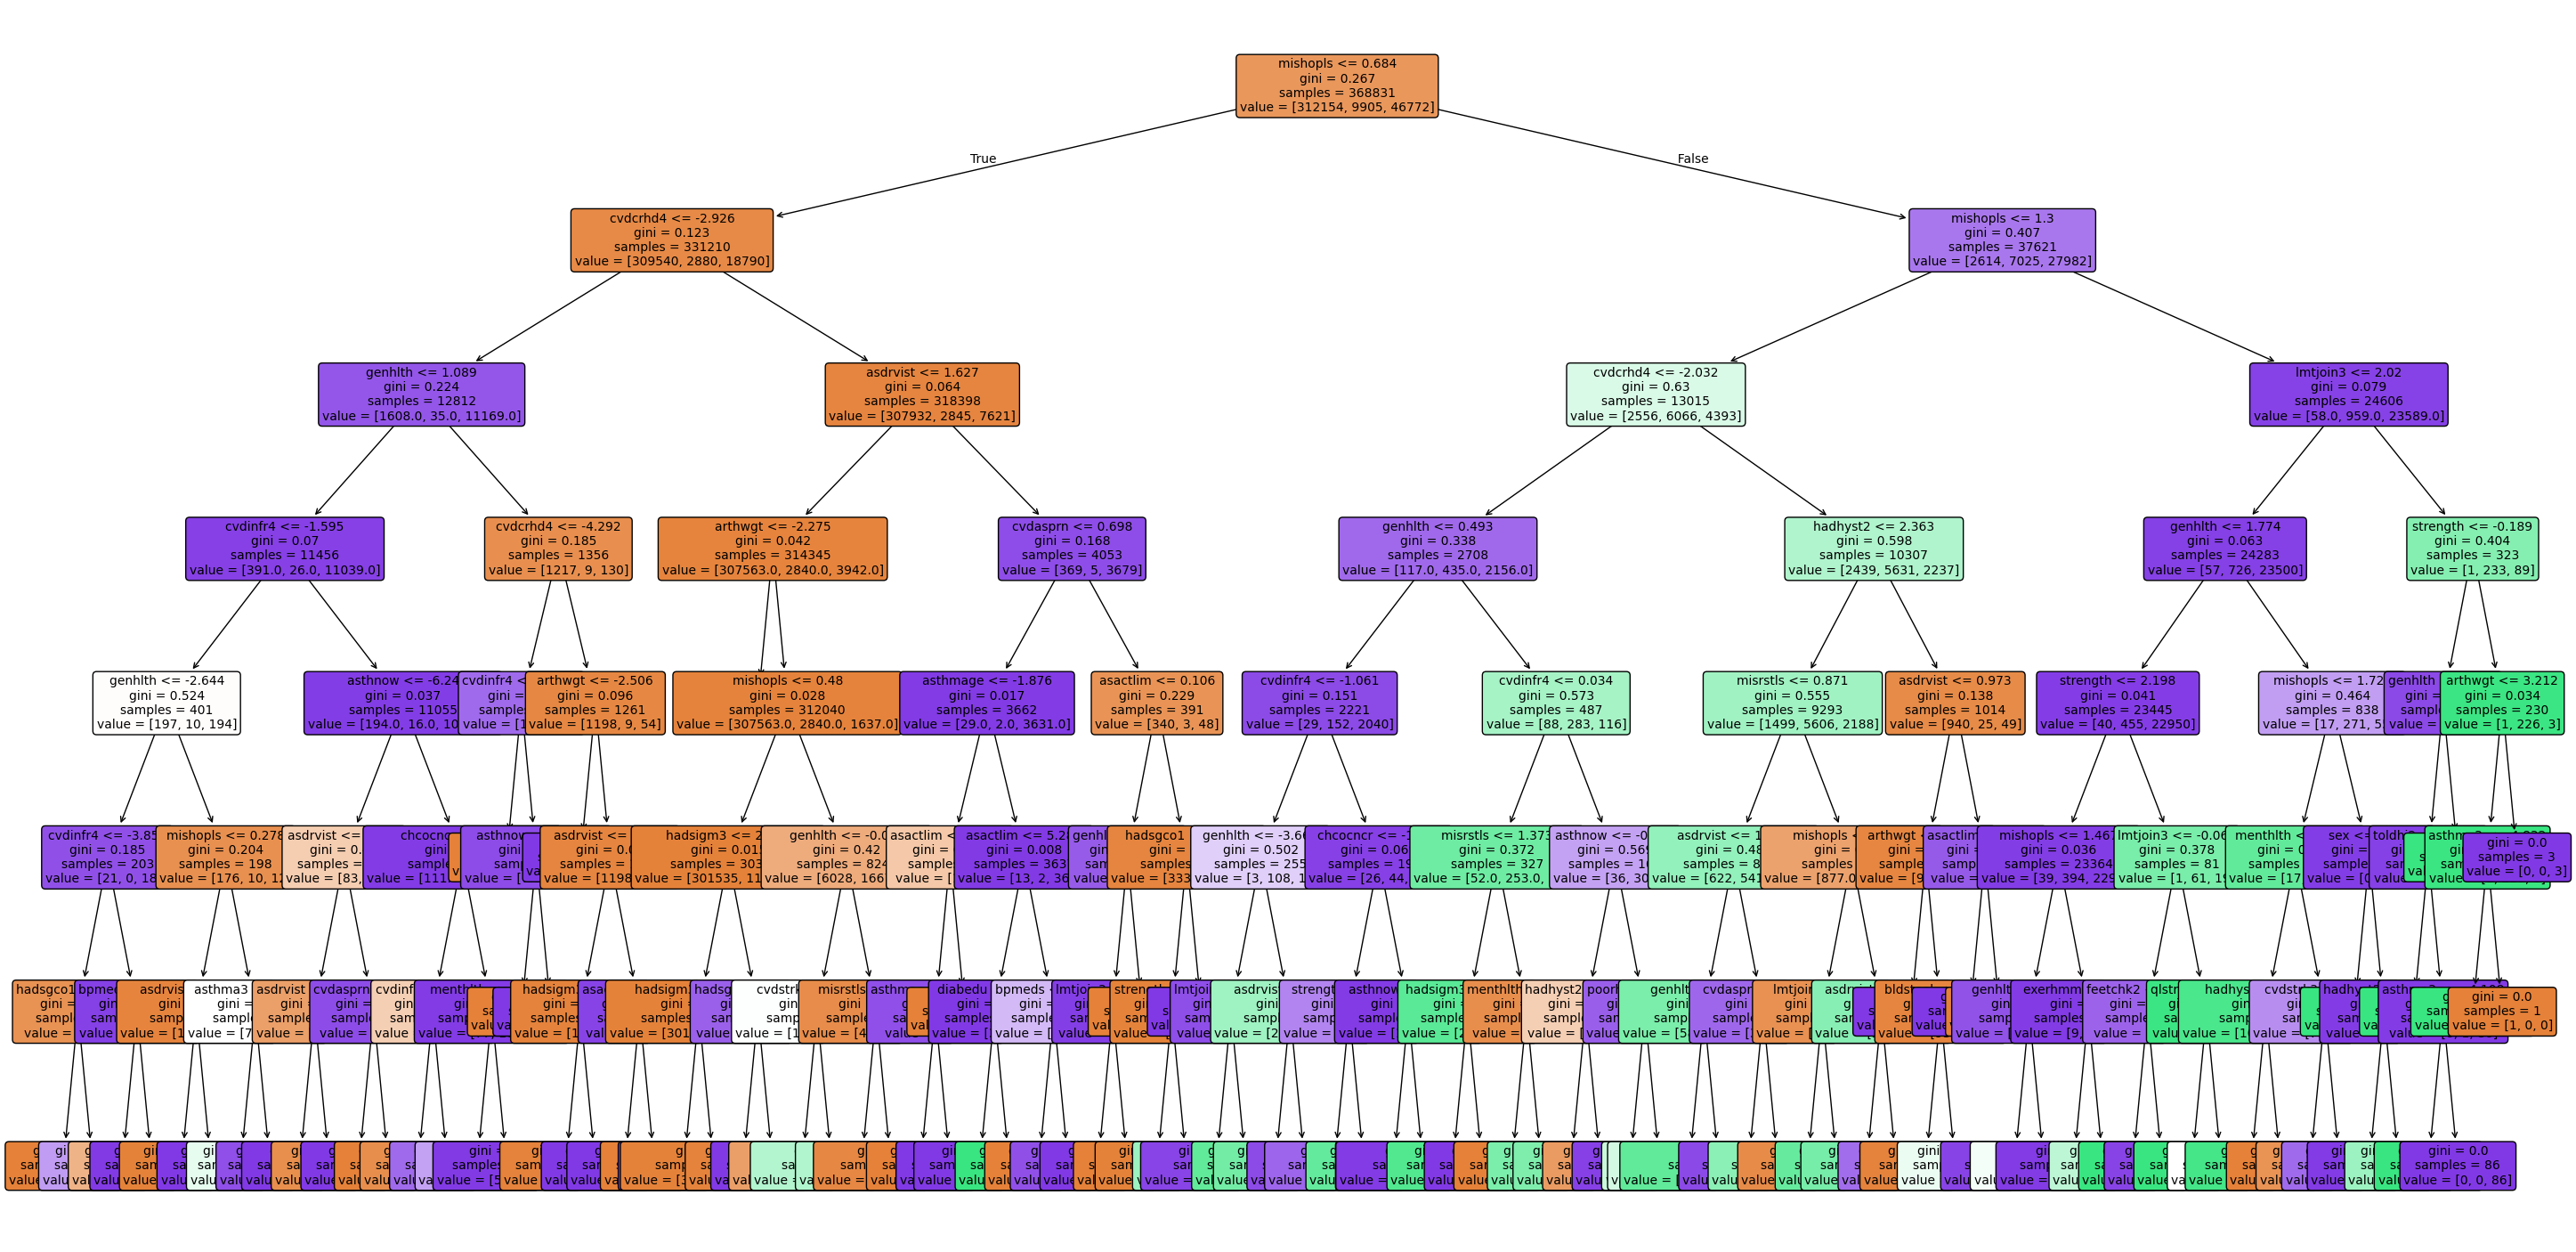

In [66]:
#Visualize the tree
plt.figure(figsize=(36,18))
plot_tree(dt,
          feature_names=X.columns,
          filled=True,
          rounded=True,
          fontsize=10)
plt.show()

In [67]:
importances = dt.feature_importances_
indices = np.argsort(importances)[::-1]
top_10_indices = indices[:10]
for i in top_10_indices:
    print(f'Feature: {X.columns[i]}, Importance: {importances[i]}')

Feature: mishopls, Importance: 0.5520993593549945
Feature: cvdcrhd4, Importance: 0.21266050301138242
Feature: asdrvist, Importance: 0.08108958310428649
Feature: arthwgt, Importance: 0.051598454831045026
Feature: genhlth, Importance: 0.041426893390463106
Feature: misrstls, Importance: 0.011177160265155632
Feature: hadsigm3, Importance: 0.010745205396945286
Feature: hadhyst2, Importance: 0.010203565240424284
Feature: cvdasprn, Importance: 0.0074787001643571655
Feature: lmtjoin3, Importance: 0.004460540461584921


# Extra Classification Model - Random Forest

Random forest contain dozens of trees built using  **bootstrapped datasets**

✳ **bootstrapped dataset** is a dataset extracted from original dataset with the same number of sampels but randomly selected (some samples may be duplicated and some may not included) and also using a subset of features

these bootstrapped datasets generlize the model better, and since the detiels of each one are slightly different this help avoid overfitting

*each bootstrapped dataset builds one tree* 🌳

---





let's have 100 trees, a point will be predicted by all of tress, each tree predicts a class

the most common class will be the final prediction for that point

In [68]:
#Random forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=7,
    random_state=42,
    class_weight = 'balanced'
)

start_time_rf = time.time()
rf.fit(xtr, ytr)
end_time_rf = time.time()

rf_train_time = end_time_rf - start_time_rf
y_pred_rf = rf.predict(xte)

test accuracy:  0.9608927641853201
Classification Report:
               precision    recall  f1-score   support

Non-Diabetic       1.00      0.96      0.98    104052
     At-Risk       0.41      0.95      0.57      3301
    Diabetic       0.99      0.98      0.98     15591

    accuracy                           0.96    122944
   macro avg       0.80      0.96      0.84    122944
weighted avg       0.98      0.96      0.97    122944



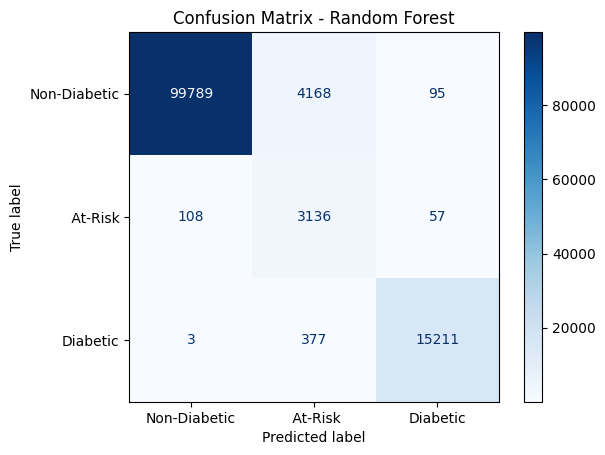

In [69]:
#Accuracy - Random forest
rf_acc = accuracy_score(yte, y_pred_rf)
print('test accuracy: ', rf_acc)
print("Classification Report:\n", classification_report(yte, y_pred_rf, target_names=['Non-Diabetic', ' At-Risk' ,'Diabetic']))

#Confusion Matrix - Random forest
cm_rf = confusion_matrix(yte, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix = cm_rf, display_labels= ['Non-Diabetic', ' At-Risk' ,'Diabetic'])
disp.plot(values_format='d', cmap='Blues')
plt.title("Confusion Matrix - Random Forest")
plt.show()

# Extra Classification Model - XGBoost

Second extra model is XGBoost ! ! !

XGBoost also contians dozens of trees (but unlike random forest where the trees are seperated)

in XGBoost each tree depends on the previous tree and tries to fix its mistakes ( this is called boosting ! ! )  - making a series of trees each one gives a small improvement step by step

learning rate determines how small each step is

In [70]:
#XGBoost
import xgboost as xgb
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=100, #number of trees
    max_depth= 5,
    learning_rate=0.05, #determines how small each step is
    subsample=0.7, #randomly select 70% of samples in each tree
    colsample_bytree=0.7, #randomly select 70% of features in each tree
    random_state=42
    )

start_time_xgb = time.time()
xgb.fit(xtr, ytr)
end_time_xgb = time.time()
xgb_train_time = end_time_xgb - start_time_xgb

y_pred_xgb = xgb.predict(xte)

Train Accuracy: 0.9944988355100304
Test Accuracy: 0.9940786048932847
Classification Report:
               precision    recall  f1-score   support

Non-Diabetic       1.00      1.00      1.00    104052
     At-Risk       0.96      0.83      0.89      3301
    Diabetic       0.99      0.99      0.99     15591

    accuracy                           0.99    122944
   macro avg       0.98      0.94      0.96    122944
weighted avg       0.99      0.99      0.99    122944



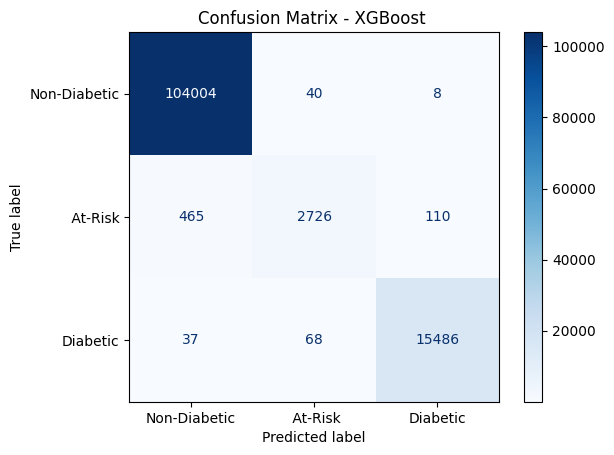

In [71]:
y_train_pred = xgb.predict(xtr)
print("Train Accuracy:", accuracy_score(ytr, y_train_pred))
print("Test Accuracy:", accuracy_score(yte, y_pred_xgb))
print("Classification Report:\n", classification_report(yte, y_pred_xgb, target_names=['Non-Diabetic', ' At-Risk' ,'Diabetic']))

#Confusion Matrix
cm_xgb = confusion_matrix(yte, y_pred_xgb)
displ = ConfusionMatrixDisplay(confusion_matrix = cm_xgb, display_labels= ['Non-Diabetic', ' At-Risk' ,'Diabetic'])
displ.plot(values_format='d', cmap='Blues')
plt.title("Confusion Matrix - XGBoost ")
plt.show()

# Comparison of Classification Models

**Training Time**

Training Times:
Decision tree: 1 min 4.78 sec
Random forest: 11 min 1.38 sec
XGBoost: 0 min 10.50 sec


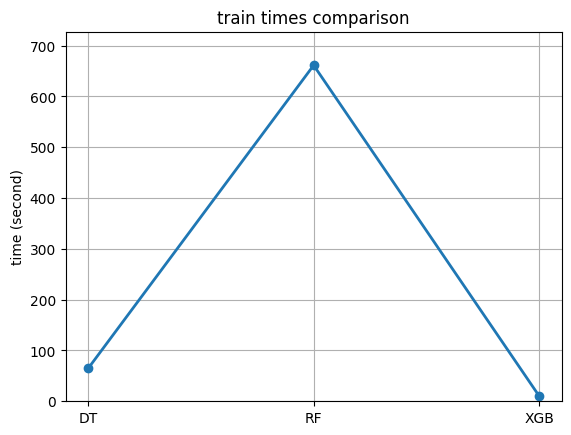

In [72]:
print('Training Times:')
print(f'Decision tree: {int(dt_train_time // 60)} min {dt_train_time % 60:.2f} sec')
print(f'Random forest: {int(rf_train_time // 60)} min {rf_train_time % 60:.2f} sec')
print(f'XGBoost: {int(xgb_train_time // 60)} min {xgb_train_time % 60:.2f} sec')

models = ['DT', 'RF', 'XGB']
train_times = [dt_train_time, rf_train_time, xgb_train_time]

plt.plot(models, train_times, marker='o', linewidth=2)
plt.ylabel('time (second)')
plt.title('train times comparison')
plt.ylim(0, max(train_times) * 1.1)
plt.grid(True)
plt.show()

**Performance**

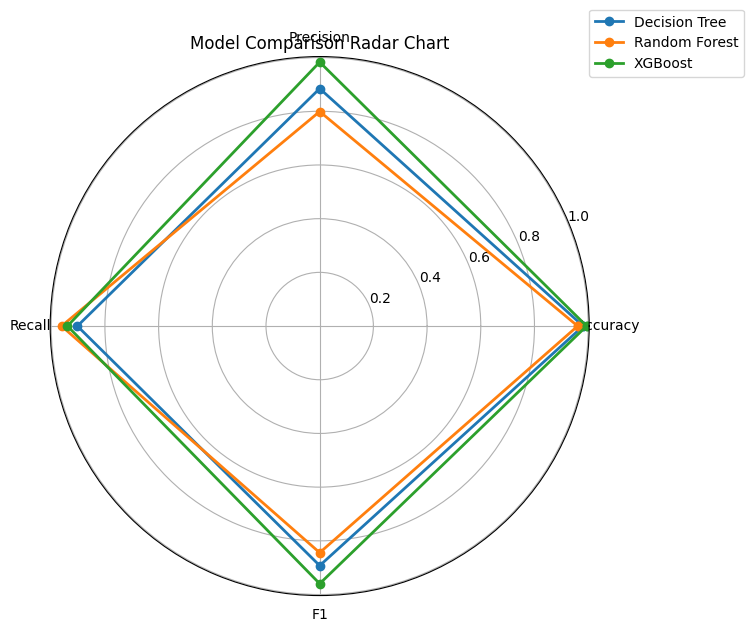

In [73]:
report_dt = classification_report(yte, y_pred_dt, output_dict=True)
report_rf = classification_report(yte, y_pred_rf, output_dict=True)
report_xgb = classification_report(yte, y_pred_xgb, output_dict=True)

# Extract metrics: Accuracy + macro avg
dt = [
    report_dt['accuracy'],
    report_dt['macro avg']['precision'],
    report_dt['macro avg']['recall'],
    report_dt['macro avg']['f1-score']
]

rf = [
    report_rf['accuracy'],
    report_rf['macro avg']['precision'],
    report_rf['macro avg']['recall'],
    report_rf['macro avg']['f1-score']
]

xgb = [
    report_xgb['accuracy'],
    report_xgb['macro avg']['precision'],
    report_xgb['macro avg']['recall'],
    report_xgb['macro avg']['f1-score']
]

# Radar plot
metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
data = np.array([dt, rf, xgb])

angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False).tolist()
data = np.concatenate((data, data[:, [0]]), axis=1)
angles += angles[:1]

plt.figure(figsize=(7,7))
for i, model in enumerate(['Decision Tree', 'Random Forest', 'XGBoost']):
    plt.polar(angles, data[i], marker='o', linewidth=2, label=model)

plt.xticks(angles[:-1], metrics)
plt.title("Model Comparison Radar Chart")
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

##***Extra Regression Model – Gradient Boosting***

---
3 ed  Extra model is Gradient Boosting.

 is an ensemble model that also uses many decision trees, but unlike Random Forest where trees are independent, Gradient Boosting builds the trees one after another.


Each new tree focuses on fixing the mistakes made by the previous trees — this step-by-step correction process is called boosting


So instead of making many strong trees, Gradient Boosting makes many small weak trees, and each one gives a small improvement.
By combining all of them together, we get one powerful model




***since sleep time goal doesn't have any linear relationship with others columns, so implemented nonlinear model that work efficency with noise would be perfect!***

In [74]:
ybost = df_reduced['sleptim1']

X_train, X_test, y_train, y_test = train_test_split(
    X_pca, ybost, test_size=0.25,random_state=42)


train_X, test_X, train_y, test_y = train_test_split(X_pca, y,
                                                    test_size = 0.25,
                                                    random_state = 42)

gbr = GradientBoostingRegressor(loss='squared_error',
                                learning_rate=0.1,
                                n_estimators=300,
                                max_depth = 1,
                                random_state = 42,
                                max_features = 5)

gbr.fit(train_X, train_y)
pred_y = gbr.predict(test_X)
r2bost = r2_score(test_y, pred_y)

print("R² Score:", r2bost)

R² Score: 0.04213856116893122


##***Extra Classification Model – K-Nearest Neighbors (KNN)***

---
fourth Extra models K-Nearest Neighbors.
it is one of the simplest and most intuitive classification models!
Instead of learning complex rules, KNN simply looks at the closest points (neighbors) in the training data and predicts the class based on the majority vote.



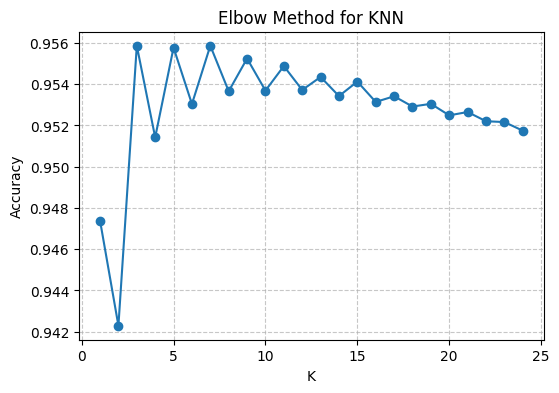

In [75]:
#The Elbow Method tests multiple K values and plots their accuracies.
#We look for the point where increasing K no longer gives a big improvement

y_classi = df_reduced['diabete3_encoded']
X = X_pca1

X_train, X_test, y_train, y_test = train_test_split(
    X, y_classi, test_size=0.2, random_state=42
)

accuracies = []
k_values = range(1, 25)

for k in k_values:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))

plt.figure(figsize=(6,4))
plt.plot(k_values, accuracies, marker='o')
plt.title("Elbow Method for KNN")
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

KNN Accuracy: 0.956

Classification Report (k-NN):

              precision    recall  f1-score   support

           0       0.95      1.00      0.98     83199
           1       0.59      0.06      0.11      2735
           2       0.99      0.86      0.92     12421

    accuracy                           0.96     98355
   macro avg       0.85      0.64      0.67     98355
weighted avg       0.95      0.96      0.94     98355



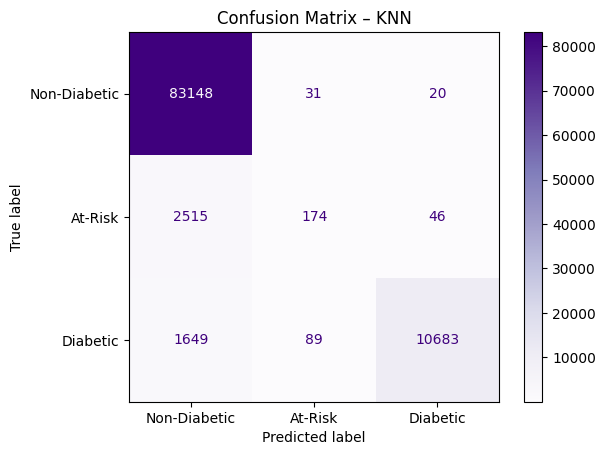

In [76]:
#here after show the plot, best value for k is 5
best_k = 5

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

acc_knn = accuracy_score(y_test, y_pred_knn)
print(f"KNN Accuracy: {acc_knn:.3f}")

print("\nClassification Report (k-NN):\n")
print(classification_report(y_test, y_pred_knn))

cm_knn = confusion_matrix(y_test, y_pred_knn)
ConfusionMatrixDisplay(cm_knn, display_labels= ['Non-Diabetic', 'At-Risk', 'Diabetic']).plot(cmap='Purples')
plt.title("Confusion Matrix – KNN")
plt.show()

#for k=9 -> KNN Accuracy: 0.920
#for k=7 -> KNN Accuracy: 0.921
#for k=5 -> KNN Accuracy: 0.923  best one
#for k=2 -> KNN Accuracy: 0.918

# ***UnsuperVised model (K-means) - Shatha Ghabban***

In [77]:
#!pip install pandas matplotlib datashader bokeh holoviews scikit-image colorcet umap-learn

In [78]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch
from sklearn.metrics import davies_bouldin_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
import umap.umap_ as umap
import umap.plot as umap_plot

In [79]:
#create a copy of the orignal dataset
copy=df_reduced.copy()

In [80]:
#save the coulmns's names
coulmnsP=copy.columns

In [81]:
#We applied feature scaling to avoid misinterpreting feature importance
scaler = StandardScaler()
features_scaled = scaler.fit_transform(copy)

In [82]:
#We applied UMAP to focus on studying the relationships within the data
#We utilized UMAP for dimensionality reduction and visualization
UMl = umap.UMAP(random_state=42)
umapModel = UMl.fit_transform(features_scaled)

In [83]:
umapModel.shape

(491775, 2)

In [84]:
#we use the Elbow method to find the bset K- cluster

inertia=[]
k= range(1,10)

for i in k:
  kmodel=KMeans(n_clusters=i ,random_state=42)
  kmodel.fit(umapModel)
  inertia.append(kmodel.inertia_)

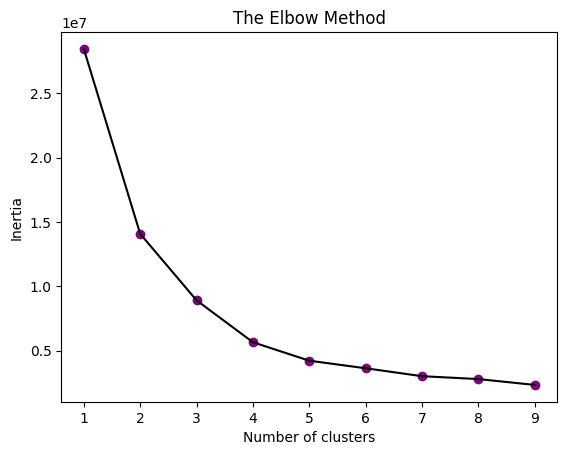

In [85]:
# we plot the Elbow graph

plt.plot(k,inertia, color='black')
plt.scatter(k,inertia,color='purple')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('The Elbow Method')
plt.show()

In [86]:
# as we can see the bset k- cluster is between 2 and 4 , and we are going with 3

kmeansModel=KMeans(n_clusters=3,random_state=42)
kmeansModel.fit(umapModel)


KMeans(n_clusters=3, random_state=42)

In [87]:
#we calucate the score by using silhouette_score
#we choose the best clusters based on the maximum accuracy

score = silhouette_score(umapModel, kmeansModel.labels_)
score= round(score,2)
score

np.float32(0.52)

 davies bouldin score of k-means

---



In [88]:
print("Davies-Bouldin Index: ", davies_bouldin_score(umapModel,kmeansModel.labels_))

Davies-Bouldin Index:  0.7801600288586906


In [89]:
#we store the clustring result in the dataset

copy['cluster']=kmeansModel.labels_
copy['cluster']

,cluster
0,0
1,0
2,1
3,0
4,1
...,...
491770,0
491771,0
491772,1
491773,0


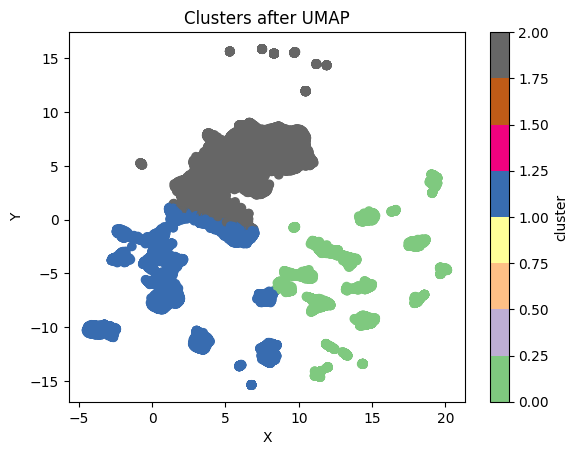

In [90]:
#plotting the clusters based on UMAP on featsures

plt.scatter(umapModel[:,0], umapModel[:,1], c=copy['cluster'], cmap='Accent')
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Clusters after UMAP")
plt.colorbar(label='cluster')

<Axes: >

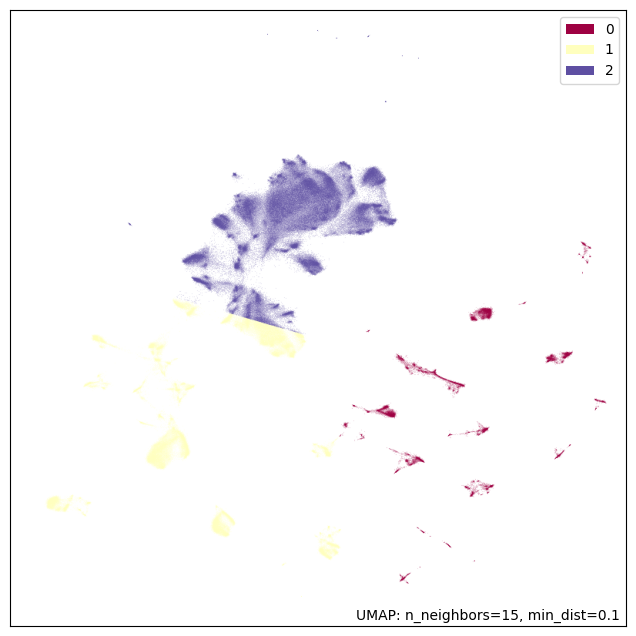

In [91]:
#We applied UMAP for visualization
umap_plot.points( UMl, labels=copy['cluster'])

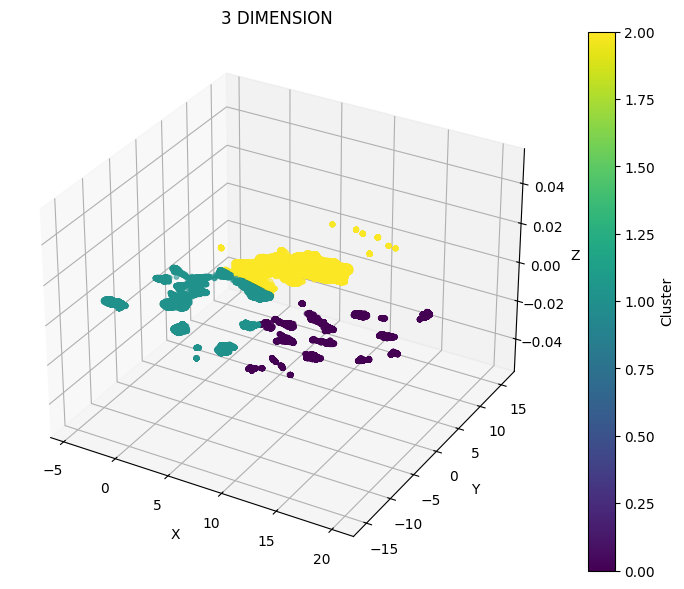

In [92]:
#3D plotting
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(
    umapModel[:, 0],
    umapModel[:, 1],

    c=kmeansModel.labels_,
    cmap='viridis',
    s=10
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.title("3 DIMENSION ")
plt.colorbar(sc, label='Cluster')

#Visualize k-means of healthy and unhealthy

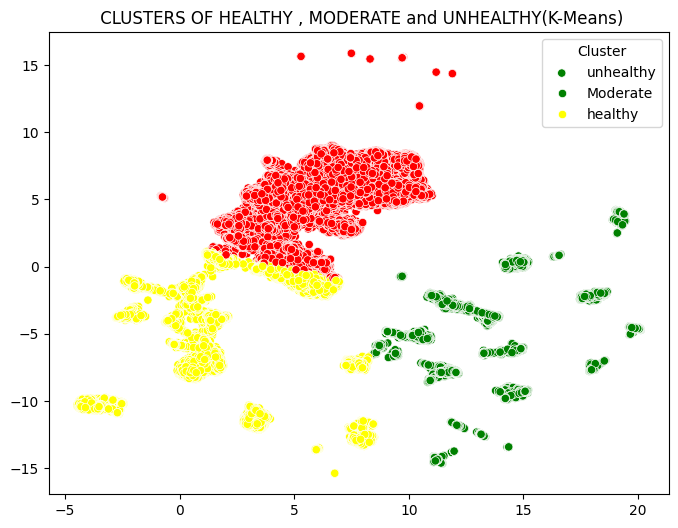

In [93]:
#vaisualiztion of clusters healthy AND unhealthy
plt.figure(figsize=(8, 6))
sns.scatterplot(x=umapModel[:, 0],y= umapModel[:, 1], hue=copy["cluster"], palette={0:"green", 1:"yellow",2:"red"})
plt.title(" CLUSTERS OF HEALTHY , MODERATE and UNHEALTHY(K-Means)")
plt.legend(title="Cluster", labels=["unhealthy","Moderate","healthy"])


In [94]:
# mean of original features per cluster
cluster_summary = copy.groupby('cluster').mean()
cluster_summary

,genhlth,physhlth,menthlth,poorhlth,sleptim1,bphigh4,bpmeds,bloodcho,toldhi2,cvdinfr4,...,X_rfhlth_encoded,X_drdxar1_encoded,X_totinda_encoded,X_paindx1_encoded,X_pastrng_encoded,checkup1_enc,cholchk_enc,eyeexam_enc,asnoslep_enc,diabete3_encoded
cluster,,,,,,,,,,,,,,,,,,,,,
0,2.128068,0.685680,0.473626,0.0,6.904347,0.935933,0.928691,0.856122,0.389125,0.077175,...,0.708599,0.399268,0.680245,0.499229,0.220523,1.655370,1.746996,1.928608,0.000033,0.483619
1,2.231659,0.671246,0.445224,0.0,6.955171,0.921382,0.943554,0.882863,0.404194,0.069648,...,0.754394,0.375330,0.523744,0.403074,0.193412,1.669823,1.732766,1.927576,0.000000,0.399185
2,2.599010,0.572359,0.417313,0.0,7.040457,0.776781,0.930046,0.884025,0.352329,0.050070,...,0.858648,0.299958,0.883017,0.688836,0.276749,1.654414,1.695127,1.997342,0.001221,0.169971


In [95]:
#printing out the most 10 effecting featsures based on each PCs
for cluster_label in cluster_summary.index:
    print(f"\nTop {10} features for cluster {cluster_label}:")
    print(cluster_summary.loc[cluster_label].abs().nlargest(10))


Top 10 features for cluster 0:
hivtstd3    92009.000000
wtkg3        7998.101238
pafreq1_     3177.362693
maxvo2_      2919.917522
pafreq2_     2000.000000
height3       505.659182
strfreq_      489.521486
longwtch      406.000000
fvbeans       238.804103
fvorang       238.762325
Name: 0, dtype: float64

Top 10 features for cluster 1:
hivtstd3    92009.000000
wtkg3        7899.993431
pafreq1_     3147.671195
maxvo2_      2802.398913
pafreq2_     2000.000000
height3       505.629239
strfreq_      428.871059
longwtch      406.000000
fvbeans       241.364652
fvorang       241.035445
Name: 1, dtype: float64

Top 10 features for cluster 2:
hivtstd3    92009.000000
wtkg3        7786.142894
pafreq1_     3263.817985
maxvo2_      2872.000264
pafreq2_     2000.000000
strfreq_      623.283823
height3       505.864975
longwtch      406.000000
fvbeans       239.739278
fvorang       236.876777
Name: 2, dtype: float64


In [96]:
#mapping names of the clusters
copy['cluster']=copy['cluster'].map({0:'healthy' ,
 1:'Moderate',
 2:'unhealthy'})

In [97]:
copy['cluster']

,cluster
0,healthy
1,healthy
2,Moderate
3,healthy
4,Moderate
...,...
491770,healthy
491771,healthy
491772,Moderate
491773,healthy


# ***Unsupervised Model (Hierarchical Clustering) - Shatha Ghabban***



In [98]:
#we determine the number of clusters based on the dendrogram , and we can notice it's 3
#dendrogram = sch.dendrogram(sch.linkage(DF_PCA, method='ward'))
#plt.title("Dendrogram")

In [99]:
#using Euclidean distance and Ward linkage to minimize variance within clusters
#ward: inside the cluster itself , minimizes variance inside the cluster itself
#Euclidean: distance between the points
#hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
#y_hc = hc.fit_predict(DF_PCA)

In [100]:
#df_reduced['Hierarchical_Cluster'] = y_hc

In [101]:
#hc_score = silhouette_score(DF_PCA, y_hc)
#hc_score

In [102]:
#df_reduced['Hierarchical_Cluster']

In [103]:
#pc_cluster_H_summary = pd.DataFrame(DF_PCA, ).groupby(df_reduced['Hierarchical_Cluster']).mean()
#pc_cluster_H_summary

In [104]:
#we can notice the difference in the ratios representing stress and sleep
#Hcluster_summary = df_reduced.groupby('Hierarchical_Cluster').mean(numeric_only=True)
#Hcluster_summary

In [105]:
'''sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Hierarchical_Cluster',
    data=df_reduced,
    palette='bright',
    s=100
)
plt.legend(title="Cluster", labels=["unhealthy","healthy","Stressed"])

plt.title('Hierarchical Clustering Results')'''

'sns.scatterplot(\n    x=\'PC1\',\n    y=\'PC2\',\n    hue=\'Hierarchical_Cluster\',\n    data=df_reduced,\n    palette=\'bright\',\n    s=100\n)\nplt.legend(title="Cluster", labels=["unhealthy","healthy","Stressed"])\n\nplt.title(\'Hierarchical Clustering Results\')'

#exsrta-DBSCAN - abrar almutiri

In [106]:
from sklearn.cluster import DBSCAN

In [107]:
#create a copy of the orignal dataset
copy_of_orignal=df_reduced.copy()

In [108]:
#save the coulmns's names
coulmnsP=copy_of_orignal.columns

In [109]:
#scale features to avoid bias from varying encoding values alonge with applaying PCA

scl = StandardScaler()
dfS = scl.fit_transform(copy_of_orignal)


APCS = PCA(n_components=2)
DF_PCA = APCS.fit_transform(dfS)

In [110]:
df_pca_df = pd.DataFrame(DF_PCA)
dp = df_pca_df.sample(n=20000, random_state=42)

In [111]:
modeldbscan= DBSCAN(eps=3, min_samples=17)
ydbscan = modeldbscan.fit_predict(dp)

In [112]:
xd = silhouette_score(dp, modeldbscan.labels_)
xdo= round(xd,2)
xdo

np.float64(0.68)

In [113]:
np.unique(ydbscan)

array([-1,  0])

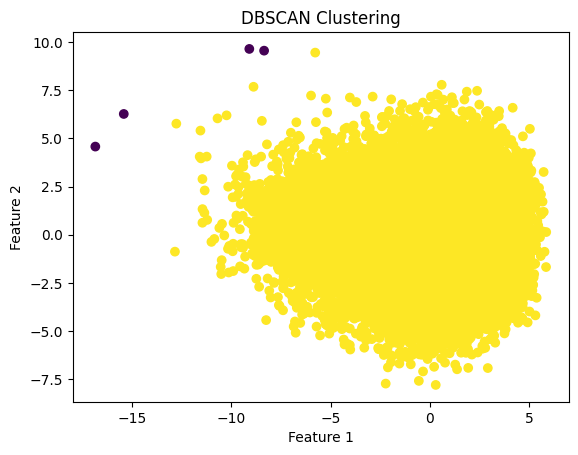

In [114]:
plt.scatter(dp.iloc[:, 0], dp.iloc[:, 1], c= ydbscan, cmap='viridis')
plt.title('DBSCAN Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

In [115]:
#xx= df_reduced.drop(columns=['cluster name'], errors='ignore')
#xx['cluster dbscan']=modeldbscan.labels_
#xx['cluster dbscan']

In [116]:
#cluster_summaryx = xx.groupby('cluster dbscan').mean()
#cluster_summaryx

In [117]:
# after seening means we found that -1 un health 0 health
'''wr=[]
for i in df_reduced['cluster dbscan']:
    if i==0:
      wr.append('healthy')
    else:
      wr.append('unhealthy')
df_reduced['cluster name dbscan']=wr
df_reduced['cluster name dbscan']'''


"wr=[]\nfor i in df_reduced['cluster dbscan']:\n    if i==0:\n      wr.append('healthy')\n    else:\n      wr.append('unhealthy')\ndf_reduced['cluster name dbscan']=wr\ndf_reduced['cluster name dbscan']"

In [118]:
#plt.figure(figsize=(8, 6))
#sns.scatterplot(x=DF_PCA[:,0], y=DF_PCA[:,1], hue=df_reduced["cluster dbscan"], palette={0:"green", -1:"red"})
#plt.title("CLUSTERS OF HEALTHY AND UNHEALTHY(DBSCAN)")
#plt.legend(title="Cluster", labels=["unhealthy","healthy"]) #0 healthy ,1 unhealthy
#plt.show()